In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.impute import SimpleImputer

sns.set(style="whitegrid", context="talk")

try:
    import umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False
    print("Warning: umap-learn is not installed. UMAP sections will be skipped.")

In [2]:
DATA_DIR = Path("../../results/processed_hrv")
INPUT_FILE = DATA_DIR / "basal_v2_clean_with_categories.csv"

FIG_DIR = Path("../../results/multivariate_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

TABLE_DIR = Path("../../results/multivariate_tables")
TABLE_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
df = pd.read_csv(INPUT_FILE)

print(df.shape)
df.head()

(530, 29)


,sex,age,weight_kg,height_cm_final,height_m_final,imc_final,bp_systolic,bp_diastolic,bp_pam,bp_pp,...,mean_hr_from_rr,height_inconsistent,imc_inconsistent,hr_rr_inconsistent,n_integrity_flags,n_range_flags,n_total_qc_flags,age_group,bmi_cat,bp_cat
0,1,75,70.0,160.0,1.60,27.343750,108,70,82.666667,38,...,80.213904,False,False,False,0,0,0,70-79,normal,normal
1,1,66,52.0,149.0,1.49,23.422368,122,72,88.666667,50,...,62.959077,False,False,False,0,0,0,60-69,normal,normal
2,2,77,81.0,170.0,1.70,28.027682,125,85,98.333333,40,...,68.415051,False,False,False,0,0,0,70-79,overweight,normal
3,1,77,85.0,160.0,1.60,33.203125,126,72,90.000000,54,...,73.260073,False,False,False,0,0,0,70-79,obesity,normal
4,1,73,69.0,151.0,1.51,30.261831,130,80,96.666667,50,...,70.921986,False,False,False,0,0,0,70-79,overweight,normal


In [4]:
hrv_cols = [
    "t2m_pre_mean_rr",
    "t2m_pre_mean_hr",
    "t2m_pre_sdnn",
    "t2m_pre_rmssd",
    "t2m_pre_hf",
    "t2m_pre_lf",
    "t2m_pre_vlf",
]

phys_cont_cols = [
    "age",
    "weight_kg",
    "height_m_final",
    "imc_final",
    "bp_systolic",
    "bp_diastolic",
    "bp_pam",
    "bp_pp",
]

phys_cat_cols = [
    "sex",
    "age_group",
    "bmi_cat",
    "bp_cat",
]

qc_cols = [
    "height_inconsistent",
    "imc_inconsistent",
    "hr_rr_inconsistent",
    "n_total_qc_flags",
]

existing_hrv = [c for c in hrv_cols if c in df.columns]
existing_phys_cont = [c for c in phys_cont_cols if c in df.columns]
existing_phys_cat = [c for c in phys_cat_cols if c in df.columns]
existing_qc = [c for c in qc_cols if c in df.columns]

existing_hrv, existing_phys_cont, existing_phys_cat

(['t2m_pre_mean_rr',
  't2m_pre_mean_hr',
  't2m_pre_sdnn',
  't2m_pre_rmssd',
  't2m_pre_hf',
  't2m_pre_lf',
  't2m_pre_vlf'],
 ['age',
  'weight_kg',
  'height_m_final',
  'imc_final',
  'bp_systolic',
  'bp_diastolic',
  'bp_pam',
  'bp_pp'],
 ['sex', 'age_group', 'bmi_cat', 'bp_cat'])

In [5]:
age_order = ["<60", "60-69", "70-79", "80+"]
bmi_order = ["low", "normal", "overweight", "obesity"]
bp_order = ["normal", "high"]

if "age_group" in df.columns:
    df["age_group"] = pd.Categorical(df["age_group"], categories=age_order, ordered=True)

if "bmi_cat" in df.columns:
    df["bmi_cat"] = pd.Categorical(df["bmi_cat"], categories=bmi_order, ordered=True)

if "bp_cat" in df.columns:
    df["bp_cat"] = pd.Categorical(df["bp_cat"], categories=bp_order, ordered=True)

In [6]:
log_candidates = [
    "t2m_pre_sdnn",
    "t2m_pre_rmssd",
    "t2m_pre_hf",
    "t2m_pre_lf",
    "t2m_pre_vlf",
]

existing_log_candidates = [c for c in log_candidates if c in df.columns]

for col in existing_log_candidates:
    df[f"log_{col}"] = np.where(df[col] > 0, np.log1p(df[col]), np.nan)

log_hrv_cols = [f"log_{c}" for c in existing_log_candidates]

log_hrv_cols

['log_t2m_pre_sdnn',
 'log_t2m_pre_rmssd',
 'log_t2m_pre_hf',
 'log_t2m_pre_lf',
 'log_t2m_pre_vlf']

In [7]:
# HRV crudo
df_hrv_raw = df[existing_hrv].copy()

# HRV transformado
df_hrv_log = df[log_hrv_cols].copy()

# Fisiología continua
df_phys = df[existing_phys_cont].copy()

# Integrado: HRV transformado + fisiología continua
integrated_cols = log_hrv_cols + existing_phys_cont
df_integrated = df[integrated_cols].copy()

print("HRV raw:", df_hrv_raw.shape)
print("HRV log:", df_hrv_log.shape)
print("Phys:", df_phys.shape)
print("Integrated:", df_integrated.shape)

HRV raw: (530, 7)
HRV log: (530, 5)
Phys: (530, 8)
Integrated: (530, 13)


In [8]:
def impute_and_scale(df_in):
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_imp = imputer.fit_transform(df_in)
    X_scaled = scaler.fit_transform(X_imp)

    X_imp_df = pd.DataFrame(X_imp, columns=df_in.columns, index=df_in.index)
    X_scaled_df = pd.DataFrame(X_scaled, columns=df_in.columns, index=df_in.index)

    return X_imp_df, X_scaled_df, imputer, scaler

In [9]:
X_hrv_imp, X_hrv_scaled, imp_hrv, scaler_hrv = impute_and_scale(df_hrv_log)
X_phys_imp, X_phys_scaled, imp_phys, scaler_phys = impute_and_scale(df_phys)
X_int_imp, X_int_scaled, imp_int, scaler_int = impute_and_scale(df_integrated)

X_hrv_scaled.head()

,log_t2m_pre_sdnn,log_t2m_pre_rmssd,log_t2m_pre_hf,log_t2m_pre_lf,log_t2m_pre_vlf
0,1.121841,0.919404,0.462557,1.188813,1.110078
1,0.948137,0.658309,-0.125477,0.358197,-0.184265
2,0.442282,-0.189981,-0.872666,-0.002552,-0.995855
3,0.575632,0.528584,0.065375,-0.040285,-0.696321
4,0.607468,0.076341,-0.297899,-0.526292,-0.521691


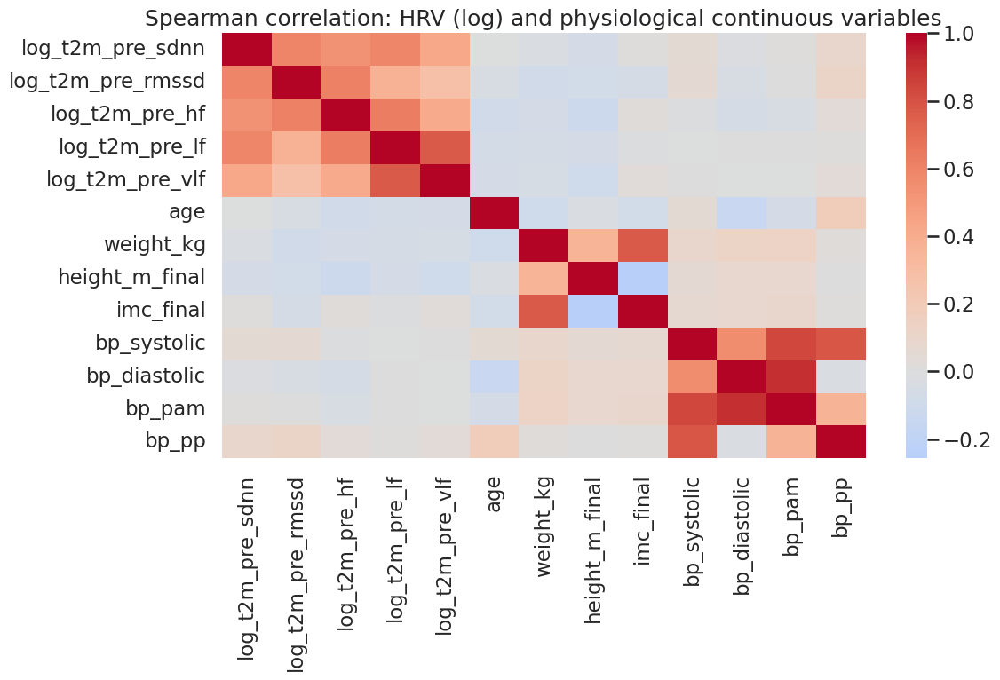

In [12]:
corr_matrix = df[log_hrv_cols + existing_phys_cont].corr(method="spearman")

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Spearman correlation: HRV (log) and physiological continuous variables")
plt.tight_layout()
plt.savefig(FIG_DIR / "spearman_hrv_phys_continuous.png", dpi=300)
plt.show()

corr_matrix.to_csv(TABLE_DIR / "spearman_hrv_phys_continuous.csv")

In [13]:
sub_corr = corr_matrix.loc[log_hrv_cols, existing_phys_cont]
sub_corr

,age,weight_kg,height_m_final,imc_final,bp_systolic,bp_diastolic,bp_pam,bp_pp
log_t2m_pre_sdnn,-0.005884,-0.026647,-0.070290,0.014884,0.051599,-0.018478,0.008619,0.095567
log_t2m_pre_rmssd,-0.037032,-0.085052,-0.079697,-0.052054,0.058062,-0.041142,0.003388,0.113507
log_t2m_pre_hf,-0.087939,-0.063859,-0.116553,0.018454,-0.011807,-0.058507,-0.039522,0.038405
log_t2m_pre_lf,-0.071226,-0.058097,-0.068945,-0.008139,0.000492,0.007726,0.005206,0.013684
log_t2m_pre_vlf,-0.061764,-0.048804,-0.093895,0.028190,0.007688,-0.000722,0.001024,0.041946


In [14]:
sub_corr.to_csv(TABLE_DIR / "spearman_hrv_vs_phys_only.csv")

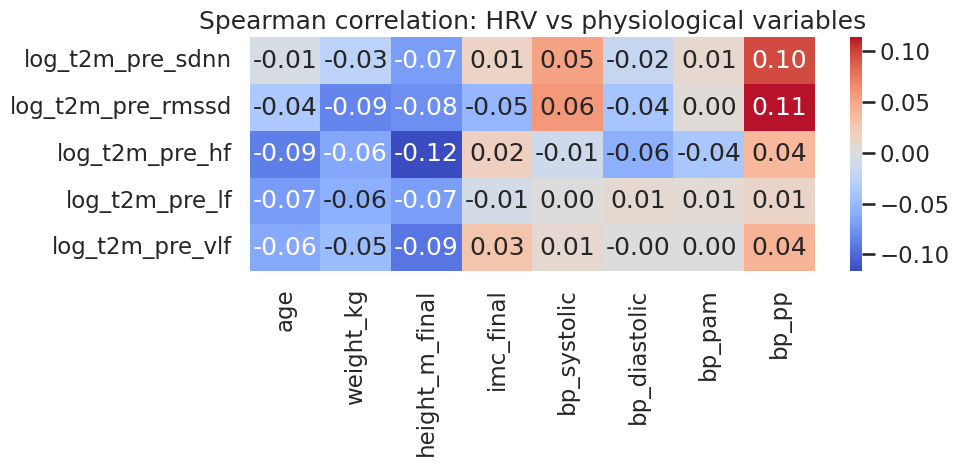

In [15]:
plt.figure(figsize=(10, 5))
sns.heatmap(sub_corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Spearman correlation: HRV vs physiological variables")
plt.tight_layout()
plt.savefig(FIG_DIR / "spearman_hrv_vs_physiology_heatmap.png", dpi=300)
plt.show()

In [16]:
def spearman_corr_with_pvalues(df_in, rows, cols):
    out = []

    for r in rows:
        for c in cols:
            tmp = df_in[[r, c]].dropna()
            if len(tmp) < 3:
                rho, p = np.nan, np.nan
            else:
                rho, p = stats.spearmanr(tmp[r], tmp[c])

            out.append({
                "row_var": r,
                "col_var": c,
                "spearman_rho": rho,
                "p_value": p,
                "n": len(tmp)
            })

    return pd.DataFrame(out)

In [17]:
corr_long = spearman_corr_with_pvalues(df, log_hrv_cols, existing_phys_cont)
corr_long = corr_long.sort_values(["p_value", "spearman_rho"], ascending=[True, False])

corr_long.head(20)

,row_var,col_var,spearman_rho,p_value,n
18,log_t2m_pre_hf,height_m_final,-0.116553,0.007230,530
15,log_t2m_pre_rmssd,bp_pp,0.113507,0.009445,522
7,log_t2m_pre_sdnn,bp_pp,0.095567,0.029488,519
34,log_t2m_pre_vlf,height_m_final,-0.093895,0.030672,530
16,log_t2m_pre_hf,age,-0.087939,0.043006,530
9,log_t2m_pre_rmssd,weight_kg,-0.085052,0.052129,522
10,log_t2m_pre_rmssd,height_m_final,-0.079697,0.068850,522
24,log_t2m_pre_lf,age,-0.071226,0.101431,530
2,log_t2m_pre_sdnn,height_m_final,-0.070290,0.109722,519
26,log_t2m_pre_lf,height_m_final,-0.068945,0.112884,530


In [18]:
corr_long.to_csv(TABLE_DIR / "spearman_hrv_vs_physiology_long.csv", index=False)

In [19]:
pca_hrv = PCA()
X_hrv_pca = pca_hrv.fit_transform(X_hrv_scaled)

explained_hrv = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(pca_hrv.explained_variance_ratio_))],
    "explained_variance_ratio": pca_hrv.explained_variance_ratio_,
    "cumulative_variance_ratio": np.cumsum(pca_hrv.explained_variance_ratio_)
})

explained_hrv

,PC,explained_variance_ratio,cumulative_variance_ratio
0,PC1,0.560552,0.560552
1,PC2,0.202992,0.763544
2,PC3,0.125840,0.889384
3,PC4,0.083412,0.972796
4,PC5,0.027204,1.000000


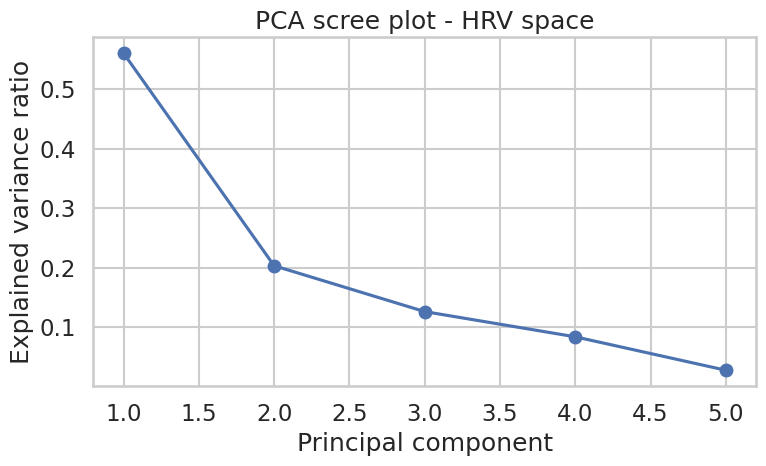

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(pca_hrv.explained_variance_ratio_) + 1),
    pca_hrv.explained_variance_ratio_,
    marker="o"
)
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA scree plot - HRV space")
plt.tight_layout()
plt.savefig(FIG_DIR / "pca_scree_hrv.png", dpi=300)
plt.show()

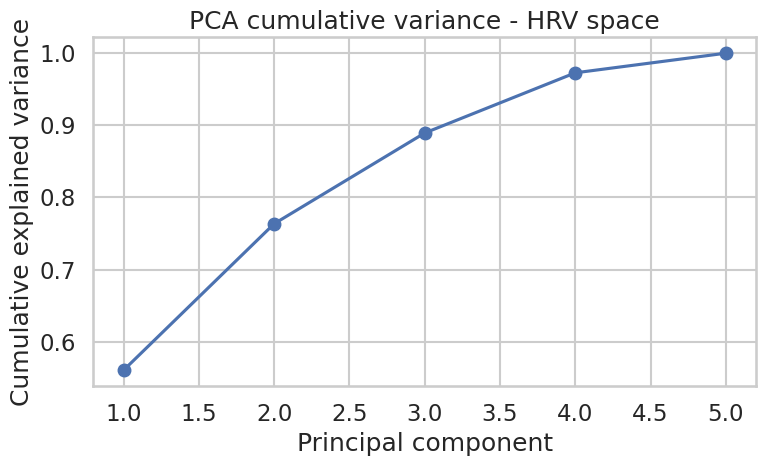

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(pca_hrv.explained_variance_ratio_) + 1),
    np.cumsum(pca_hrv.explained_variance_ratio_),
    marker="o"
)
plt.xlabel("Principal component")
plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative variance - HRV space")
plt.tight_layout()
plt.savefig(FIG_DIR / "pca_cumulative_hrv.png", dpi=300)
plt.show()

In [22]:
loadings_hrv = pd.DataFrame(
    pca_hrv.components_.T,
    index=X_hrv_scaled.columns,
    columns=[f"PC{i+1}" for i in range(pca_hrv.components_.shape[0])]
)

loadings_hrv

,PC1,PC2,PC3,PC4,PC5
log_t2m_pre_sdnn,0.382105,0.391086,0.829938,0.041857,-0.102464
log_t2m_pre_rmssd,0.340389,0.673481,-0.434217,-0.474760,0.128908
log_t2m_pre_hf,0.493869,0.095287,-0.349054,0.719463,-0.327945
log_t2m_pre_lf,0.528362,-0.367516,0.021956,0.044759,0.763728
log_t2m_pre_vlf,0.463744,-0.499326,-0.018404,-0.503210,-0.531089


In [23]:
loadings_hrv.to_csv(TABLE_DIR / "pca_loadings_hrv.csv")

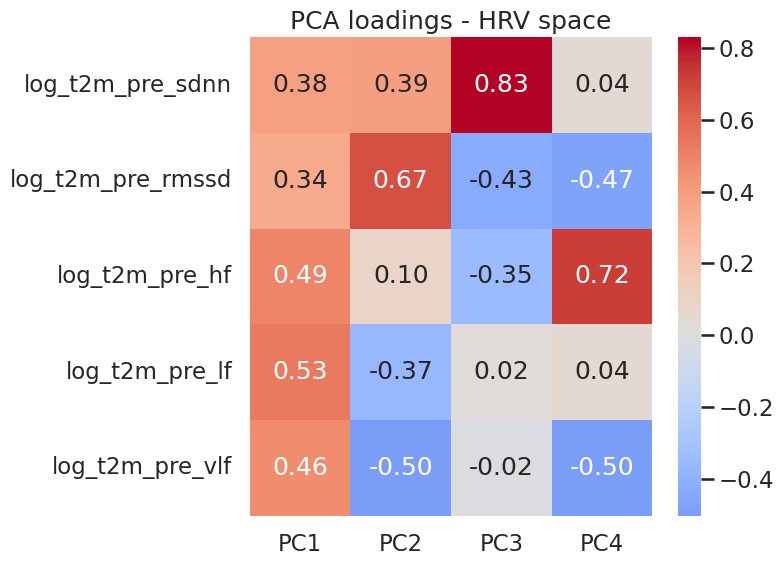

In [24]:
plt.figure(figsize=(8, 6))
sns.heatmap(loadings_hrv.iloc[:, :4], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("PCA loadings - HRV space")
plt.tight_layout()
plt.savefig(FIG_DIR / "pca_loadings_hrv_heatmap.png", dpi=300)
plt.show()

In [25]:
scores_hrv = pd.DataFrame(
    X_hrv_pca[:, :4],
    columns=["PC1", "PC2", "PC3", "PC4"],
    index=df.index
)

scores_hrv = pd.concat([scores_hrv, df[existing_phys_cat + existing_qc]], axis=1)
scores_hrv.head()

,PC1,PC2,PC3,PC4,sex,age_group,bmi_cat,bp_cat,height_inconsistent,imc_inconsistent,hr_rr_inconsistent,n_total_qc_flags
0,2.112973,0.110814,0.376053,-0.562139,1,70-79,normal,normal,False,False,False,0
1,0.628205,0.762571,0.556100,-0.254372,1,60-69,normal,normal,False,False,False,0
2,-0.789823,0.460062,0.772438,-0.018133,2,70-79,overweight,normal,False,False,False,0
3,0.087963,0.949840,0.237330,0.168771,1,70-79,obesity,normal,False,False,False,0
4,-0.409025,0.714516,0.573041,0.013820,1,70-79,overweight,normal,False,False,False,0


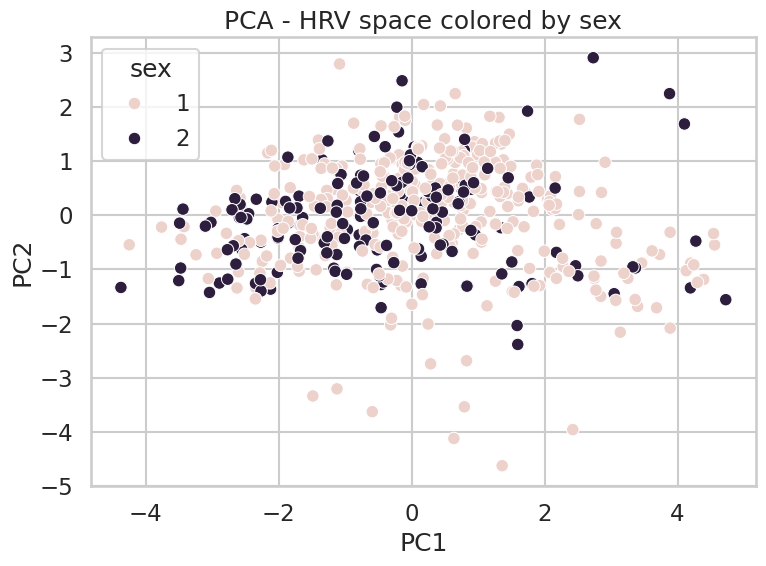

In [26]:
if "sex" in scores_hrv.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=scores_hrv, x="PC1", y="PC2", hue="sex")
    plt.title("PCA - HRV space colored by sex")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "pca_hrv_pc1_pc2_sex.png", dpi=300)
    plt.show()

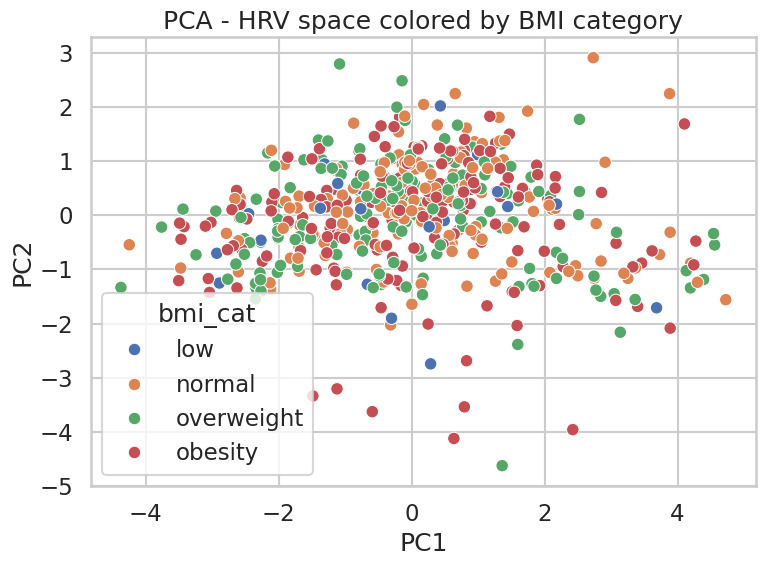

In [27]:
if "bmi_cat" in scores_hrv.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=scores_hrv, x="PC1", y="PC2", hue="bmi_cat")
    plt.title("PCA - HRV space colored by BMI category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "pca_hrv_pc1_pc2_bmi_cat.png", dpi=300)
    plt.show()

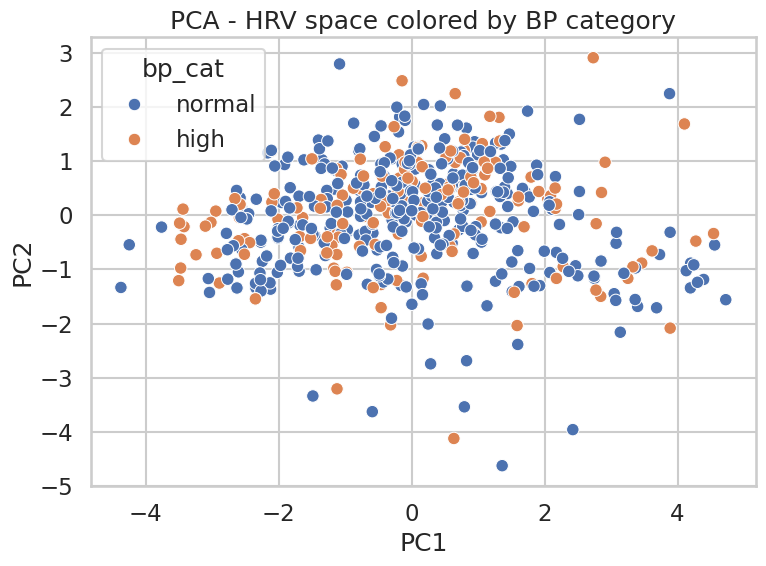

In [28]:
if "bp_cat" in scores_hrv.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=scores_hrv, x="PC1", y="PC2", hue="bp_cat")
    plt.title("PCA - HRV space colored by BP category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "pca_hrv_pc1_pc2_bp_cat.png", dpi=300)
    plt.show()

In [29]:
pca_int = PCA()
X_int_pca = pca_int.fit_transform(X_int_scaled)

explained_int = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(pca_int.explained_variance_ratio_))],
    "explained_variance_ratio": pca_int.explained_variance_ratio_,
    "cumulative_variance_ratio": np.cumsum(pca_int.explained_variance_ratio_)
})

explained_int

,PC,explained_variance_ratio,cumulative_variance_ratio
0,PC1,0.227780,0.227780
1,PC2,0.217720,0.445500
2,PC3,0.138613,0.584114
3,PC4,0.102033,0.686147
4,PC5,0.089026,0.775173
5,PC6,0.075865,0.851037
6,PC7,0.061049,0.912086
7,PC8,0.045600,0.957686
8,PC9,0.031758,0.989444
9,PC10,0.010191,0.999635


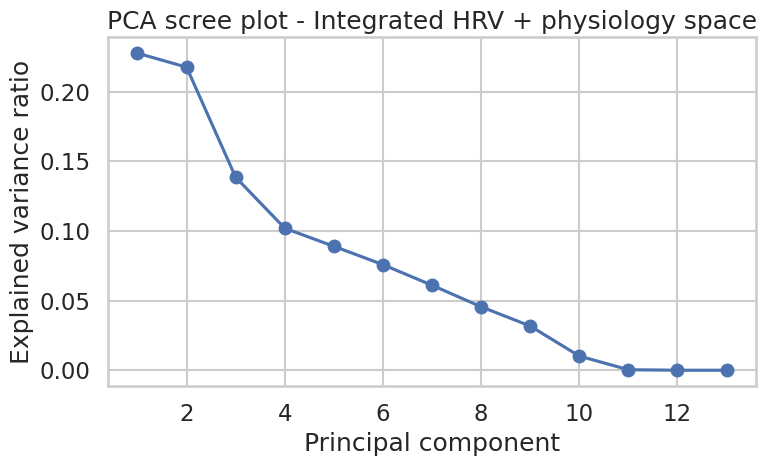

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(pca_int.explained_variance_ratio_) + 1),
    pca_int.explained_variance_ratio_,
    marker="o"
)
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA scree plot - Integrated HRV + physiology space")
plt.tight_layout()
plt.savefig(FIG_DIR / "pca_scree_integrated.png", dpi=300)
plt.show()

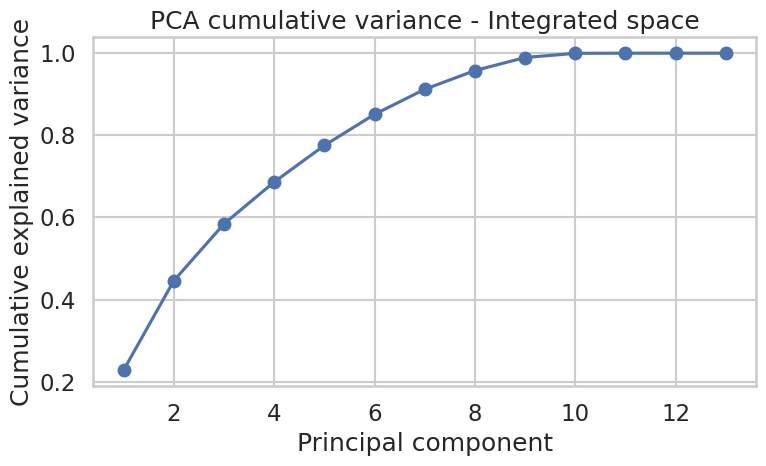

In [31]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(pca_int.explained_variance_ratio_) + 1),
    np.cumsum(pca_int.explained_variance_ratio_),
    marker="o"
)
plt.xlabel("Principal component")
plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative variance - Integrated space")
plt.tight_layout()
plt.savefig(FIG_DIR / "pca_cumulative_integrated.png", dpi=300)
plt.show()

In [32]:
loadings_int = pd.DataFrame(
    pca_int.components_.T,
    index=X_int_scaled.columns,
    columns=[f"PC{i+1}" for i in range(pca_int.components_.shape[0])]
)

loadings_int

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
log_t2m_pre_sdnn,-0.114832,0.356940,0.047929,0.122801,0.189759,0.298081,0.368839,0.753524,0.045429,-0.106123,-0.001810,5.650610e-17,-9.265968e-17
log_t2m_pre_rmssd,-0.132081,0.314791,-0.118323,0.089812,0.192376,0.615975,0.044390,-0.442817,-0.479246,0.131191,0.003930,-3.414443e-16,6.328277e-17
log_t2m_pre_hf,-0.195326,0.449862,0.029483,-0.003605,0.026154,0.107551,-0.073354,-0.347527,0.712708,-0.335008,-0.000516,5.881654e-16,-3.656683e-16
log_t2m_pre_lf,-0.178525,0.486394,0.072743,-0.135744,-0.007532,-0.353566,-0.025059,0.017575,0.057507,0.760598,0.003562,-6.184168e-16,7.158206e-16
log_t2m_pre_vlf,-0.158481,0.427786,0.078404,-0.117546,-0.065852,-0.478527,-0.087210,-0.007934,-0.503212,-0.526975,-0.000869,2.217432e-16,-3.974683e-16
age,-0.012182,-0.036709,-0.238533,0.506553,0.051362,-0.346937,0.698667,-0.270822,0.022874,0.000621,-0.001417,-1.216416e-16,-1.078792e-16
weight_kg,0.209243,0.002500,0.640146,0.176308,0.264813,-0.033732,0.021710,-0.099254,-0.017346,0.005936,0.658345,-8.101127e-15,4.506029e-15
height_m_final,0.115561,-0.082293,0.052213,-0.164776,0.864987,-0.174675,-0.038945,-0.056253,0.030499,-0.027671,-0.406085,5.147113e-15,-2.752508e-15
imc_final,0.139269,0.056432,0.633478,0.283257,-0.279047,0.079676,0.048548,-0.071822,-0.040333,0.030120,-0.633739,7.861950e-15,-4.290698e-15
bp_systolic,0.499874,0.226825,-0.188583,0.153978,-0.013472,-0.017433,-0.148513,0.038409,0.010382,0.003000,-0.002143,-4.405594e-01,-6.489783e-01


In [33]:
loadings_int.to_csv(TABLE_DIR / "pca_loadings_integrated.csv")

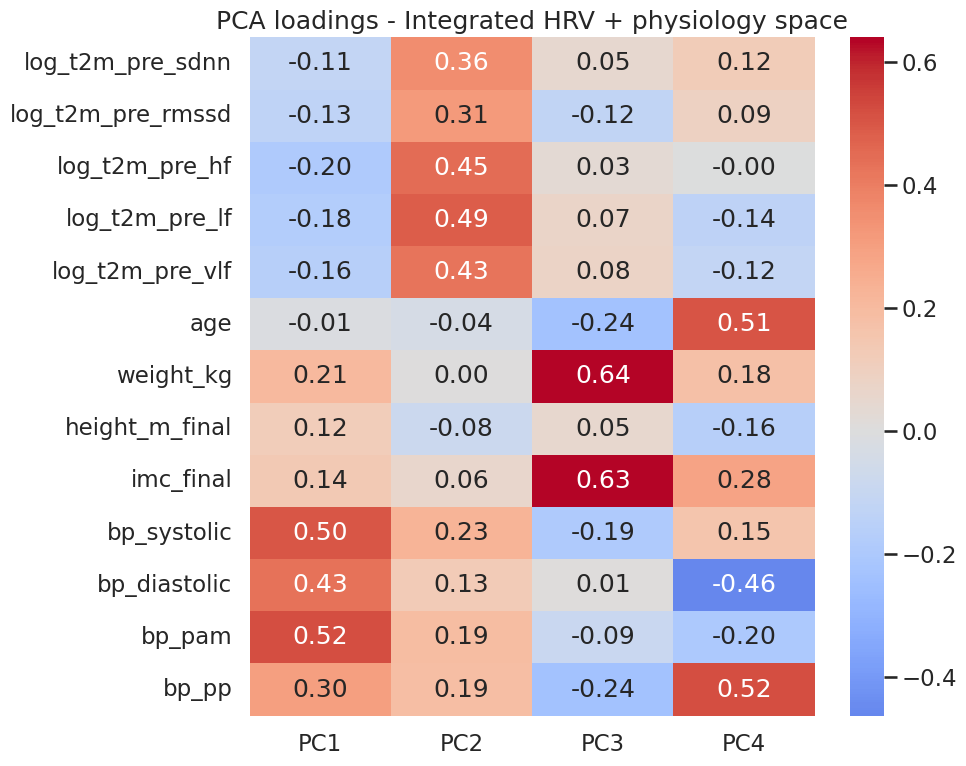

In [34]:
plt.figure(figsize=(10, 8))
sns.heatmap(loadings_int.iloc[:, :4], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("PCA loadings - Integrated HRV + physiology space")
plt.tight_layout()
plt.savefig(FIG_DIR / "pca_loadings_integrated_heatmap.png", dpi=300)
plt.show()

In [35]:
scores_int = pd.DataFrame(
    X_int_pca[:, :4],
    columns=["PC1", "PC2", "PC3", "PC4"],
    index=df.index
)

scores_int = pd.concat([scores_int, df[existing_phys_cat + existing_qc]], axis=1)
scores_int.head()

,PC1,PC2,PC3,PC4,sex,age_group,bmi_cat,bp_cat,height_inconsistent,imc_inconsistent,hr_rr_inconsistent,n_total_qc_flags
0,-2.708395,1.061542,-0.033529,-0.214865,1,70-79,normal,normal,False,False,False,0
1,-1.651197,0.278986,-1.583934,-0.578840,1,60-69,normal,normal,False,False,False,0
2,0.533974,-0.996333,0.003358,-0.577283,2,70-79,overweight,normal,False,False,False,0
3,-0.351982,-0.154387,0.498505,1.240097,1,70-79,obesity,normal,False,False,False,0
4,0.092497,-0.320298,-0.469756,0.143208,1,70-79,overweight,normal,False,False,False,0


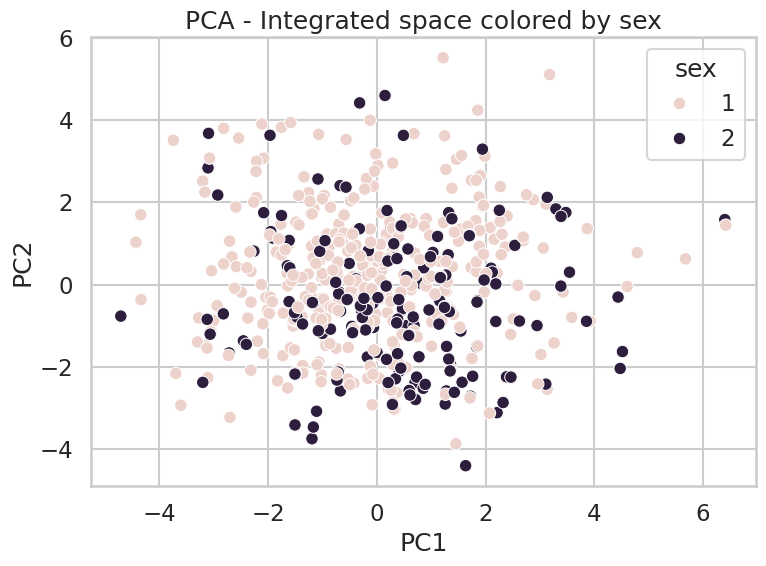

In [36]:
if "sex" in scores_int.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=scores_int, x="PC1", y="PC2", hue="sex")
    plt.title("PCA - Integrated space colored by sex")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "pca_integrated_pc1_pc2_sex.png", dpi=300)
    plt.show()

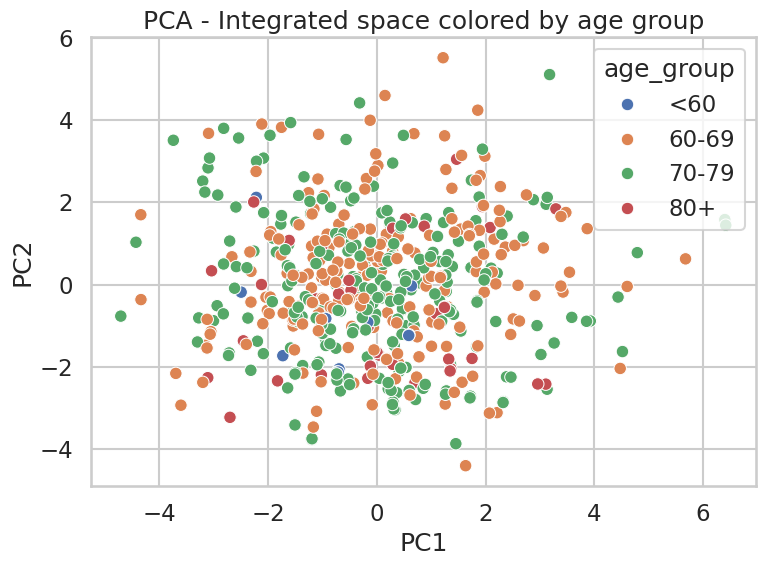

In [37]:
if "age_group" in scores_int.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=scores_int, x="PC1", y="PC2", hue="age_group")
    plt.title("PCA - Integrated space colored by age group")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "pca_integrated_pc1_pc2_age_group.png", dpi=300)
    plt.show()

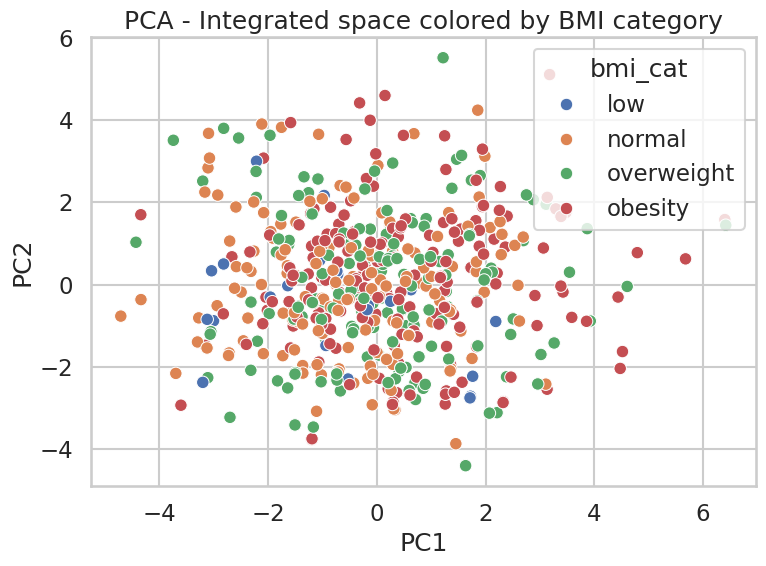

In [38]:
if "bmi_cat" in scores_int.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=scores_int, x="PC1", y="PC2", hue="bmi_cat")
    plt.title("PCA - Integrated space colored by BMI category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "pca_integrated_pc1_pc2_bmi_cat.png", dpi=300)
    plt.show()

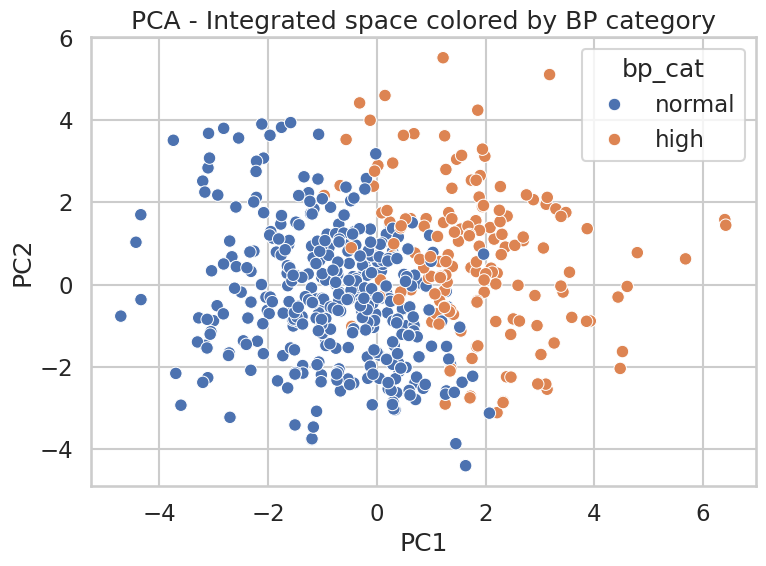

In [39]:
if "bp_cat" in scores_int.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=scores_int, x="PC1", y="PC2", hue="bp_cat")
    plt.title("PCA - Integrated space colored by BP category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "pca_integrated_pc1_pc2_bp_cat.png", dpi=300)
    plt.show()

In [40]:
pc_phys_assoc = spearman_corr_with_pvalues(
    pd.concat([scores_int[["PC1", "PC2", "PC3", "PC4"]], df[existing_phys_cont]], axis=1),
    ["PC1", "PC2", "PC3", "PC4"],
    existing_phys_cont
)

pc_phys_assoc.sort_values("p_value").head(20)

,row_var,col_var,spearman_rho,p_value,n
6,PC1,bp_pam,0.878980,6.107094e-172,530
4,PC1,bp_systolic,0.837213,1.670378e-140,530
17,PC3,weight_kg,0.830718,2.023159e-136,530
19,PC3,imc_final,0.805123,7.060309e-122,530
5,PC1,bp_diastolic,0.723029,7.318001e-87,530
31,PC4,bp_pp,0.583727,1.009387e-49,530
24,PC4,age,0.558549,8.292663e-45,530
29,PC4,bp_diastolic,-0.515010,3.086898e-37,530
7,PC1,bp_pp,0.484142,1.699216e-32,530
12,PC2,bp_systolic,0.368508,1.719090e-18,530


In [41]:
pc_phys_assoc.to_csv(TABLE_DIR / "pc_vs_physiology_spearman.csv", index=False)

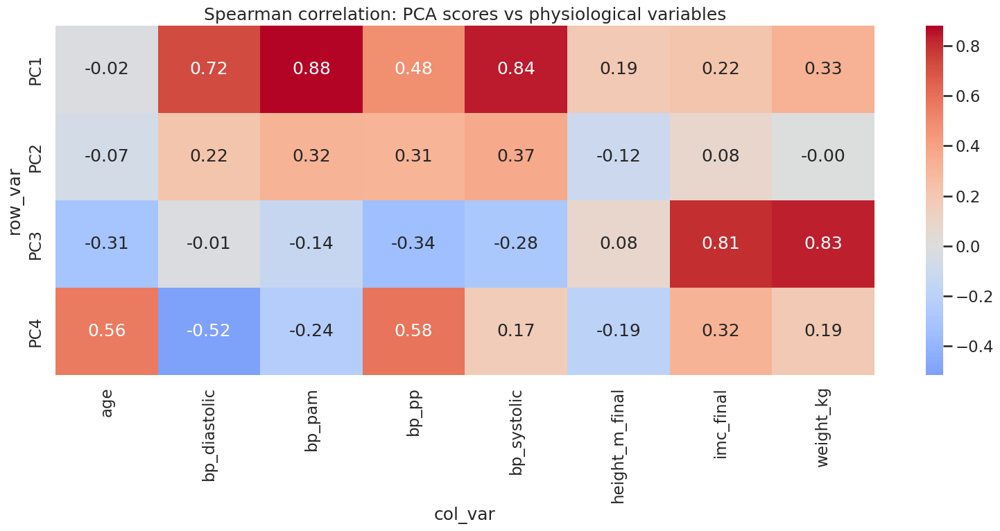

In [43]:
pc_phys_pivot = pc_phys_assoc.pivot(index="row_var", columns="col_var", values="spearman_rho")

plt.figure(figsize=(16, 8))
sns.heatmap(pc_phys_pivot, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation: PCA scores vs physiological variables")
plt.tight_layout()
plt.savefig(FIG_DIR / "pc_vs_physiology_heatmap.png", dpi=300)
plt.show()

In [44]:
if HAS_UMAP:
    umap_hrv = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2,
        random_state=42
    )
    X_umap_hrv = umap_hrv.fit_transform(X_hrv_scaled)

    umap_hrv_df = pd.DataFrame(X_umap_hrv, columns=["UMAP1", "UMAP2"], index=df.index)
    umap_hrv_df = pd.concat([umap_hrv_df, df[existing_phys_cat + existing_qc]], axis=1)

    umap_hrv_df.head()

/raid/data/dmedina/miniconda3/envs/tools_base/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


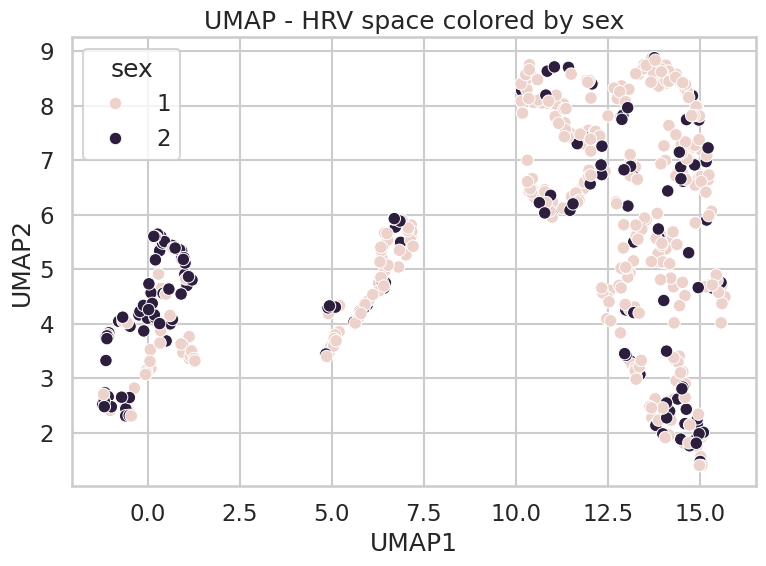

In [45]:
if HAS_UMAP and "sex" in umap_hrv_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=umap_hrv_df, x="UMAP1", y="UMAP2", hue="sex")
    plt.title("UMAP - HRV space colored by sex")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "umap_hrv_sex.png", dpi=300)
    plt.show()

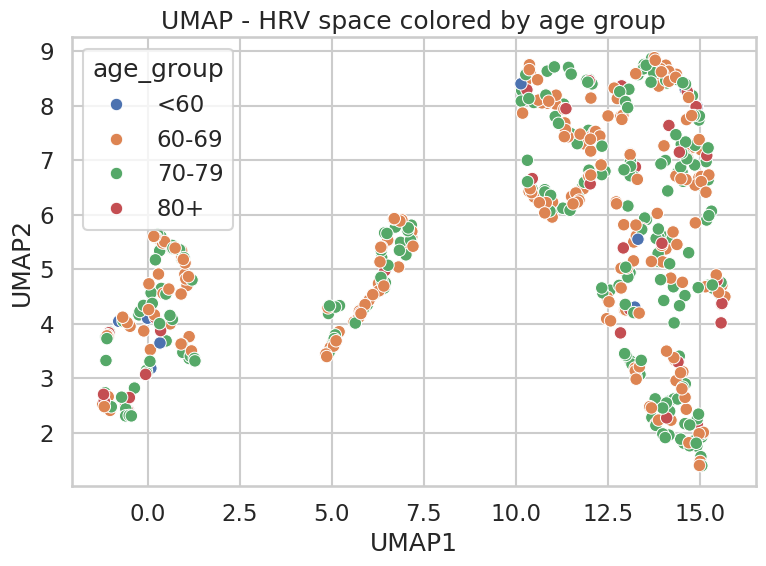

In [46]:
if HAS_UMAP and "age_group" in umap_hrv_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=umap_hrv_df, x="UMAP1", y="UMAP2", hue="age_group")
    plt.title("UMAP - HRV space colored by age group")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "umap_hrv_age_group.png", dpi=300)
    plt.show()

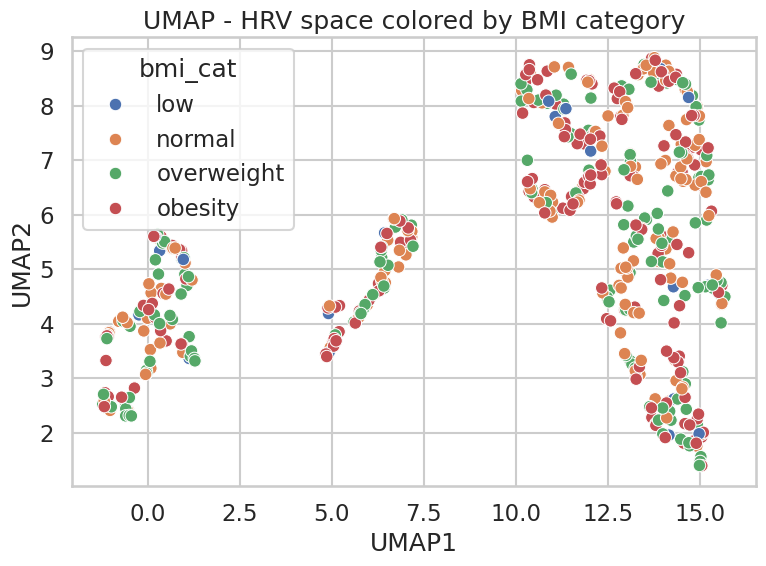

In [48]:
if HAS_UMAP and "bmi_cat" in umap_hrv_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=umap_hrv_df, x="UMAP1", y="UMAP2", hue="bmi_cat")
    plt.title("UMAP - HRV space colored by BMI category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "umap_hrv_bmi_cat.png", dpi=300)
    plt.show()

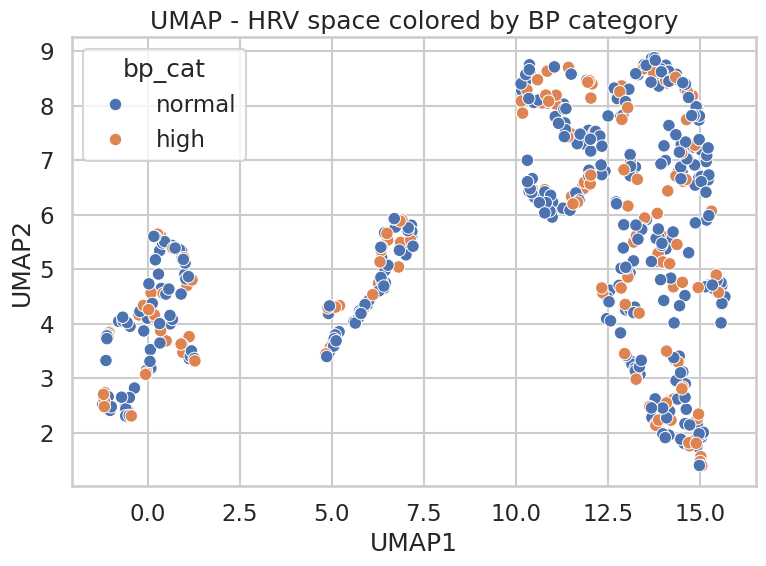

In [49]:
if HAS_UMAP and "bp_cat" in umap_hrv_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=umap_hrv_df, x="UMAP1", y="UMAP2", hue="bp_cat")
    plt.title("UMAP - HRV space colored by BP category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "umap_hrv_bp_cat.png", dpi=300)
    plt.show()

In [50]:
if HAS_UMAP:
    umap_int = umap.UMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2,
        random_state=42
    )
    X_umap_int = umap_int.fit_transform(X_int_scaled)

    umap_int_df = pd.DataFrame(X_umap_int, columns=["UMAP1", "UMAP2"], index=df.index)
    umap_int_df = pd.concat([umap_int_df, df[existing_phys_cat + existing_qc]], axis=1)

    umap_int_df.head()

/raid/data/dmedina/miniconda3/envs/tools_base/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


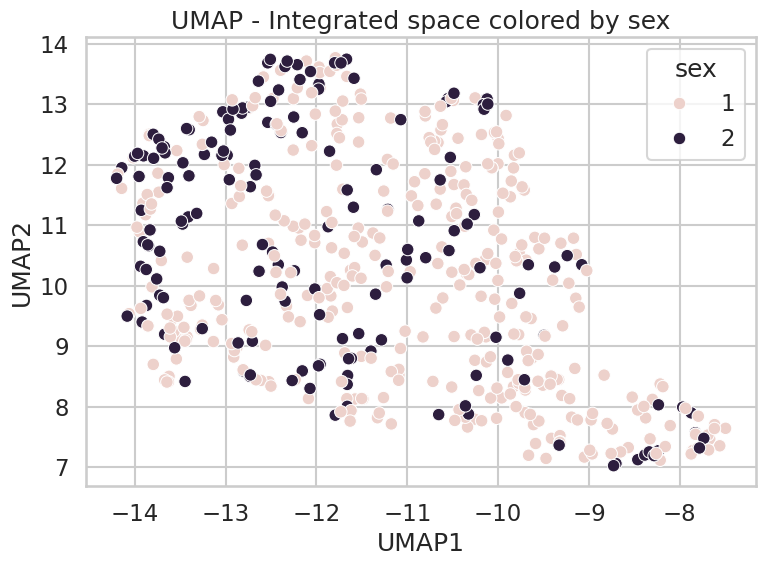

In [51]:
if HAS_UMAP and "sex" in umap_int_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=umap_int_df, x="UMAP1", y="UMAP2", hue="sex")
    plt.title("UMAP - Integrated space colored by sex")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "umap_integrated_sex.png", dpi=300)
    plt.show()

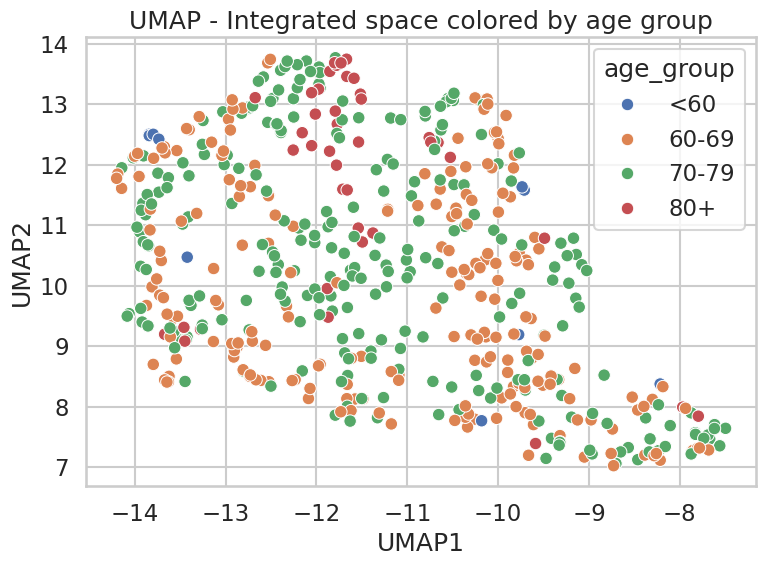

In [52]:
if HAS_UMAP and "age_group" in umap_int_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=umap_int_df, x="UMAP1", y="UMAP2", hue="age_group")
    plt.title("UMAP - Integrated space colored by age group")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "umap_integrated_age_group.png", dpi=300)
    plt.show()

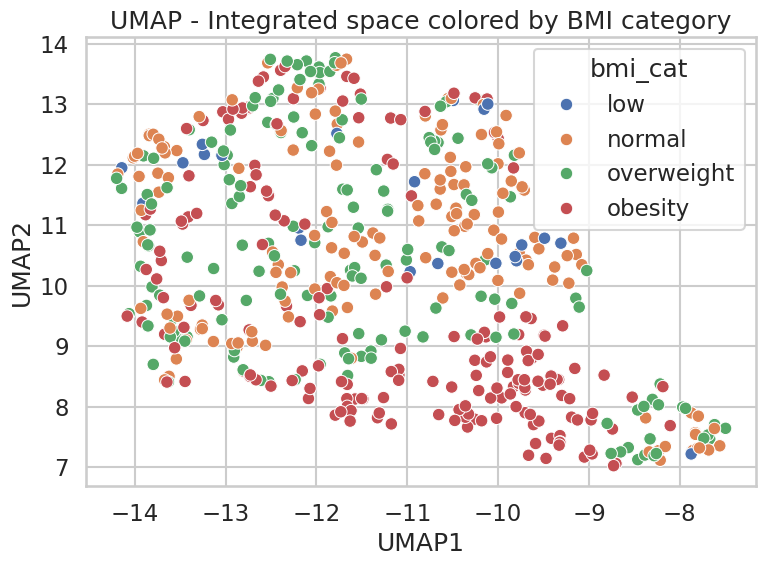

In [53]:
if HAS_UMAP and "bmi_cat" in umap_int_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=umap_int_df, x="UMAP1", y="UMAP2", hue="bmi_cat")
    plt.title("UMAP - Integrated space colored by BMI category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "umap_integrated_bmi_cat.png", dpi=300)
    plt.show()

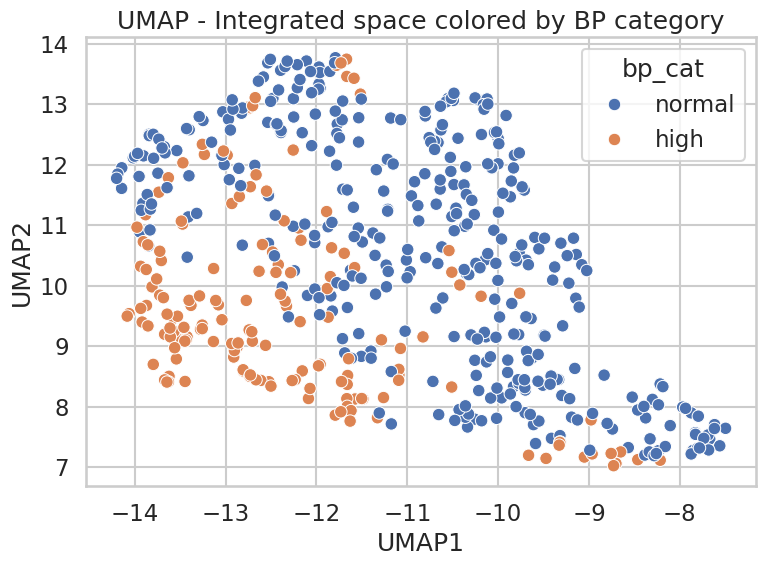

In [54]:
if HAS_UMAP and "bp_cat" in umap_int_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=umap_int_df, x="UMAP1", y="UMAP2", hue="bp_cat")
    plt.title("UMAP - Integrated space colored by BP category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "umap_integrated_bp_cat.png", dpi=300)
    plt.show()

In [55]:
tsne_hrv = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)
X_tsne_hrv = tsne_hrv.fit_transform(X_hrv_scaled)

tsne_hrv_df = pd.DataFrame(X_tsne_hrv, columns=["TSNE1", "TSNE2"], index=df.index)
tsne_hrv_df = pd.concat([tsne_hrv_df, df[existing_phys_cat + existing_qc]], axis=1)

tsne_hrv_df.head()

,TSNE1,TSNE2,sex,age_group,bmi_cat,bp_cat,height_inconsistent,imc_inconsistent,hr_rr_inconsistent,n_total_qc_flags
0,16.165991,-6.318325,1,70-79,normal,normal,False,False,False,0
1,8.268826,6.095325,1,60-69,normal,normal,False,False,False,0
2,-1.920187,14.775598,2,70-79,overweight,normal,False,False,False,0
3,10.580968,11.520860,1,70-79,obesity,normal,False,False,False,0
4,3.464238,14.543179,1,70-79,overweight,normal,False,False,False,0


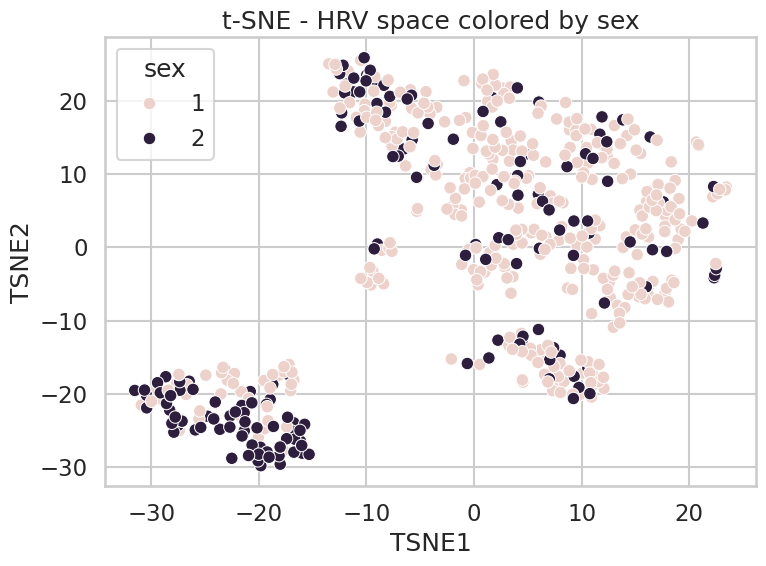

In [56]:
if "sex" in tsne_hrv_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=tsne_hrv_df, x="TSNE1", y="TSNE2", hue="sex")
    plt.title("t-SNE - HRV space colored by sex")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "tsne_hrv_sex.png", dpi=300)
    plt.show()

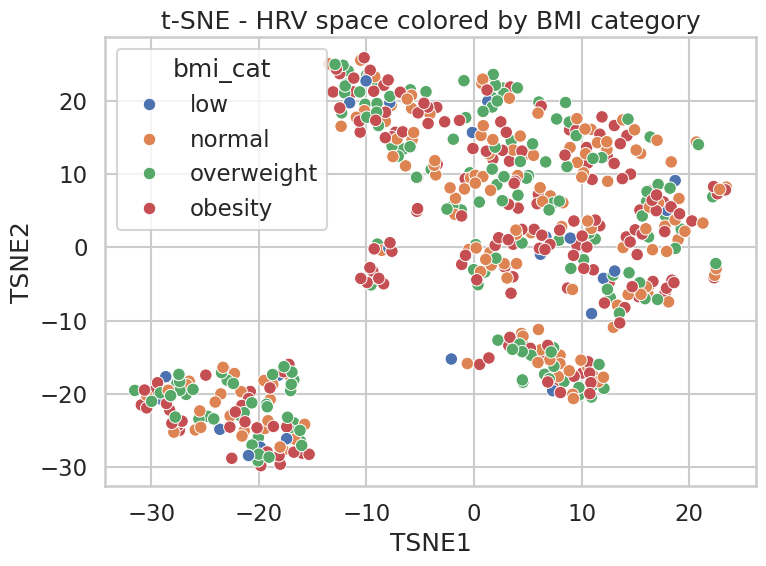

In [57]:
if "bmi_cat" in tsne_hrv_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=tsne_hrv_df, x="TSNE1", y="TSNE2", hue="bmi_cat")
    plt.title("t-SNE - HRV space colored by BMI category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "tsne_hrv_bmi_cat.png", dpi=300)
    plt.show()

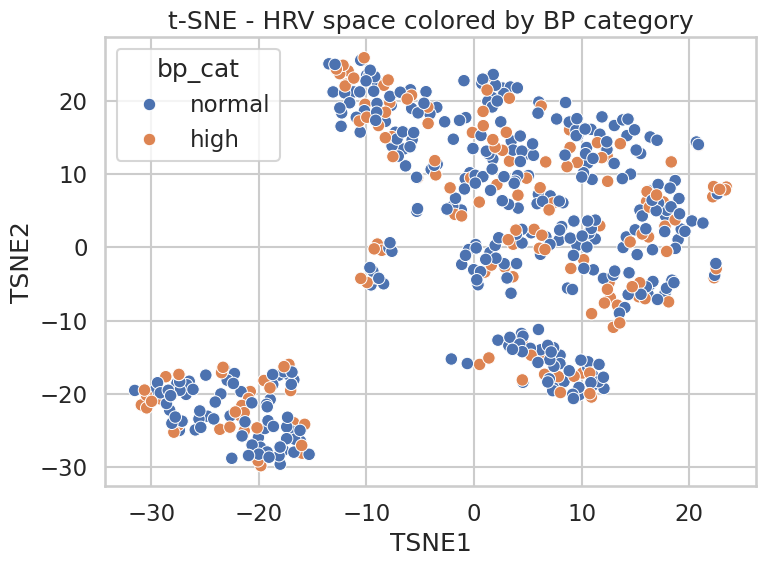

In [58]:
if "bp_cat" in tsne_hrv_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=tsne_hrv_df, x="TSNE1", y="TSNE2", hue="bp_cat")
    plt.title("t-SNE - HRV space colored by BP category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "tsne_hrv_bp_cat.png", dpi=300)
    plt.show()

In [59]:
tsne_int = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)
X_tsne_int = tsne_int.fit_transform(X_int_scaled)

tsne_int_df = pd.DataFrame(X_tsne_int, columns=["TSNE1", "TSNE2"], index=df.index)
tsne_int_df = pd.concat([tsne_int_df, df[existing_phys_cat + existing_qc]], axis=1)

tsne_int_df.head()

,TSNE1,TSNE2,sex,age_group,bmi_cat,bp_cat,height_inconsistent,imc_inconsistent,hr_rr_inconsistent,n_total_qc_flags
0,-9.873713,6.638729,1,70-79,normal,normal,False,False,False,0
1,-7.613726,2.404806,1,60-69,normal,normal,False,False,False,0
2,-4.094804,-5.353203,2,70-79,overweight,normal,False,False,False,0
3,-5.621374,-12.685750,1,70-79,obesity,normal,False,False,False,0
4,-0.010370,1.042724,1,70-79,overweight,normal,False,False,False,0


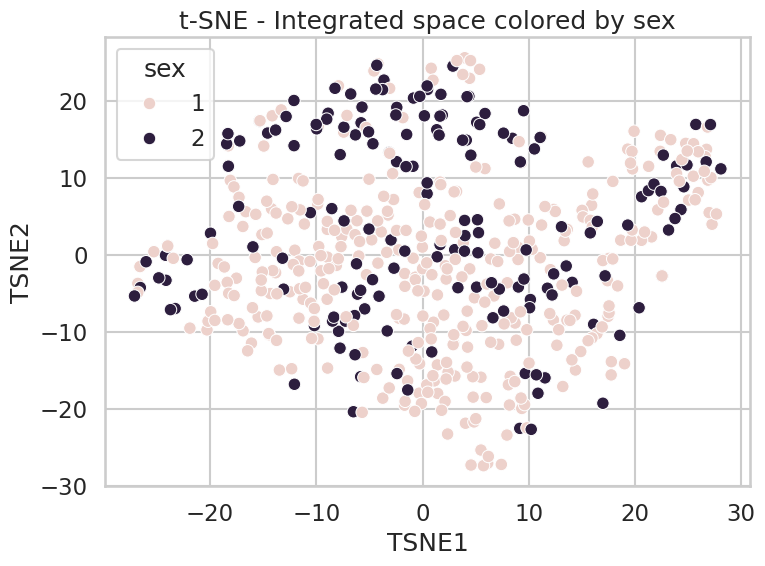

In [60]:
if "sex" in tsne_int_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=tsne_int_df, x="TSNE1", y="TSNE2", hue="sex")
    plt.title("t-SNE - Integrated space colored by sex")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "tsne_integrated_sex.png", dpi=300)
    plt.show()

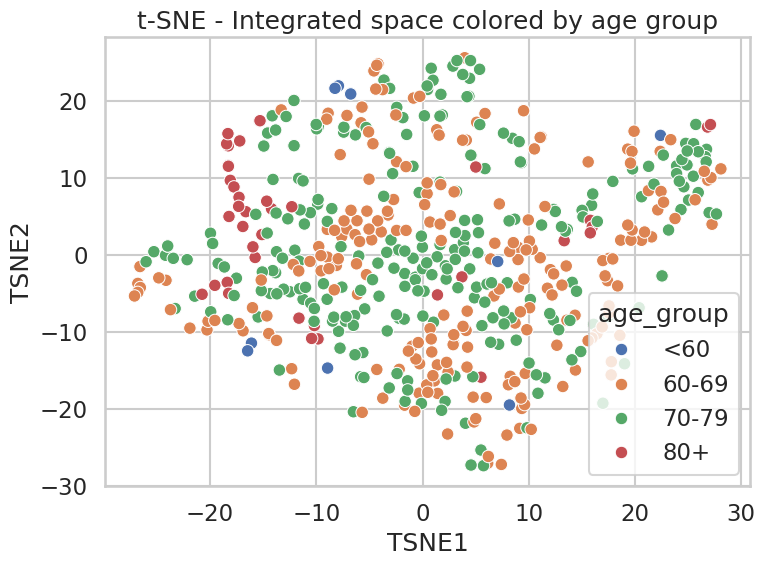

In [61]:
if "age_group" in tsne_int_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=tsne_int_df, x="TSNE1", y="TSNE2", hue="age_group")
    plt.title("t-SNE - Integrated space colored by age group")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "tsne_integrated_age_group.png", dpi=300)
    plt.show()

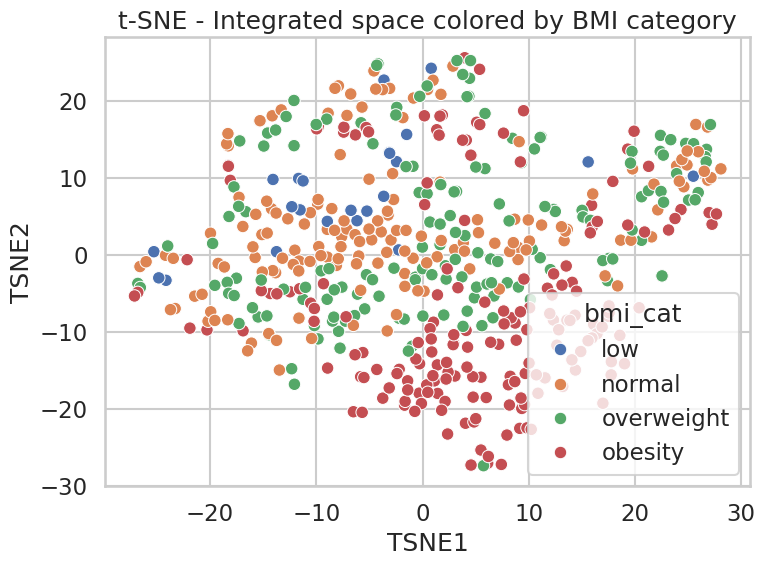

In [62]:
if "bmi_cat" in tsne_int_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=tsne_int_df, x="TSNE1", y="TSNE2", hue="bmi_cat")
    plt.title("t-SNE - Integrated space colored by BMI category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "tsne_integrated_bmi_cat.png", dpi=300)
    plt.show()

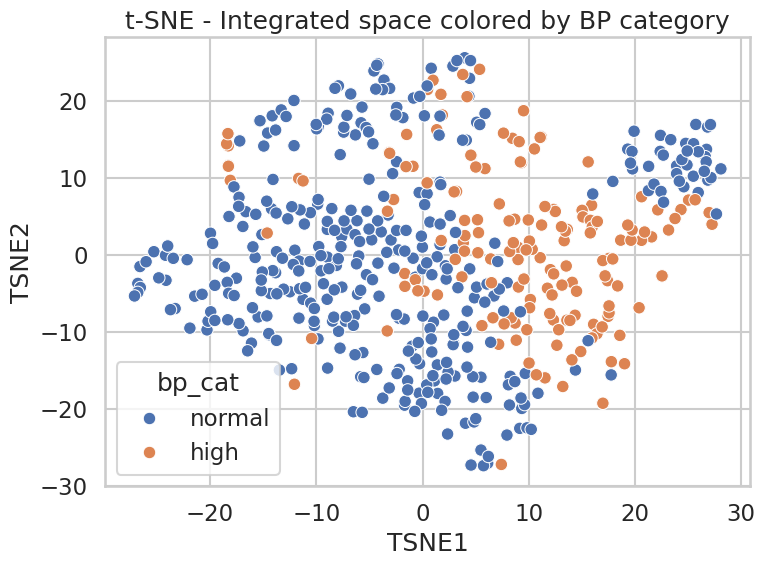

In [63]:
if "bp_cat" in tsne_int_df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=tsne_int_df, x="TSNE1", y="TSNE2", hue="bp_cat")
    plt.title("t-SNE - Integrated space colored by BP category")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "tsne_integrated_bp_cat.png", dpi=300)
    plt.show()

In [64]:
scores_hrv.to_csv(TABLE_DIR / "pca_scores_hrv.csv", index=False)
scores_int.to_csv(TABLE_DIR / "pca_scores_integrated.csv", index=False)

if HAS_UMAP:
    umap_hrv_df.to_csv(TABLE_DIR / "umap_scores_hrv.csv", index=False)
    umap_int_df.to_csv(TABLE_DIR / "umap_scores_integrated.csv", index=False)

tsne_hrv_df.to_csv(TABLE_DIR / "tsne_scores_hrv.csv", index=False)
tsne_int_df.to_csv(TABLE_DIR / "tsne_scores_integrated.csv", index=False)

In [65]:
summary_dict = {
    "n_subjects": int(df.shape[0]),
    "n_hrv_variables": int(len(existing_hrv)),
    "n_log_hrv_variables": int(len(log_hrv_cols)),
    "n_physiological_continuous_variables": int(len(existing_phys_cont)),
    "hrv_pc1_variance": float(explained_hrv.iloc[0]["explained_variance_ratio"]),
    "hrv_pc2_variance": float(explained_hrv.iloc[1]["explained_variance_ratio"]) if len(explained_hrv) > 1 else np.nan,
    "integrated_pc1_variance": float(explained_int.iloc[0]["explained_variance_ratio"]),
    "integrated_pc2_variance": float(explained_int.iloc[1]["explained_variance_ratio"]) if len(explained_int) > 1 else np.nan,
    "umap_available": HAS_UMAP,
}

pd.Series(summary_dict, name="value")

n_subjects                                   530
n_hrv_variables                                7
n_log_hrv_variables                            5
n_physiological_continuous_variables           8
hrv_pc1_variance                        0.560552
hrv_pc2_variance                        0.202992
integrated_pc1_variance                  0.22778
integrated_pc2_variance                  0.21772
umap_available                              True
Name: value, dtype: object

In [66]:
pd.Series(summary_dict, name="value").to_csv(TABLE_DIR / "multivariate_summary.csv")

In [67]:
combined_defs_double = [
    ("sex", "age_group"),
    ("sex", "bmi_cat"),
    ("sex", "bp_cat"),
    ("age_group", "bmi_cat"),
    ("age_group", "bp_cat"),
    ("bmi_cat", "bp_cat"),
]

combined_defs_triple = [
    ("sex", "age_group", "bmi_cat"),
    ("sex", "age_group", "bp_cat"),
    ("sex", "bmi_cat", "bp_cat"),
    ("age_group", "bmi_cat", "bp_cat"),
]

def create_combined_column(df_in, cols):
    name = "__".join(cols)
    if name not in df_in.columns:
        df_in[name] = df_in[list(cols)].astype(str).agg(" | ".join, axis=1)
        mask_missing = df_in[list(cols)].isna().any(axis=1)
        df_in.loc[mask_missing, name] = np.nan
    return df_in, name

combined_double_cols = []
for comb in combined_defs_double:
    if all(c in df.columns for c in comb):
        df, name = create_combined_column(df, comb)
        combined_double_cols.append(name)

combined_triple_cols = []
for comb in combined_defs_triple:
    if all(c in df.columns for c in comb):
        df, name = create_combined_column(df, comb)
        combined_triple_cols.append(name)

combined_double_cols, combined_triple_cols

(['sex__age_group',
  'sex__bmi_cat',
  'sex__bp_cat',
  'age_group__bmi_cat',
  'age_group__bp_cat',
  'bmi_cat__bp_cat'],
 ['sex__age_group__bmi_cat',
  'sex__age_group__bp_cat',
  'sex__bmi_cat__bp_cat',
  'age_group__bmi_cat__bp_cat'])

In [68]:
def pretty_combined_label(x):
    mapping = {
        "sex__age_group": "Sex × Age group",
        "sex__bmi_cat": "Sex × BMI category",
        "sex__bp_cat": "Sex × BP category",
        "age_group__bmi_cat": "Age group × BMI category",
        "age_group__bp_cat": "Age group × BP category",
        "bmi_cat__bp_cat": "BMI category × BP category",
        "sex__age_group__bmi_cat": "Sex × Age group × BMI category",
        "sex__age_group__bp_cat": "Sex × Age group × BP category",
        "sex__bmi_cat__bp_cat": "Sex × BMI category × BP category",
        "age_group__bmi_cat__bp_cat": "Age group × BMI category × BP category",
    }
    return mapping.get(x, x)

In [69]:
pca_hrv_comb_cols = combined_double_cols + combined_triple_cols
scores_hrv = pd.concat([scores_hrv, df[pca_hrv_comb_cols]], axis=1)

scores_hrv.head()

,PC1,PC2,PC3,PC4,sex,age_group,bmi_cat,bp_cat,height_inconsistent,imc_inconsistent,...,sex__age_group,sex__bmi_cat,sex__bp_cat,age_group__bmi_cat,age_group__bp_cat,bmi_cat__bp_cat,sex__age_group__bmi_cat,sex__age_group__bp_cat,sex__bmi_cat__bp_cat,age_group__bmi_cat__bp_cat
0,2.112973,0.110814,0.376053,-0.562139,1,70-79,normal,normal,False,False,...,1 | 70-79,1 | normal,1 | normal,70-79 | normal,70-79 | normal,normal | normal,1 | 70-79 | normal,1 | 70-79 | normal,1 | normal | normal,70-79 | normal | normal
1,0.628205,0.762571,0.556100,-0.254372,1,60-69,normal,normal,False,False,...,1 | 60-69,1 | normal,1 | normal,60-69 | normal,60-69 | normal,normal | normal,1 | 60-69 | normal,1 | 60-69 | normal,1 | normal | normal,60-69 | normal | normal
2,-0.789823,0.460062,0.772438,-0.018133,2,70-79,overweight,normal,False,False,...,2 | 70-79,2 | overweight,2 | normal,70-79 | overweight,70-79 | normal,overweight | normal,2 | 70-79 | overweight,2 | 70-79 | normal,2 | overweight | normal,70-79 | overweight | normal
3,0.087963,0.949840,0.237330,0.168771,1,70-79,obesity,normal,False,False,...,1 | 70-79,1 | obesity,1 | normal,70-79 | obesity,70-79 | normal,obesity | normal,1 | 70-79 | obesity,1 | 70-79 | normal,1 | obesity | normal,70-79 | obesity | normal
4,-0.409025,0.714516,0.573041,0.013820,1,70-79,overweight,normal,False,False,...,1 | 70-79,1 | overweight,1 | normal,70-79 | overweight,70-79 | normal,overweight | normal,1 | 70-79 | overweight,1 | 70-79 | normal,1 | overweight | normal,70-79 | overweight | normal


In [70]:
scores_int = pd.concat([scores_int, df[pca_hrv_comb_cols]], axis=1)

scores_int.head()

,PC1,PC2,PC3,PC4,sex,age_group,bmi_cat,bp_cat,height_inconsistent,imc_inconsistent,...,sex__age_group,sex__bmi_cat,sex__bp_cat,age_group__bmi_cat,age_group__bp_cat,bmi_cat__bp_cat,sex__age_group__bmi_cat,sex__age_group__bp_cat,sex__bmi_cat__bp_cat,age_group__bmi_cat__bp_cat
0,-2.708395,1.061542,-0.033529,-0.214865,1,70-79,normal,normal,False,False,...,1 | 70-79,1 | normal,1 | normal,70-79 | normal,70-79 | normal,normal | normal,1 | 70-79 | normal,1 | 70-79 | normal,1 | normal | normal,70-79 | normal | normal
1,-1.651197,0.278986,-1.583934,-0.578840,1,60-69,normal,normal,False,False,...,1 | 60-69,1 | normal,1 | normal,60-69 | normal,60-69 | normal,normal | normal,1 | 60-69 | normal,1 | 60-69 | normal,1 | normal | normal,60-69 | normal | normal
2,0.533974,-0.996333,0.003358,-0.577283,2,70-79,overweight,normal,False,False,...,2 | 70-79,2 | overweight,2 | normal,70-79 | overweight,70-79 | normal,overweight | normal,2 | 70-79 | overweight,2 | 70-79 | normal,2 | overweight | normal,70-79 | overweight | normal
3,-0.351982,-0.154387,0.498505,1.240097,1,70-79,obesity,normal,False,False,...,1 | 70-79,1 | obesity,1 | normal,70-79 | obesity,70-79 | normal,obesity | normal,1 | 70-79 | obesity,1 | 70-79 | normal,1 | obesity | normal,70-79 | obesity | normal
4,0.092497,-0.320298,-0.469756,0.143208,1,70-79,overweight,normal,False,False,...,1 | 70-79,1 | overweight,1 | normal,70-79 | overweight,70-79 | normal,overweight | normal,1 | 70-79 | overweight,1 | 70-79 | normal,1 | overweight | normal,70-79 | overweight | normal


In [71]:
if HAS_UMAP:
    umap_hrv_df = pd.concat([umap_hrv_df, df[pca_hrv_comb_cols]], axis=1)
    umap_int_df = pd.concat([umap_int_df, df[pca_hrv_comb_cols]], axis=1)

umap_hrv_df.head()

,UMAP1,UMAP2,sex,age_group,bmi_cat,bp_cat,height_inconsistent,imc_inconsistent,hr_rr_inconsistent,n_total_qc_flags,sex__age_group,sex__bmi_cat,sex__bp_cat,age_group__bmi_cat,age_group__bp_cat,bmi_cat__bp_cat,sex__age_group__bmi_cat,sex__age_group__bp_cat,sex__bmi_cat__bp_cat,age_group__bmi_cat__bp_cat
0,10.156459,8.296312,1,70-79,normal,normal,False,False,False,0,1 | 70-79,1 | normal,1 | normal,70-79 | normal,70-79 | normal,normal | normal,1 | 70-79 | normal,1 | 70-79 | normal,1 | normal | normal,70-79 | normal | normal
1,13.103147,7.118664,1,60-69,normal,normal,False,False,False,0,1 | 60-69,1 | normal,1 | normal,60-69 | normal,60-69 | normal,normal | normal,1 | 60-69 | normal,1 | 60-69 | normal,1 | normal | normal,60-69 | normal | normal
2,14.012564,4.429425,2,70-79,overweight,normal,False,False,False,0,2 | 70-79,2 | overweight,2 | normal,70-79 | overweight,70-79 | normal,overweight | normal,2 | 70-79 | overweight,2 | 70-79 | normal,2 | overweight | normal,70-79 | overweight | normal
3,14.386872,6.769984,1,70-79,obesity,normal,False,False,False,0,1 | 70-79,1 | obesity,1 | normal,70-79 | obesity,70-79 | normal,obesity | normal,1 | 70-79 | obesity,1 | 70-79 | normal,1 | obesity | normal,70-79 | obesity | normal
4,14.109471,5.563337,1,70-79,overweight,normal,False,False,False,0,1 | 70-79,1 | overweight,1 | normal,70-79 | overweight,70-79 | normal,overweight | normal,1 | 70-79 | overweight,1 | 70-79 | normal,1 | overweight | normal,70-79 | overweight | normal


In [72]:
tsne_hrv_df = pd.concat([tsne_hrv_df, df[pca_hrv_comb_cols]], axis=1)
tsne_int_df = pd.concat([tsne_int_df, df[pca_hrv_comb_cols]], axis=1)

tsne_hrv_df.head()

,TSNE1,TSNE2,sex,age_group,bmi_cat,bp_cat,height_inconsistent,imc_inconsistent,hr_rr_inconsistent,n_total_qc_flags,sex__age_group,sex__bmi_cat,sex__bp_cat,age_group__bmi_cat,age_group__bp_cat,bmi_cat__bp_cat,sex__age_group__bmi_cat,sex__age_group__bp_cat,sex__bmi_cat__bp_cat,age_group__bmi_cat__bp_cat
0,16.165991,-6.318325,1,70-79,normal,normal,False,False,False,0,1 | 70-79,1 | normal,1 | normal,70-79 | normal,70-79 | normal,normal | normal,1 | 70-79 | normal,1 | 70-79 | normal,1 | normal | normal,70-79 | normal | normal
1,8.268826,6.095325,1,60-69,normal,normal,False,False,False,0,1 | 60-69,1 | normal,1 | normal,60-69 | normal,60-69 | normal,normal | normal,1 | 60-69 | normal,1 | 60-69 | normal,1 | normal | normal,60-69 | normal | normal
2,-1.920187,14.775598,2,70-79,overweight,normal,False,False,False,0,2 | 70-79,2 | overweight,2 | normal,70-79 | overweight,70-79 | normal,overweight | normal,2 | 70-79 | overweight,2 | 70-79 | normal,2 | overweight | normal,70-79 | overweight | normal
3,10.580968,11.520860,1,70-79,obesity,normal,False,False,False,0,1 | 70-79,1 | obesity,1 | normal,70-79 | obesity,70-79 | normal,obesity | normal,1 | 70-79 | obesity,1 | 70-79 | normal,1 | obesity | normal,70-79 | obesity | normal
4,3.464238,14.543179,1,70-79,overweight,normal,False,False,False,0,1 | 70-79,1 | overweight,1 | normal,70-79 | overweight,70-79 | normal,overweight | normal,1 | 70-79 | overweight,1 | 70-79 | normal,1 | overweight | normal,70-79 | overweight | normal


In [73]:
def plot_embedding_by_combined_category(
    df_in,
    x_col,
    y_col,
    group_col,
    title_prefix,
    filename_prefix,
    min_count=5,
    figsize=(10, 7),
    alpha=0.8
):
    if group_col not in df_in.columns:
        print(f"{group_col} not found.")
        return

    plot_df = df_in[[x_col, y_col, group_col]].dropna().copy()

    if plot_df.empty:
        print(f"No data available for {group_col}")
        return

    counts = plot_df[group_col].value_counts()
    valid_levels = counts[counts >= min_count].index.tolist()

    plot_df = plot_df[plot_df[group_col].isin(valid_levels)].copy()

    if plot_df.empty:
        print(f"No groups with at least {min_count} observations for {group_col}")
        return

    plt.figure(figsize=figsize)
    sns.scatterplot(
        data=plot_df,
        x=x_col,
        y=y_col,
        hue=group_col,
        alpha=alpha
    )

    plt.title(f"{title_prefix} colored by {pretty_combined_label(group_col)}")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{filename_prefix}_{group_col}.png", dpi=300)
    plt.show()

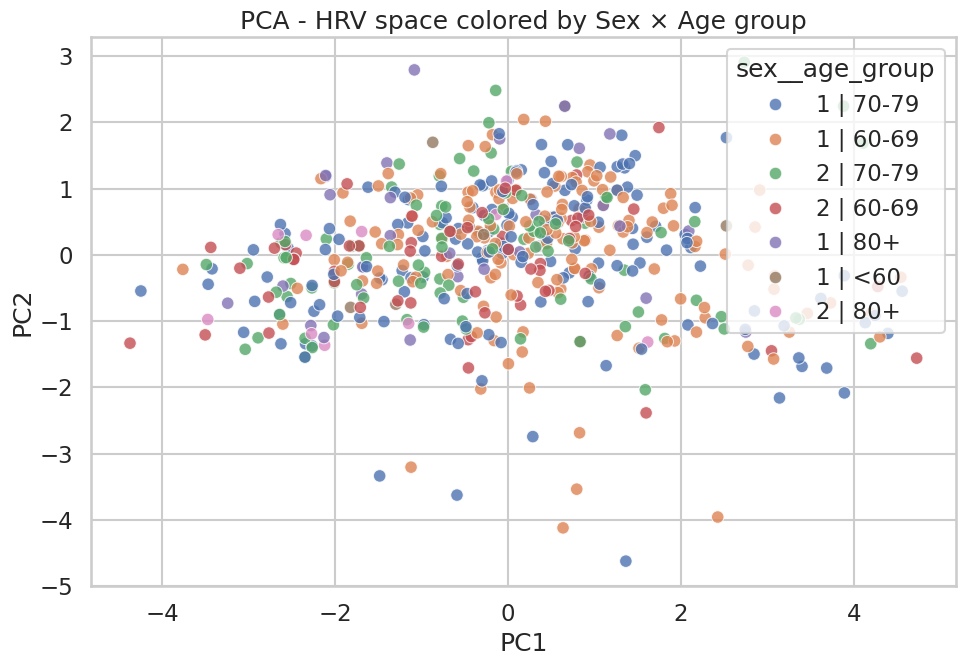

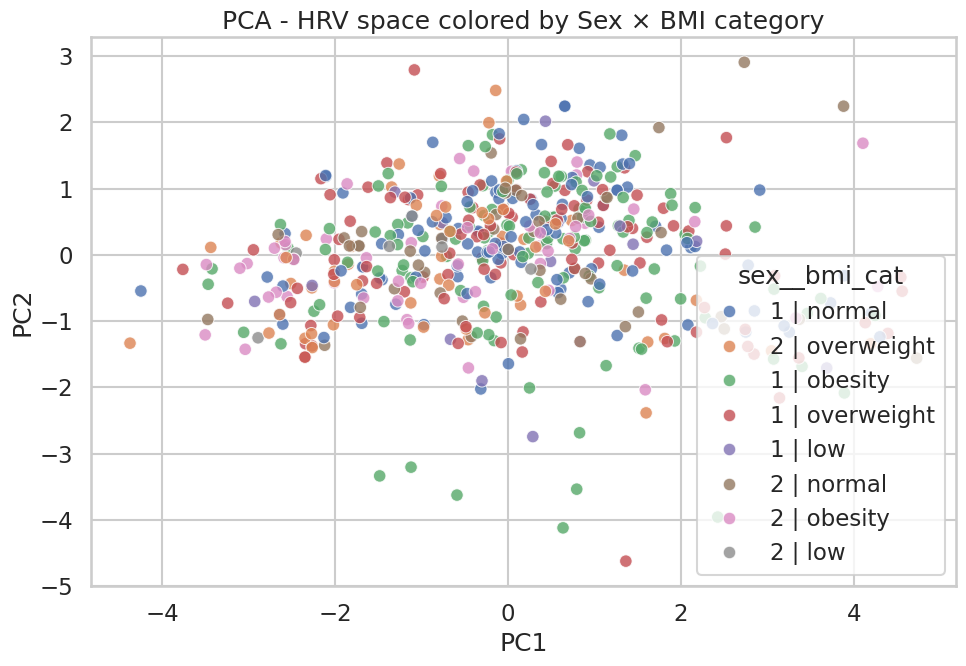

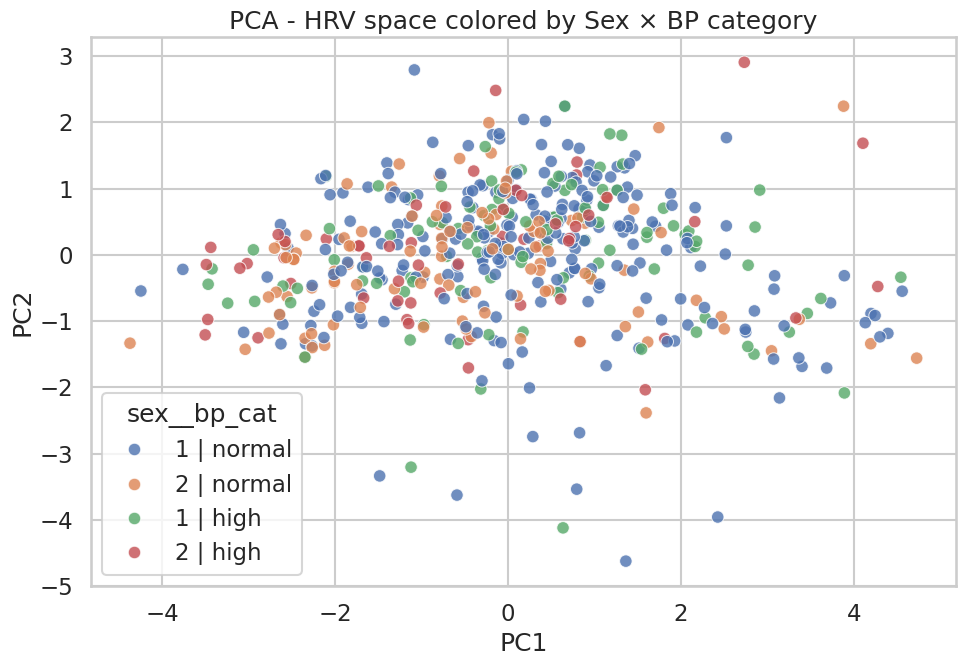

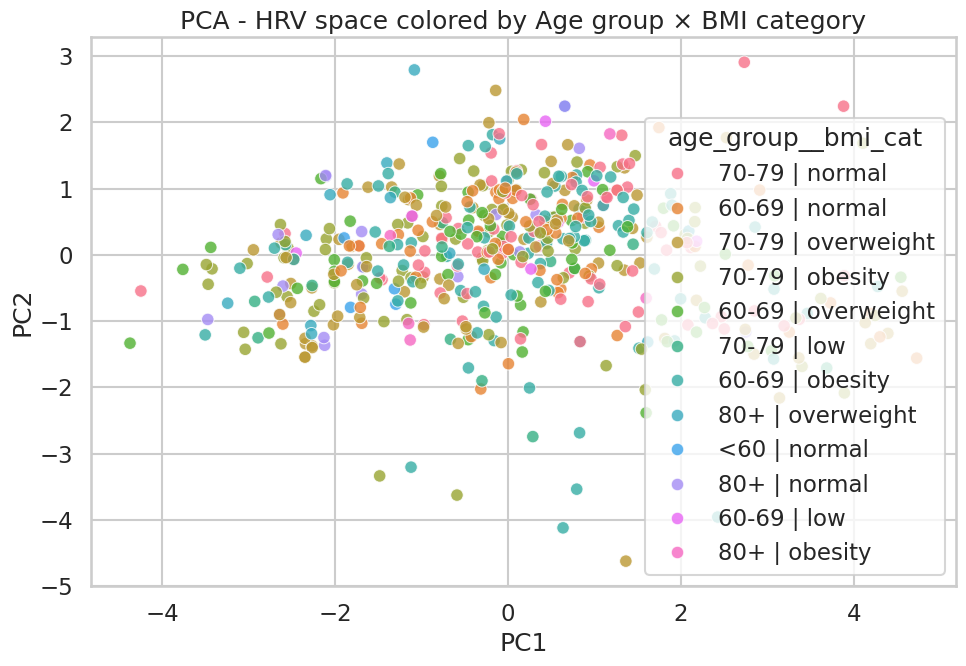

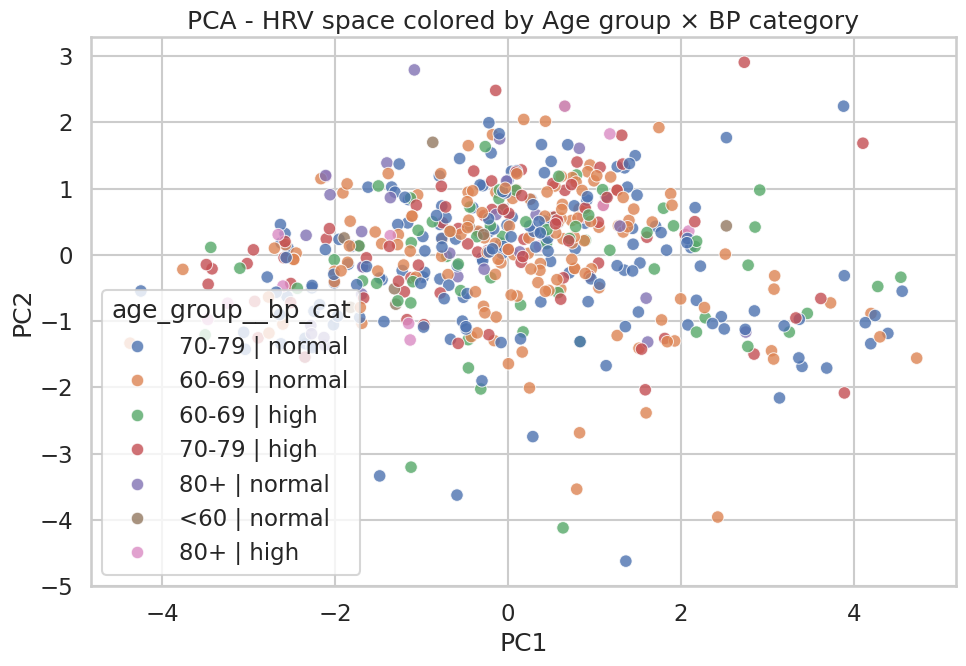

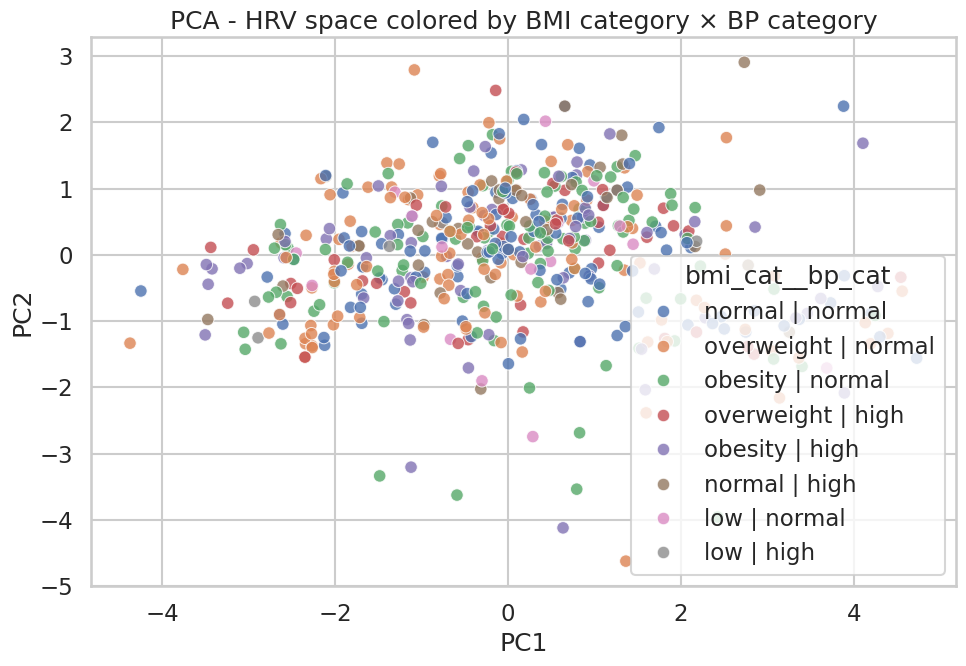

In [74]:
for group_col in combined_double_cols:
    plot_embedding_by_combined_category(
        df_in=scores_hrv,
        x_col="PC1",
        y_col="PC2",
        group_col=group_col,
        title_prefix="PCA - HRV space",
        filename_prefix="pca_hrv_pc1_pc2",
        min_count=5
    )

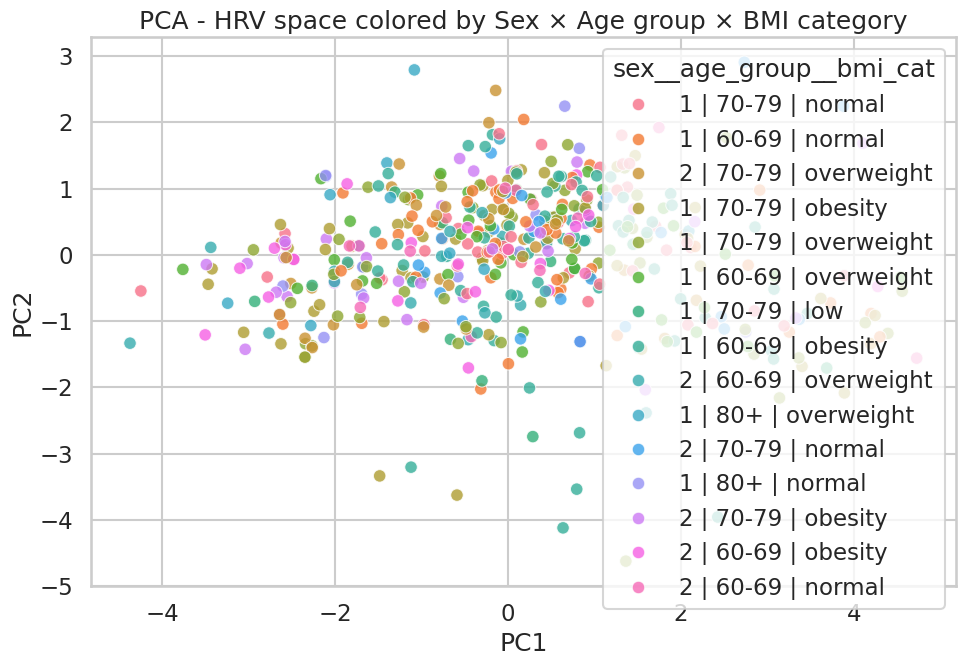

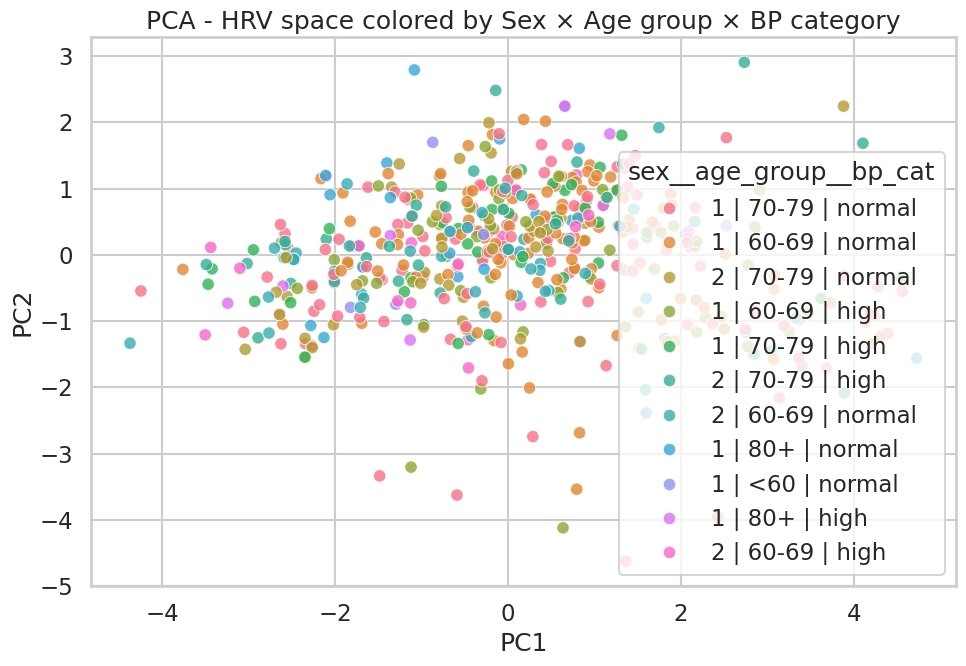

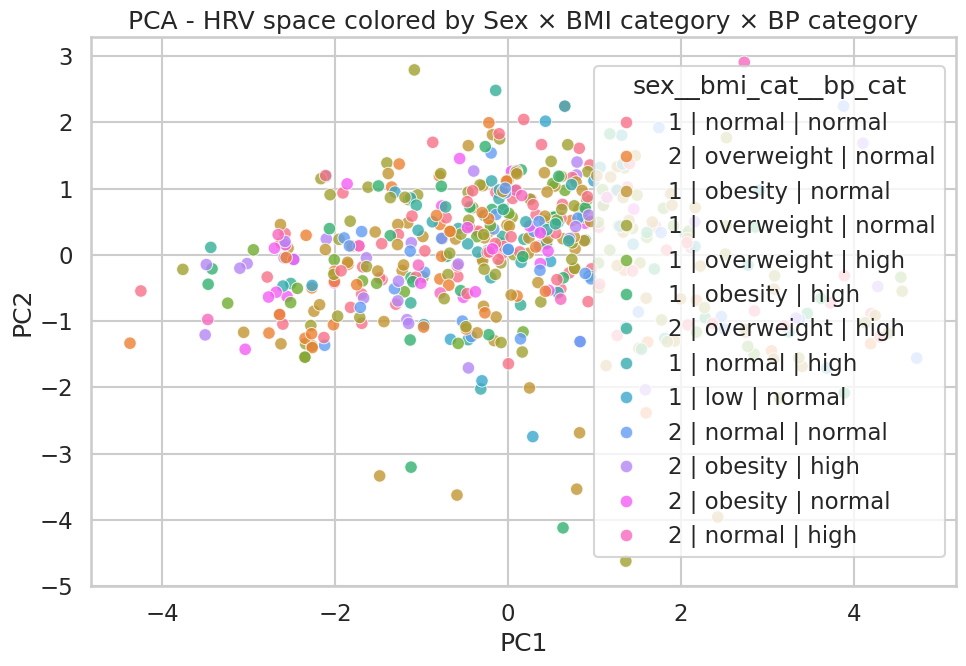

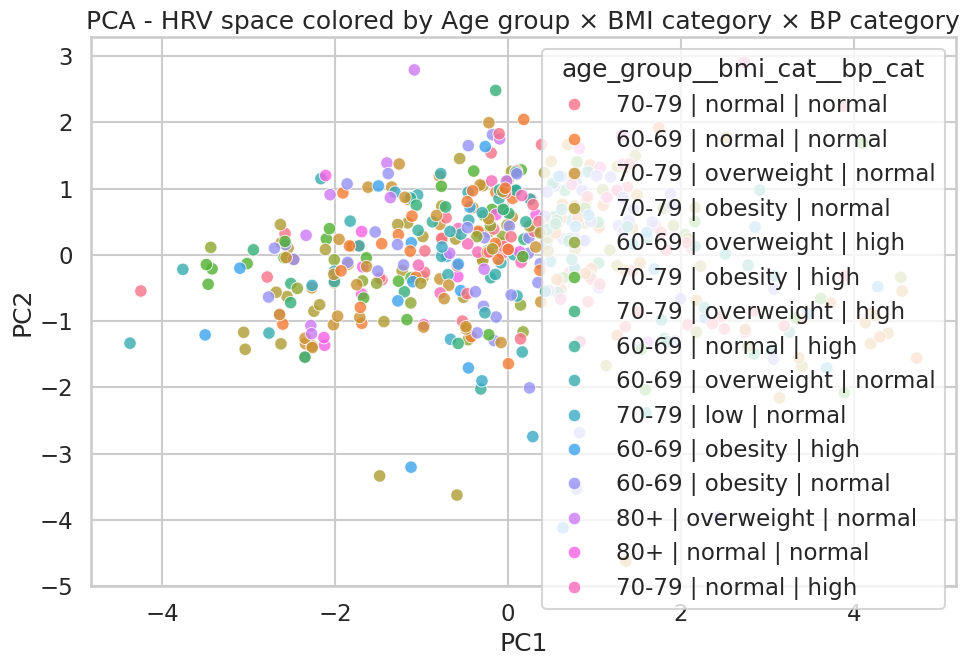

In [75]:
for group_col in combined_triple_cols:
    plot_embedding_by_combined_category(
        df_in=scores_hrv,
        x_col="PC1",
        y_col="PC2",
        group_col=group_col,
        title_prefix="PCA - HRV space",
        filename_prefix="pca_hrv_pc1_pc2",
        min_count=8
    )

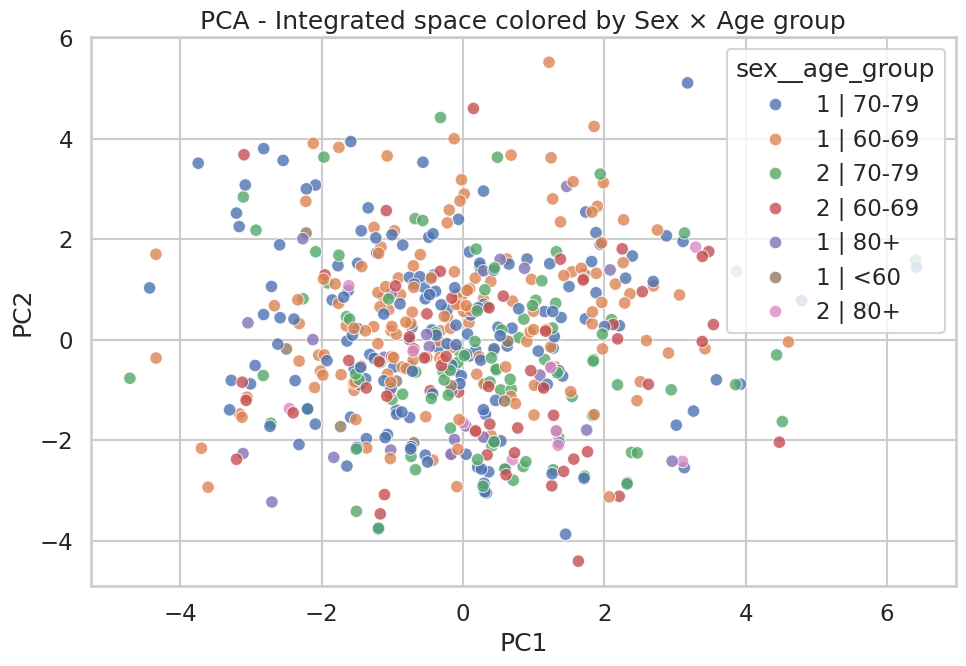

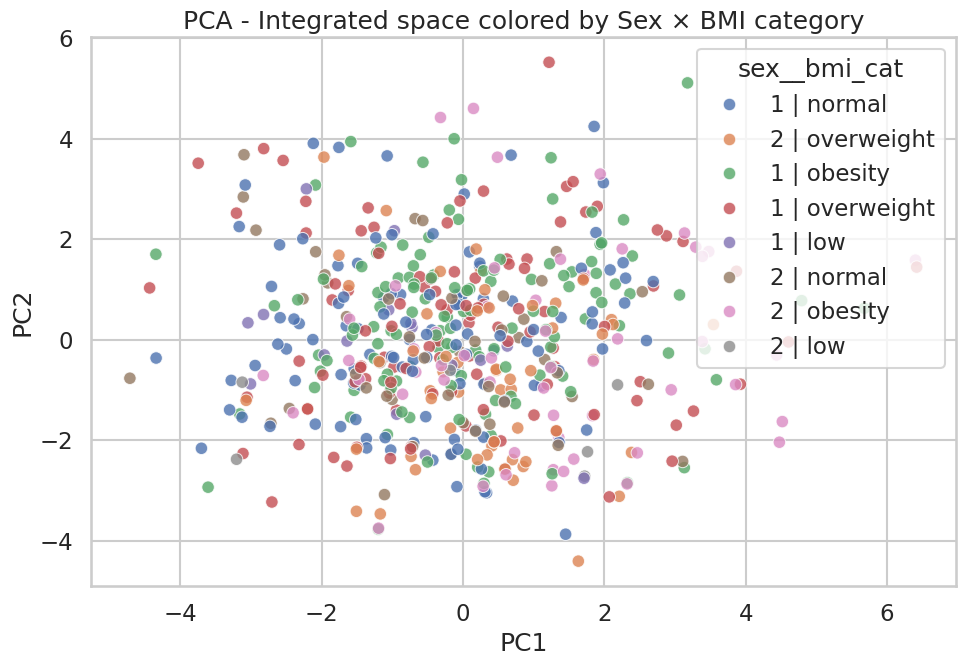

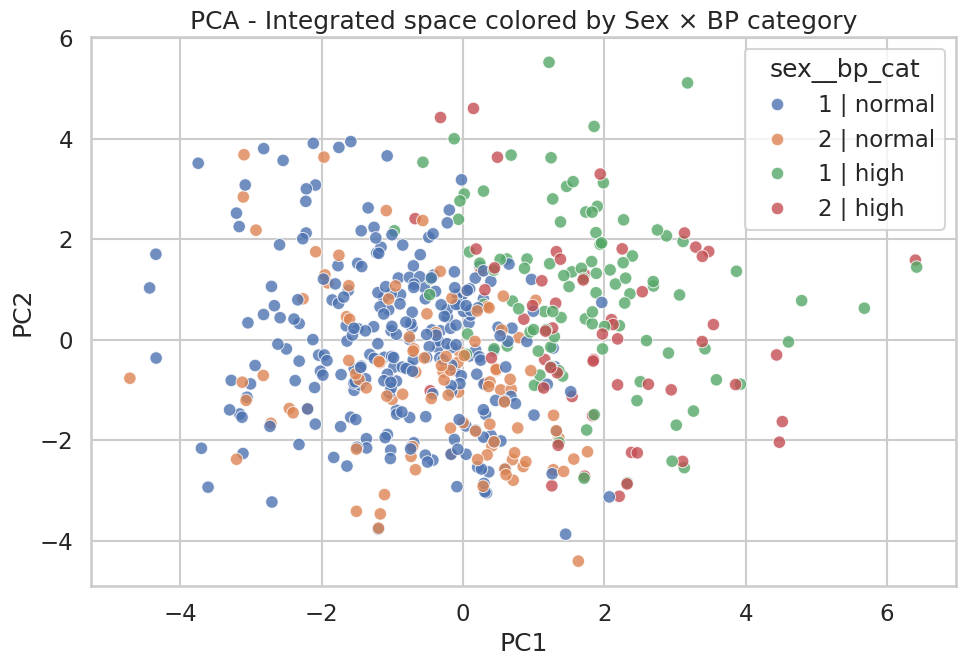

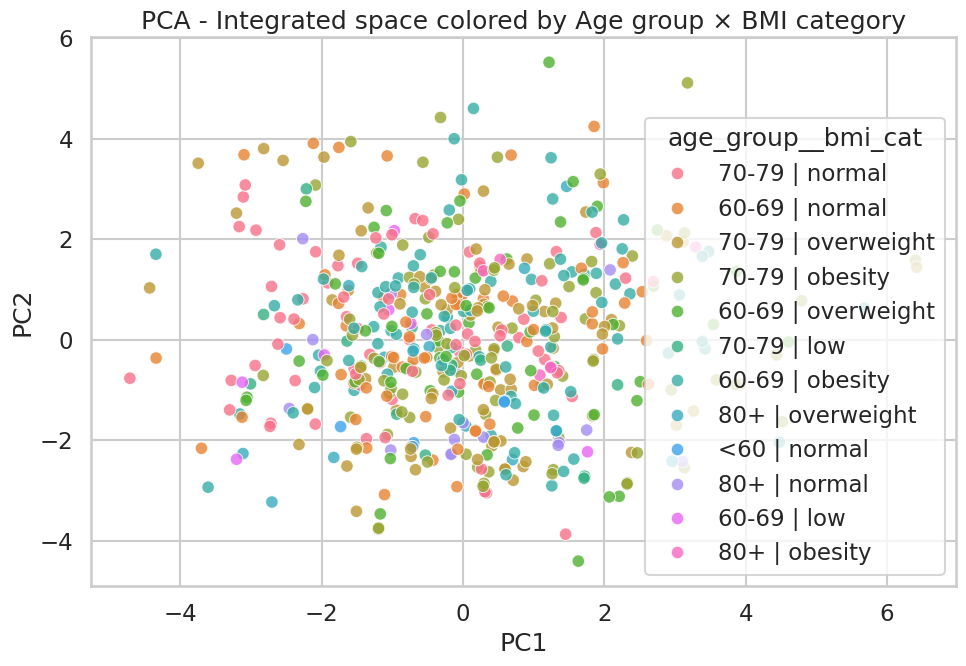

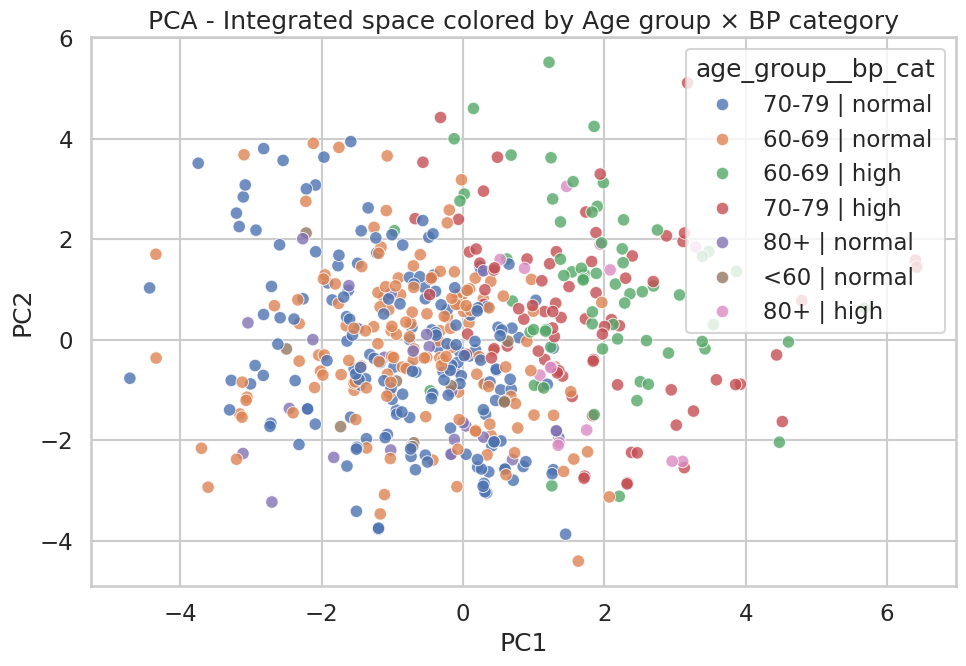

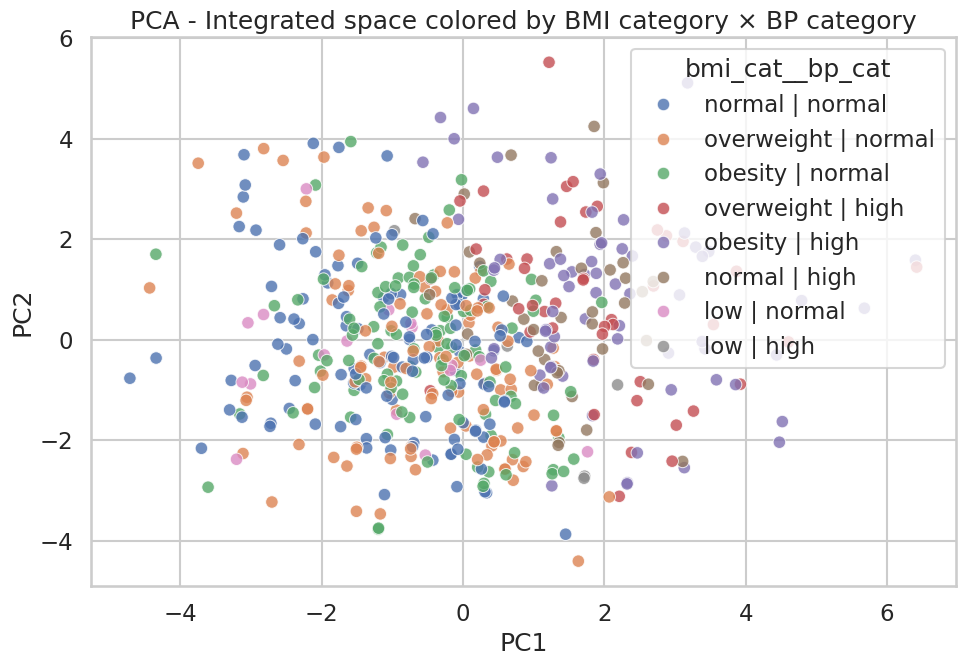

In [76]:
for group_col in combined_double_cols:
    plot_embedding_by_combined_category(
        df_in=scores_int,
        x_col="PC1",
        y_col="PC2",
        group_col=group_col,
        title_prefix="PCA - Integrated space",
        filename_prefix="pca_integrated_pc1_pc2",
        min_count=5
    )

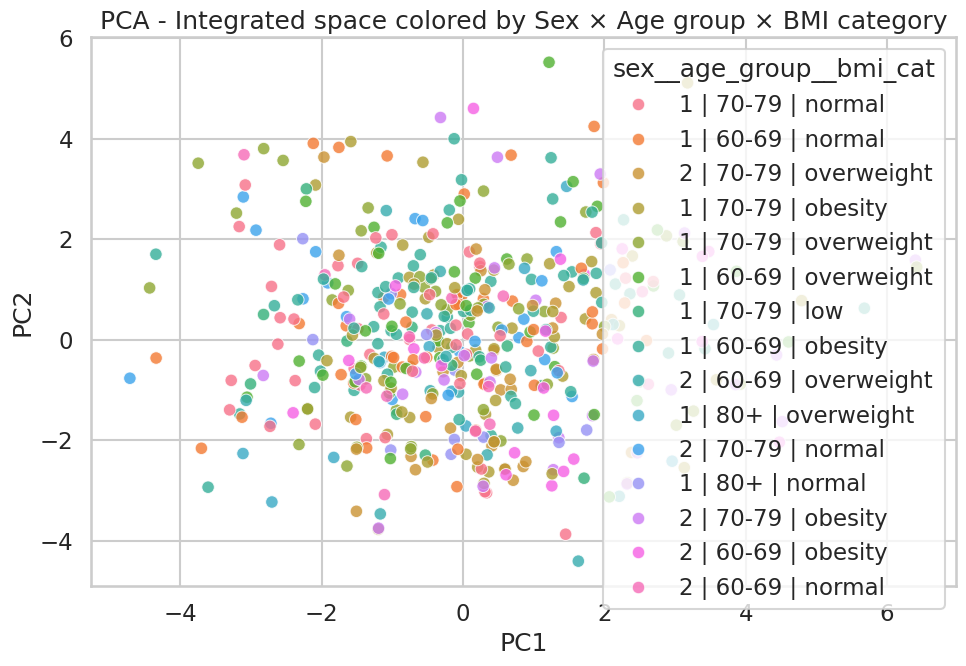

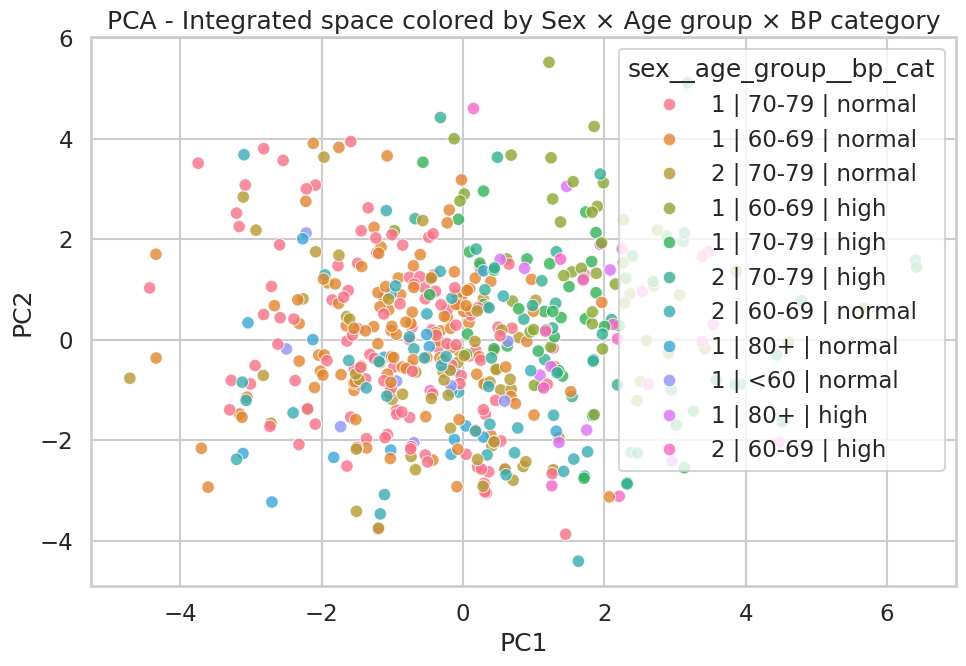

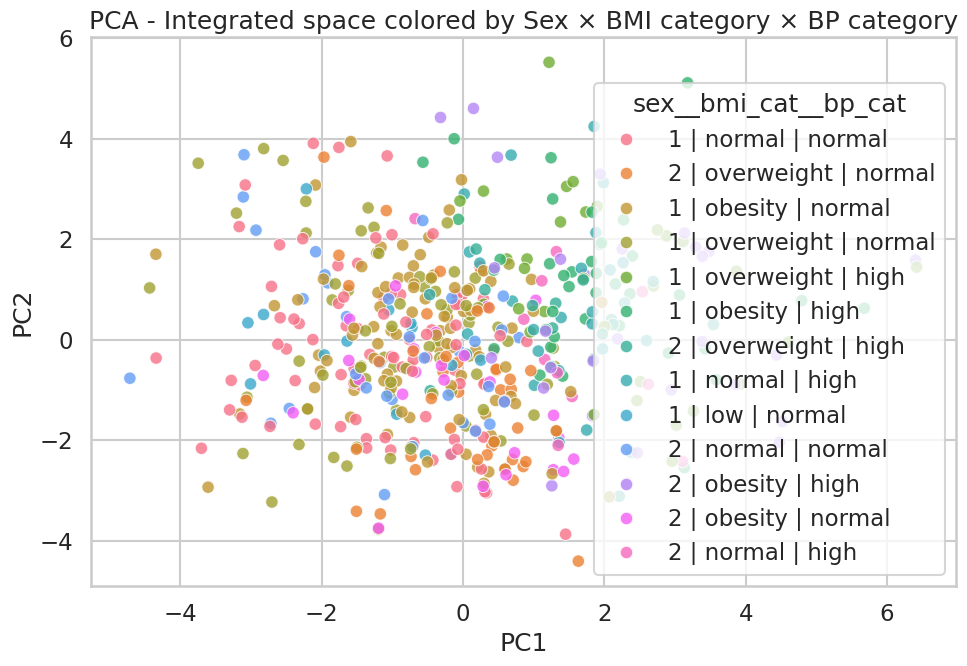

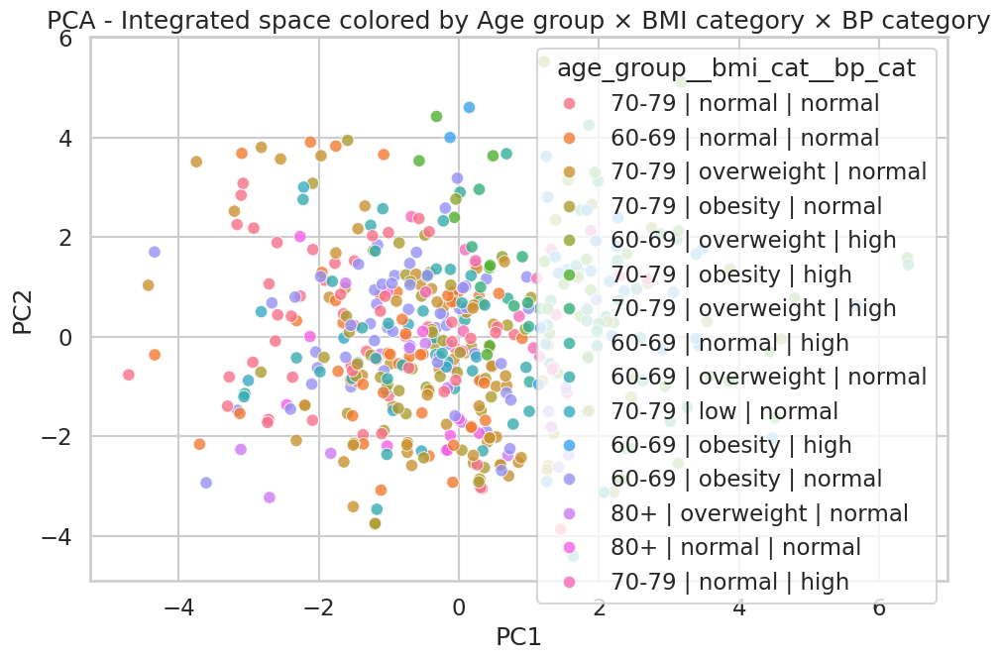

In [77]:
for group_col in combined_triple_cols:
    plot_embedding_by_combined_category(
        df_in=scores_int,
        x_col="PC1",
        y_col="PC2",
        group_col=group_col,
        title_prefix="PCA - Integrated space",
        filename_prefix="pca_integrated_pc1_pc2",
        min_count=8
    )

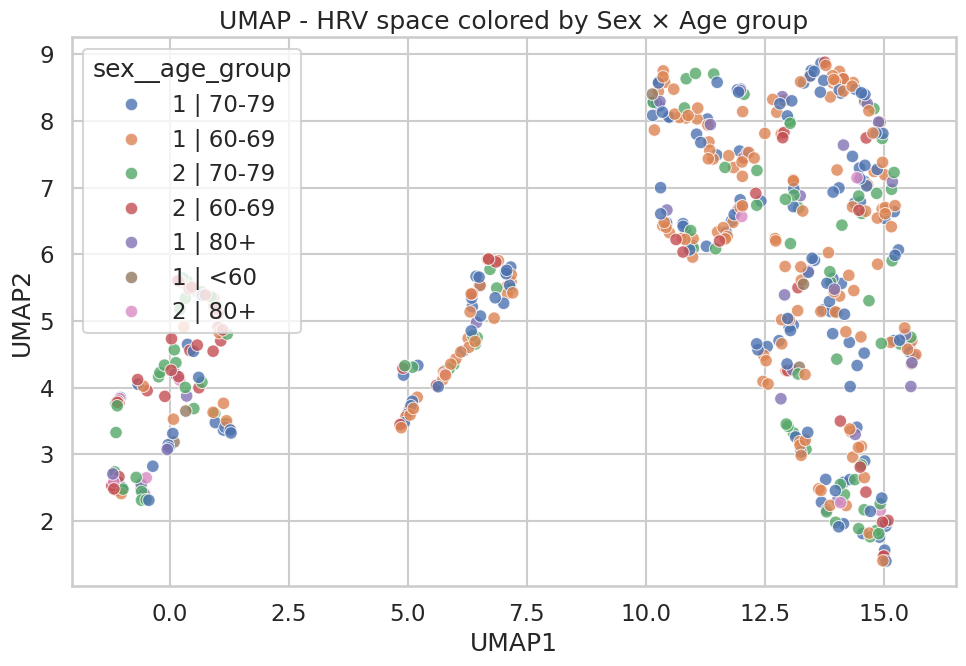

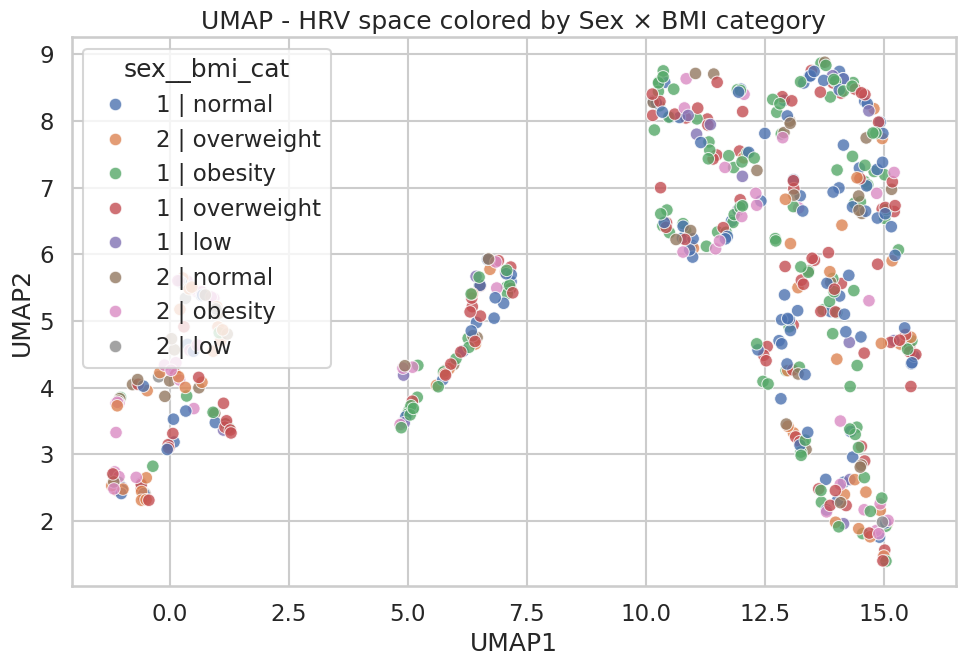

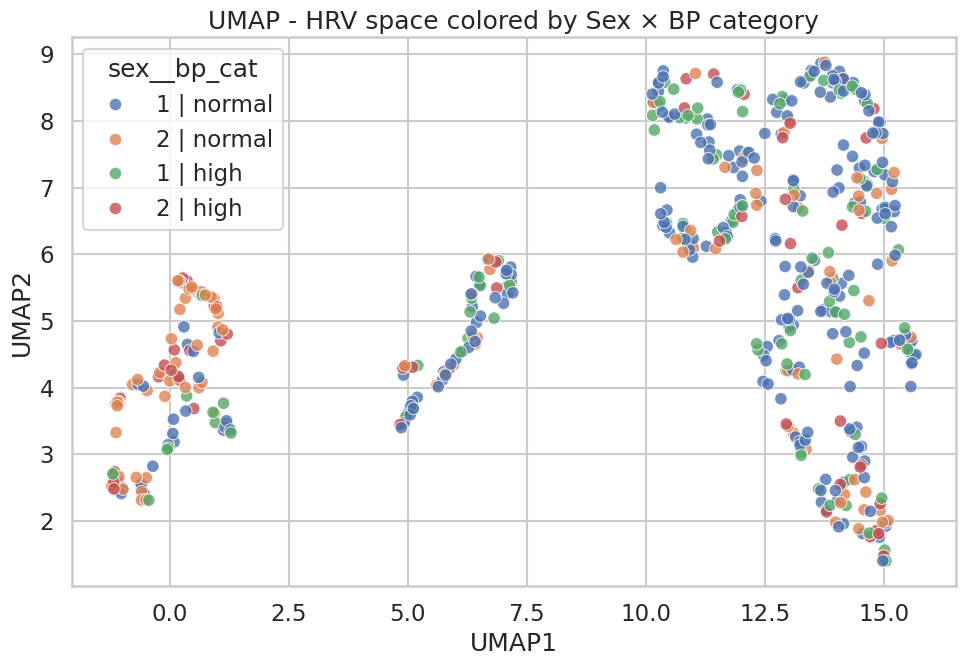

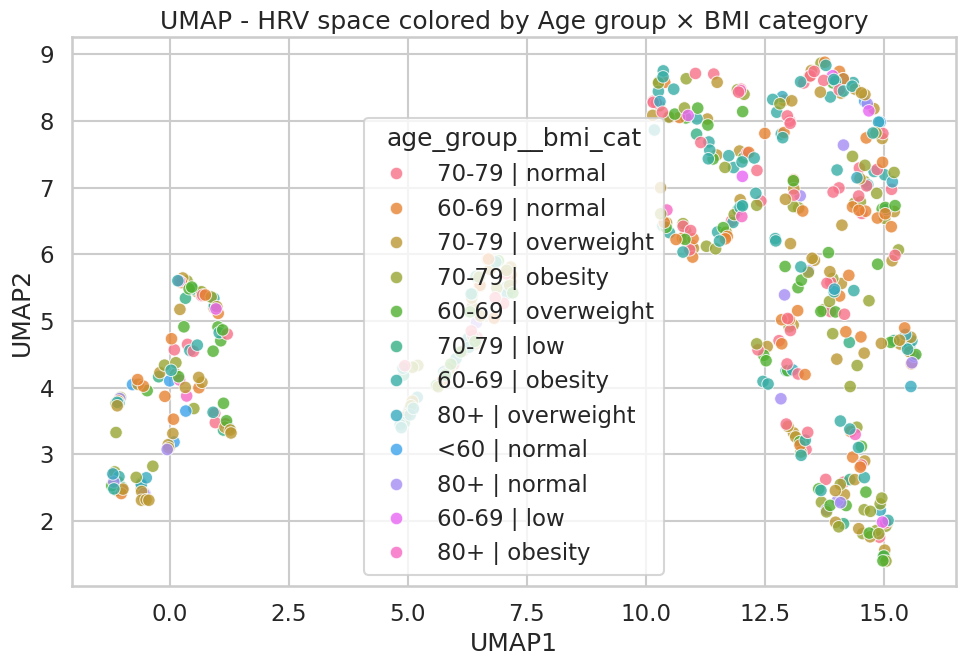

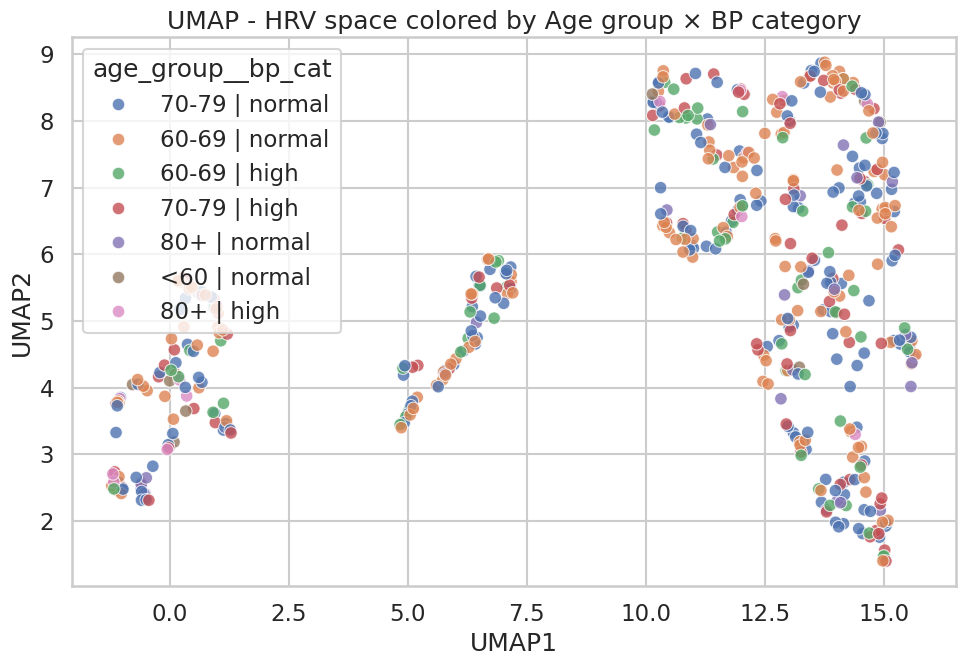

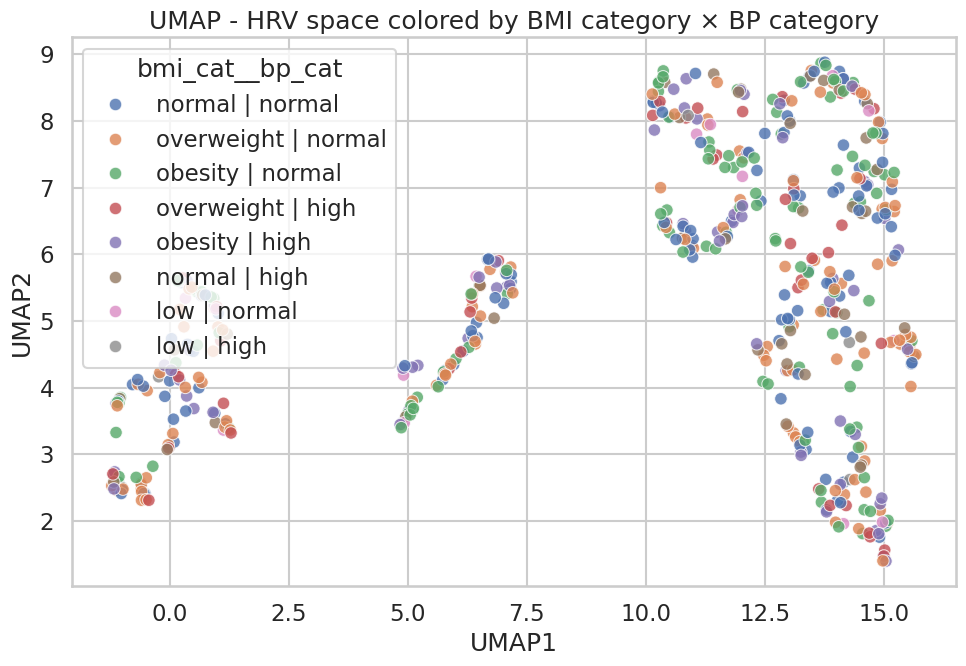

In [78]:
if HAS_UMAP:
    for group_col in combined_double_cols:
        plot_embedding_by_combined_category(
            df_in=umap_hrv_df,
            x_col="UMAP1",
            y_col="UMAP2",
            group_col=group_col,
            title_prefix="UMAP - HRV space",
            filename_prefix="umap_hrv",
            min_count=5
        )

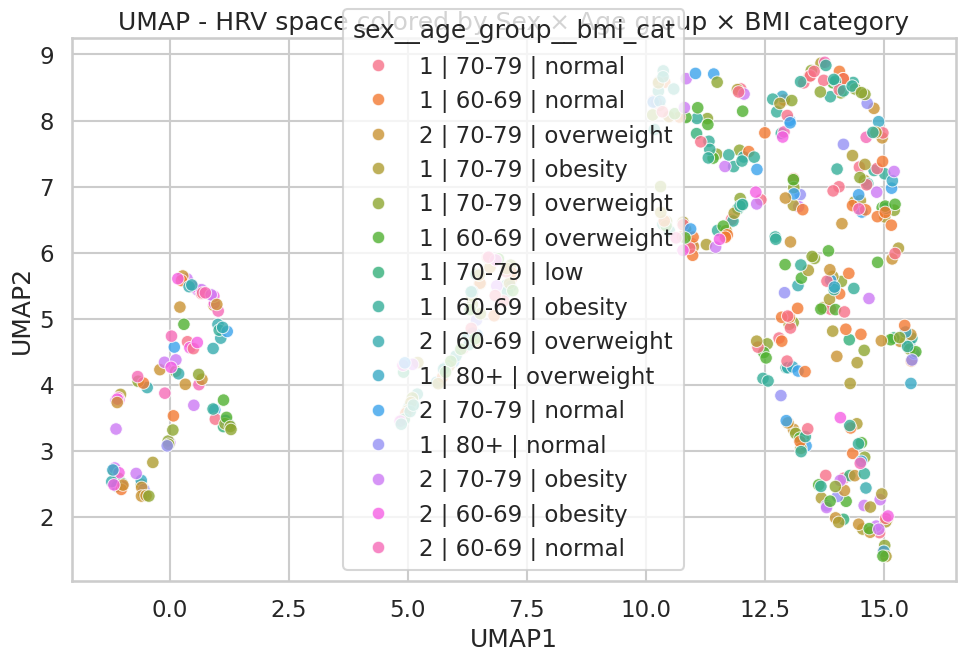

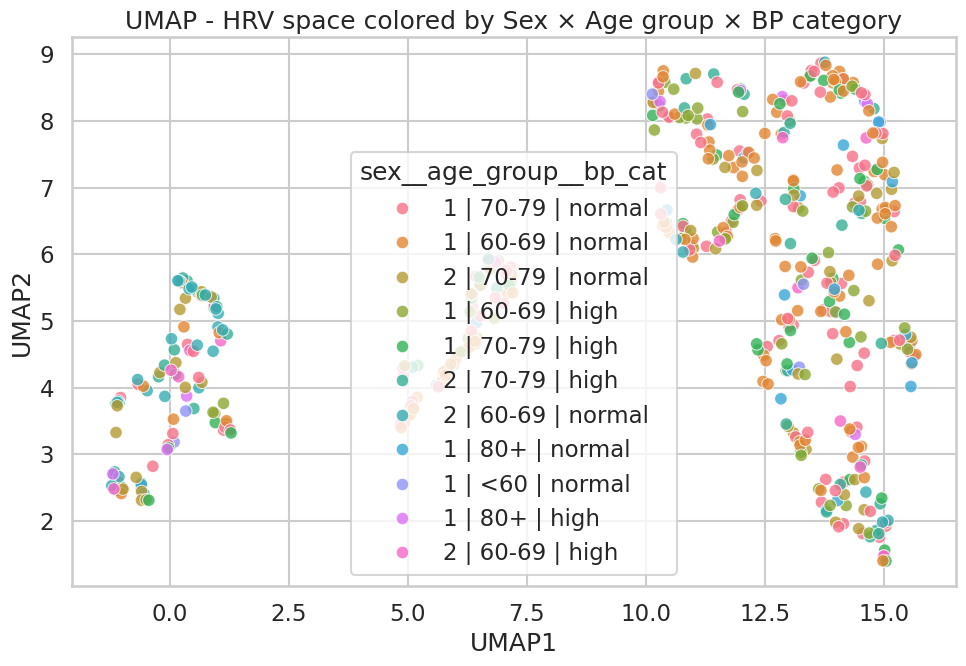

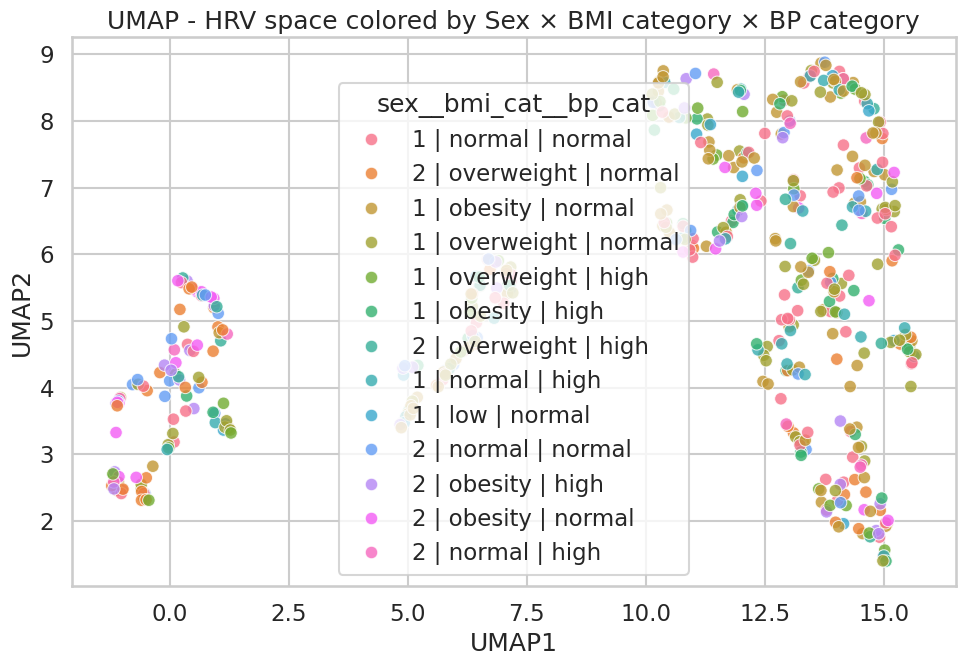

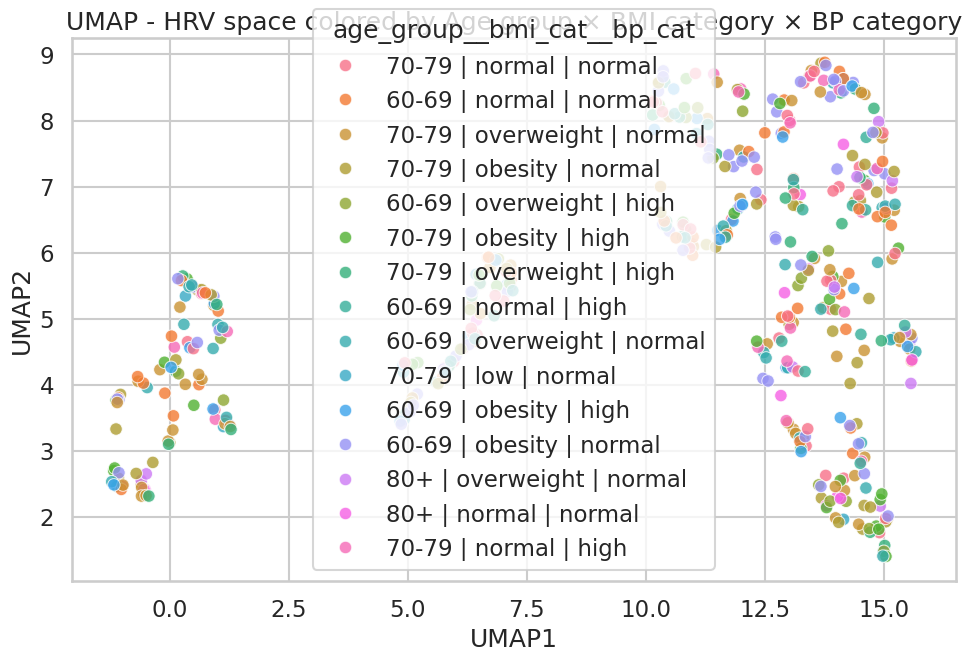

In [79]:
if HAS_UMAP:
    for group_col in combined_triple_cols:
        plot_embedding_by_combined_category(
            df_in=umap_hrv_df,
            x_col="UMAP1",
            y_col="UMAP2",
            group_col=group_col,
            title_prefix="UMAP - HRV space",
            filename_prefix="umap_hrv",
            min_count=8
        )

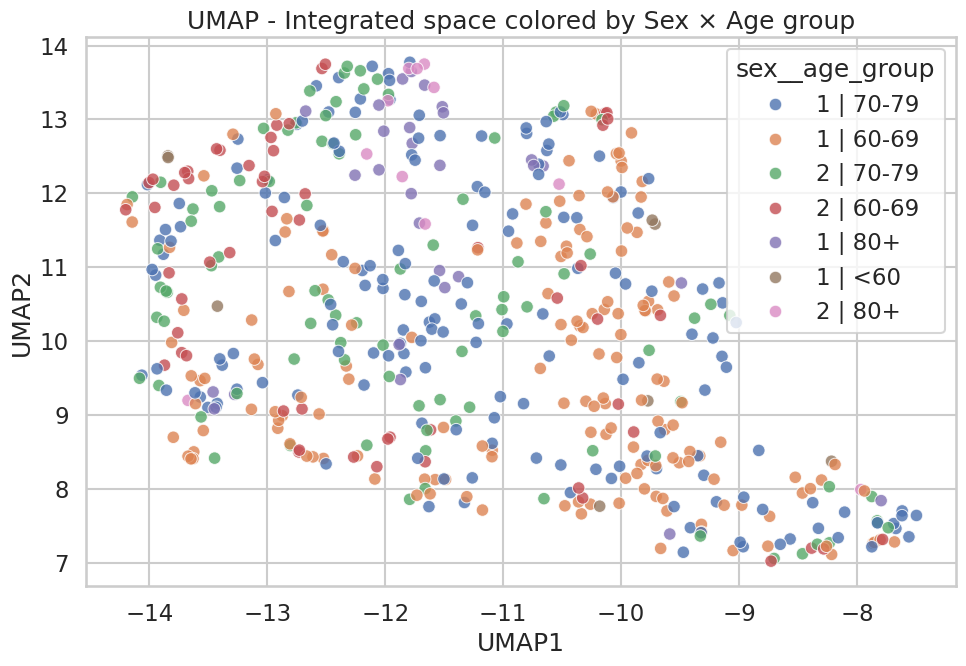

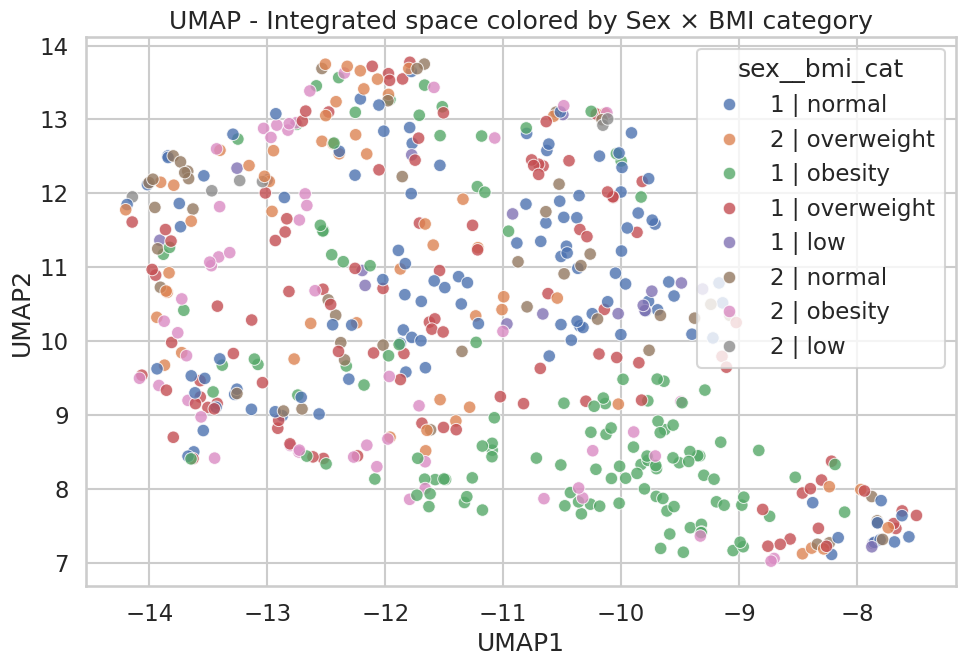

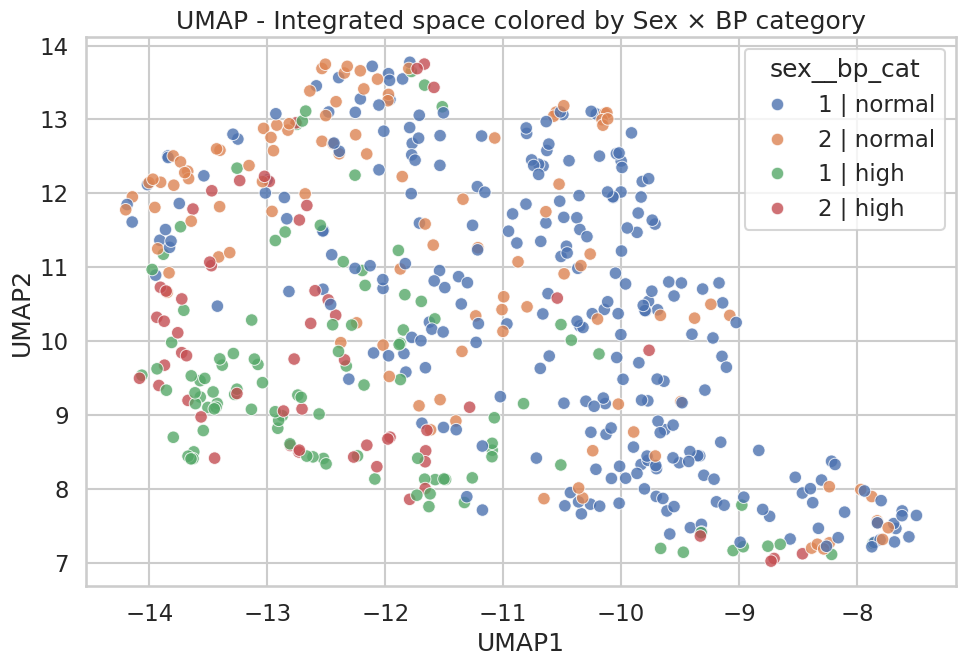

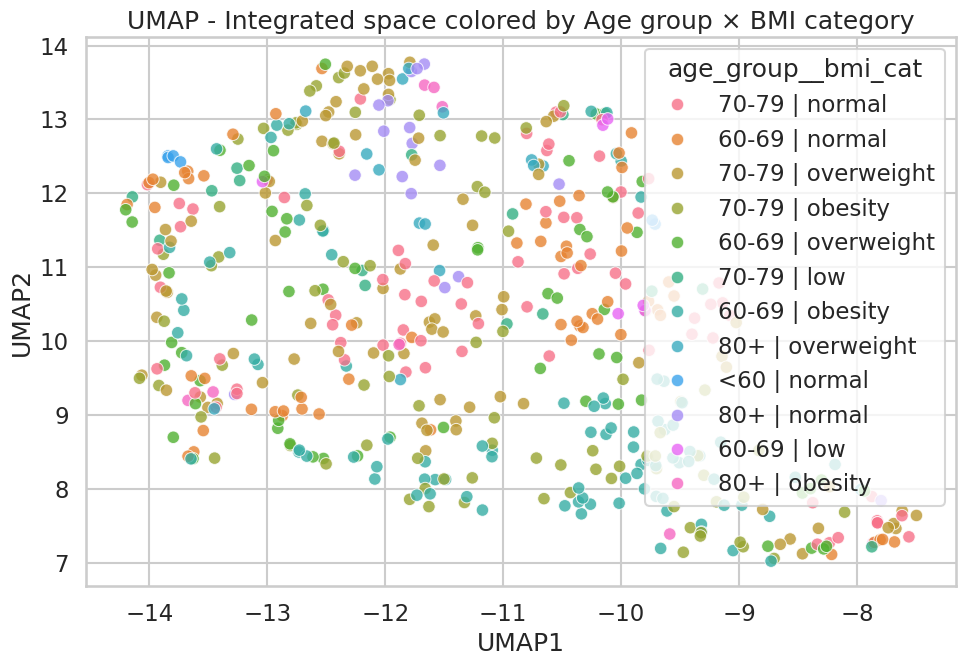

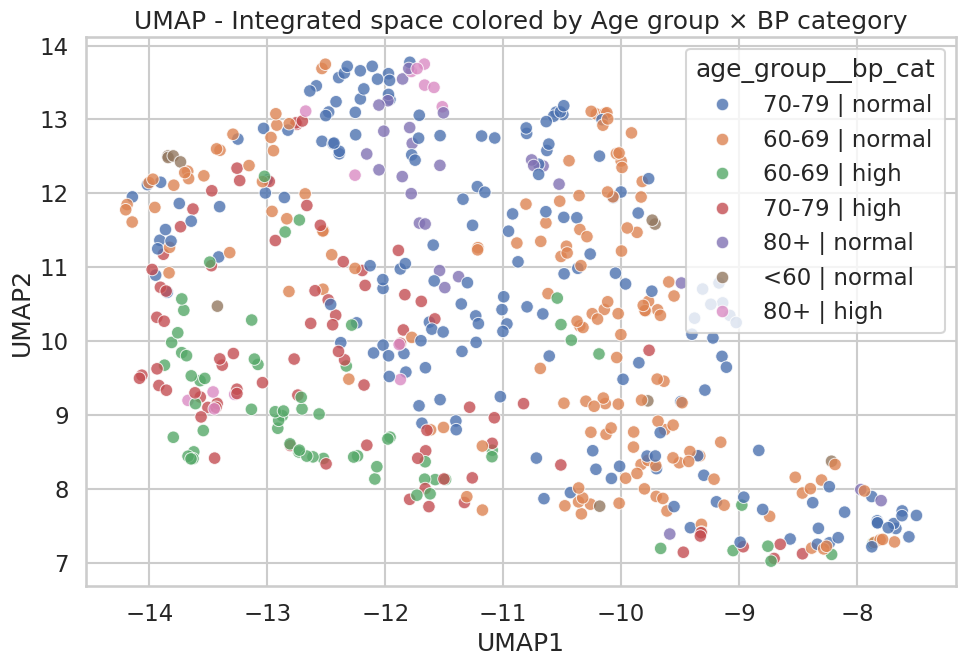

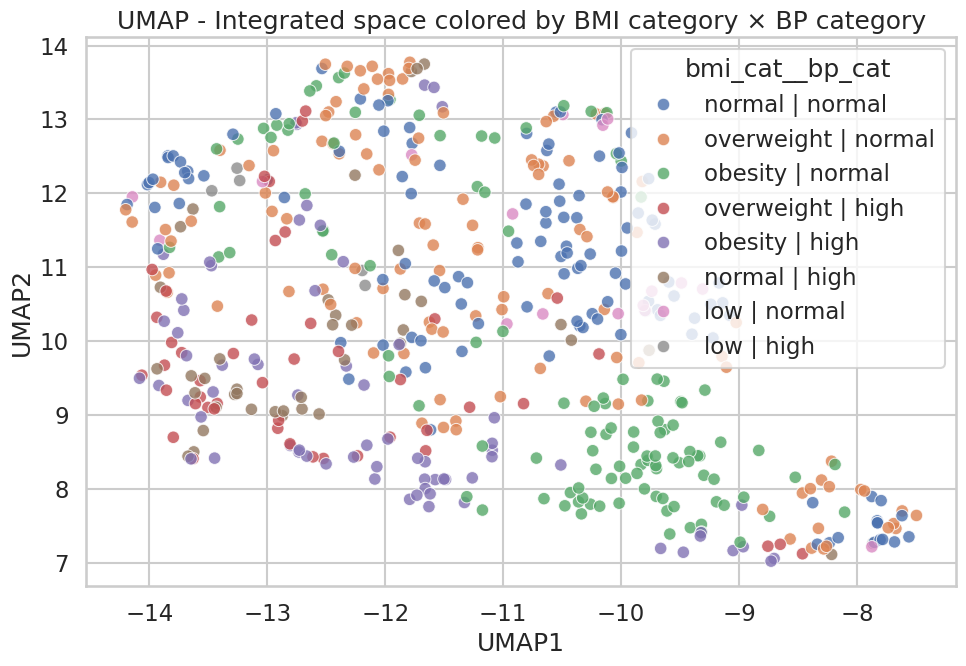

In [80]:
if HAS_UMAP:
    for group_col in combined_double_cols:
        plot_embedding_by_combined_category(
            df_in=umap_int_df,
            x_col="UMAP1",
            y_col="UMAP2",
            group_col=group_col,
            title_prefix="UMAP - Integrated space",
            filename_prefix="umap_integrated",
            min_count=5
        )

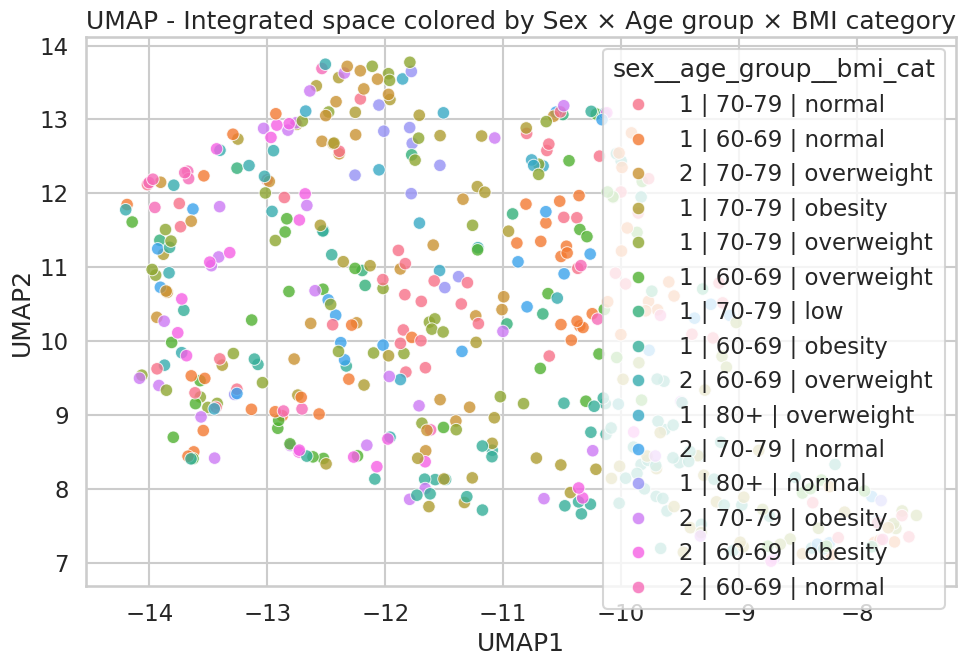

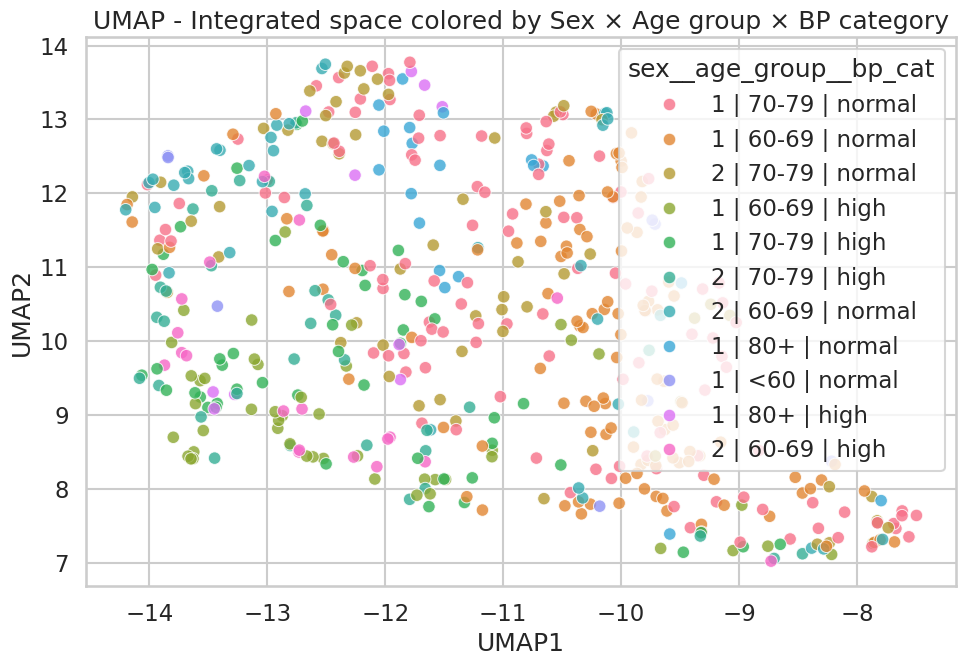

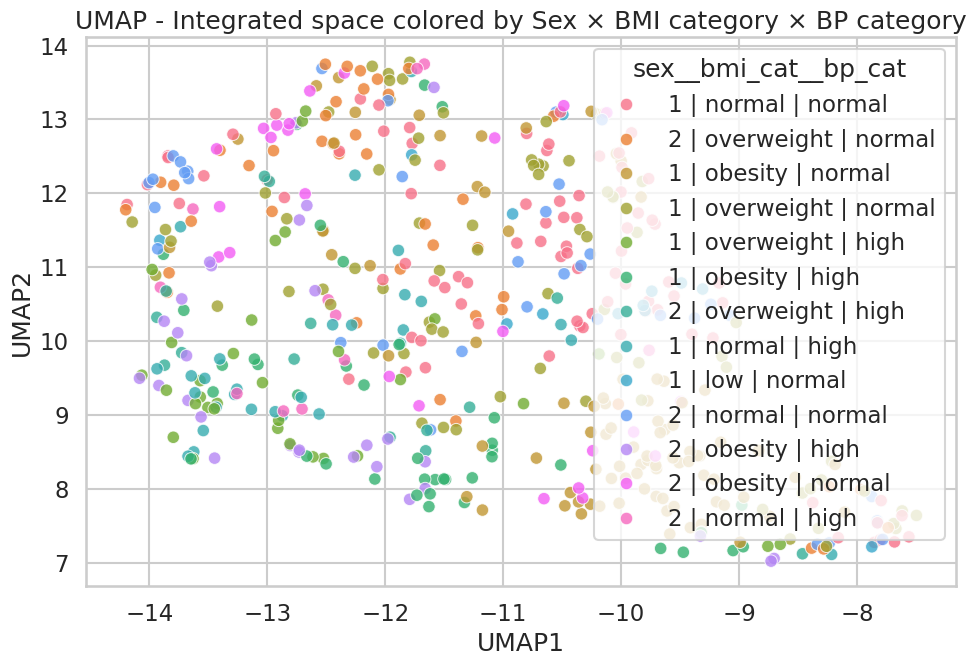

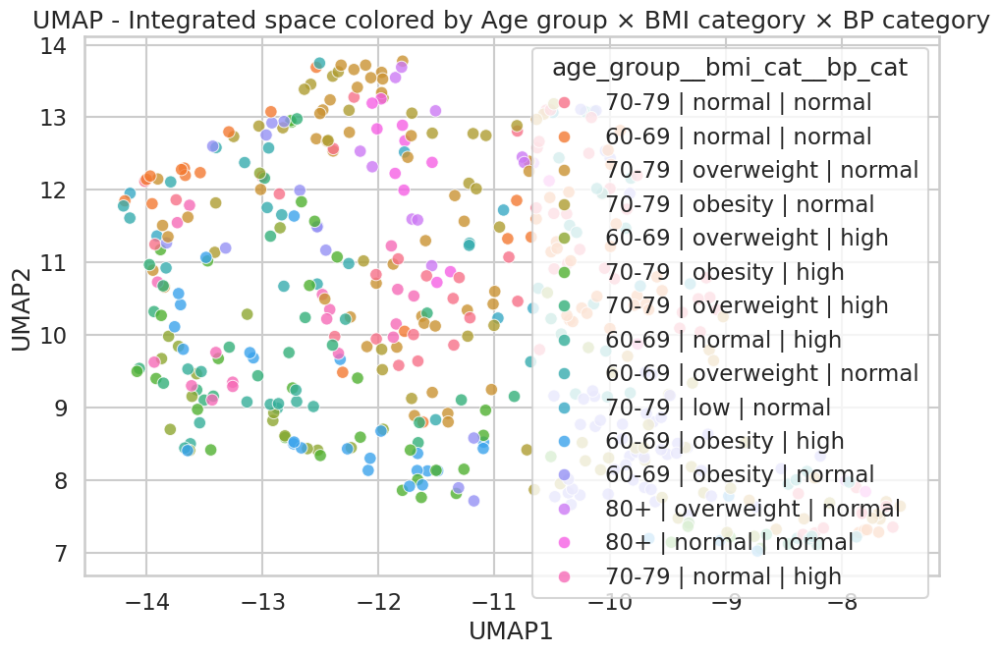

In [81]:
if HAS_UMAP:
    for group_col in combined_triple_cols:
        plot_embedding_by_combined_category(
            df_in=umap_int_df,
            x_col="UMAP1",
            y_col="UMAP2",
            group_col=group_col,
            title_prefix="UMAP - Integrated space",
            filename_prefix="umap_integrated",
            min_count=8
        )

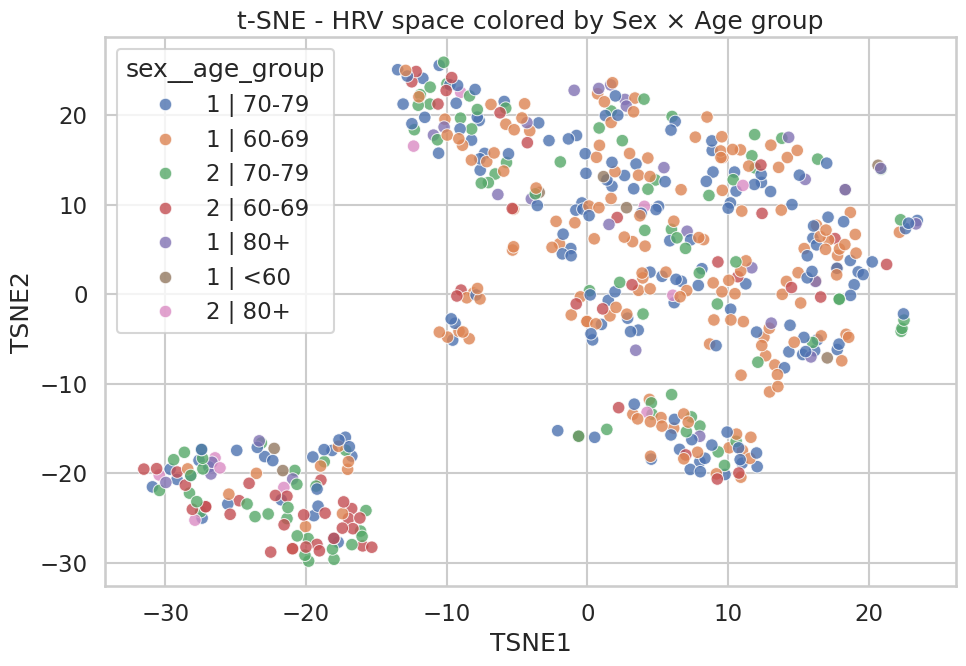

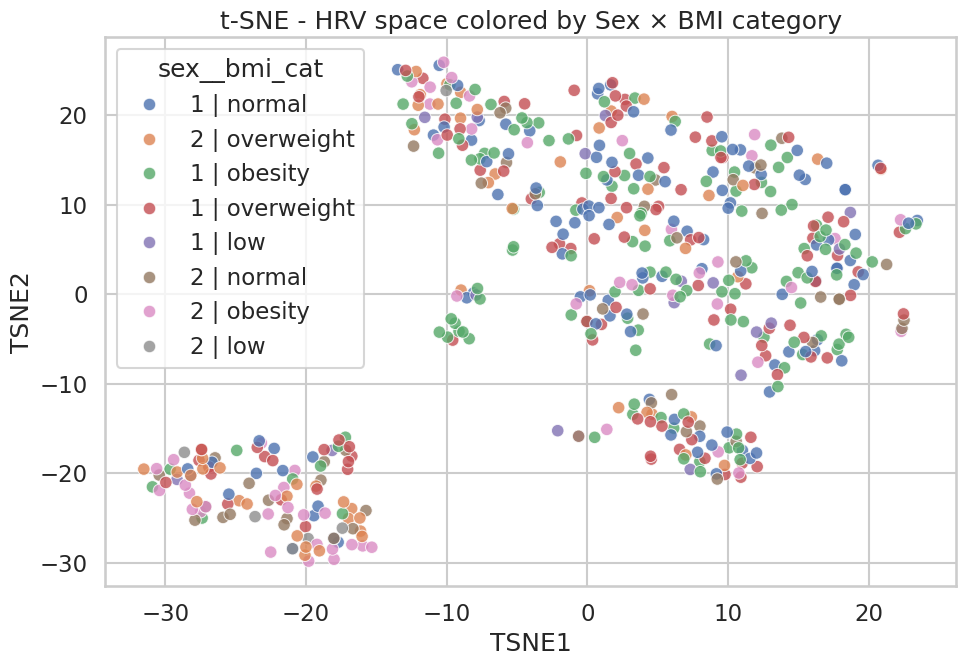

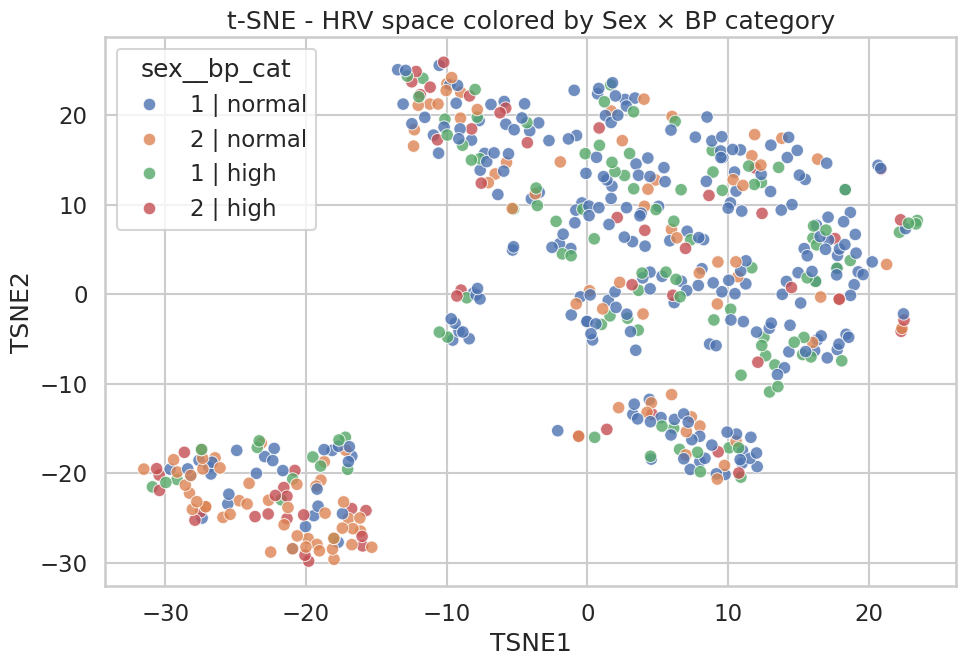

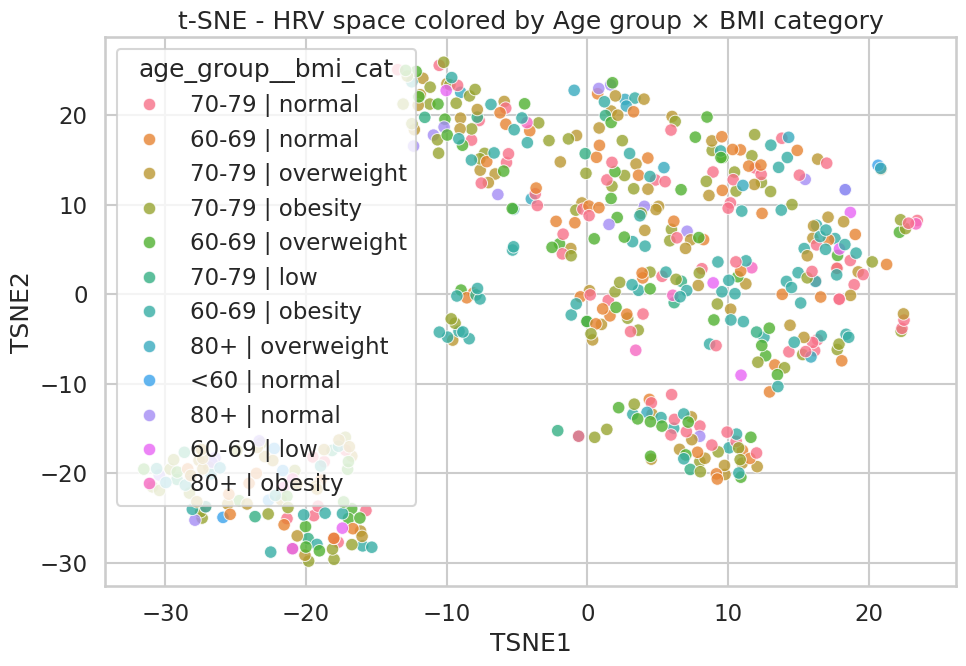

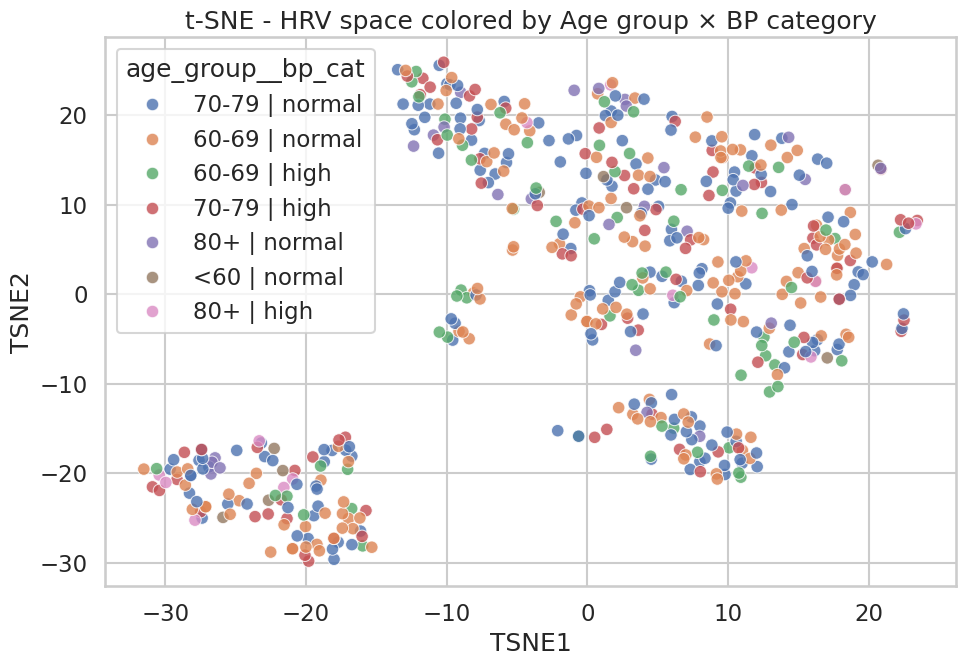

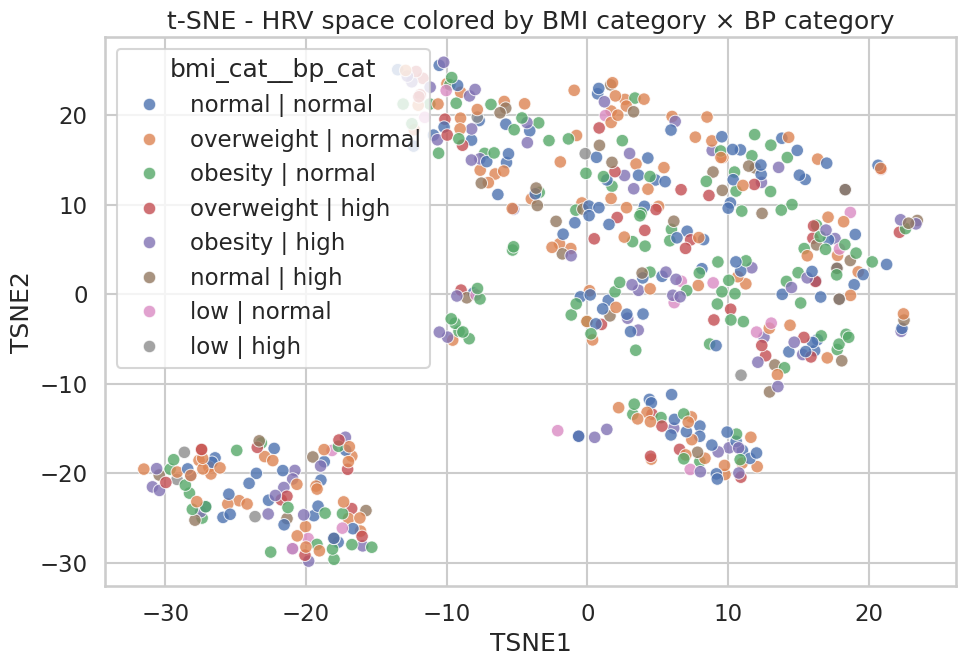

In [82]:
for group_col in combined_double_cols:
    plot_embedding_by_combined_category(
        df_in=tsne_hrv_df,
        x_col="TSNE1",
        y_col="TSNE2",
        group_col=group_col,
        title_prefix="t-SNE - HRV space",
        filename_prefix="tsne_hrv",
        min_count=5
    )

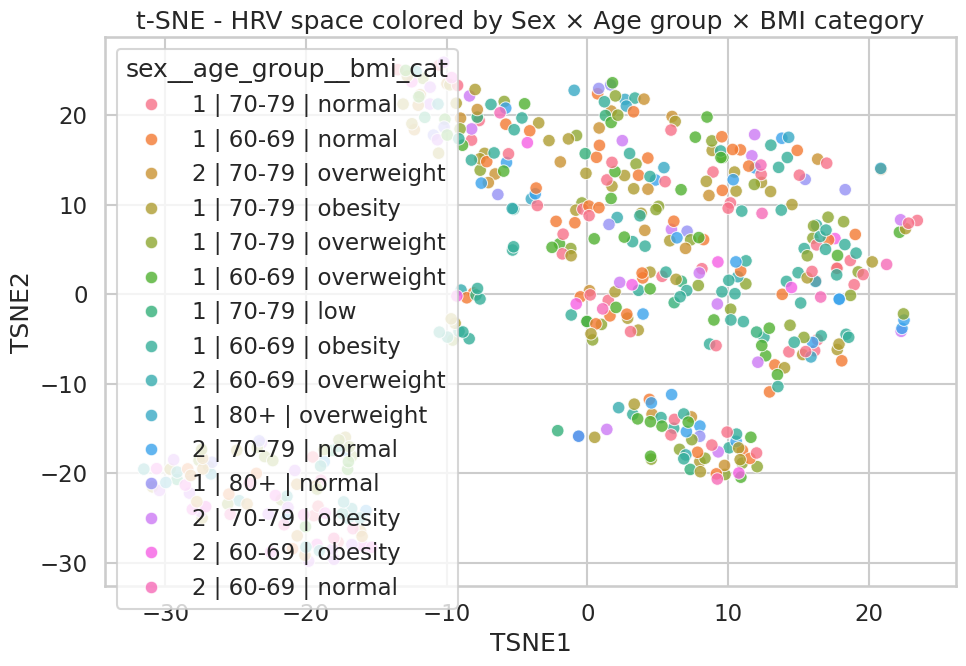

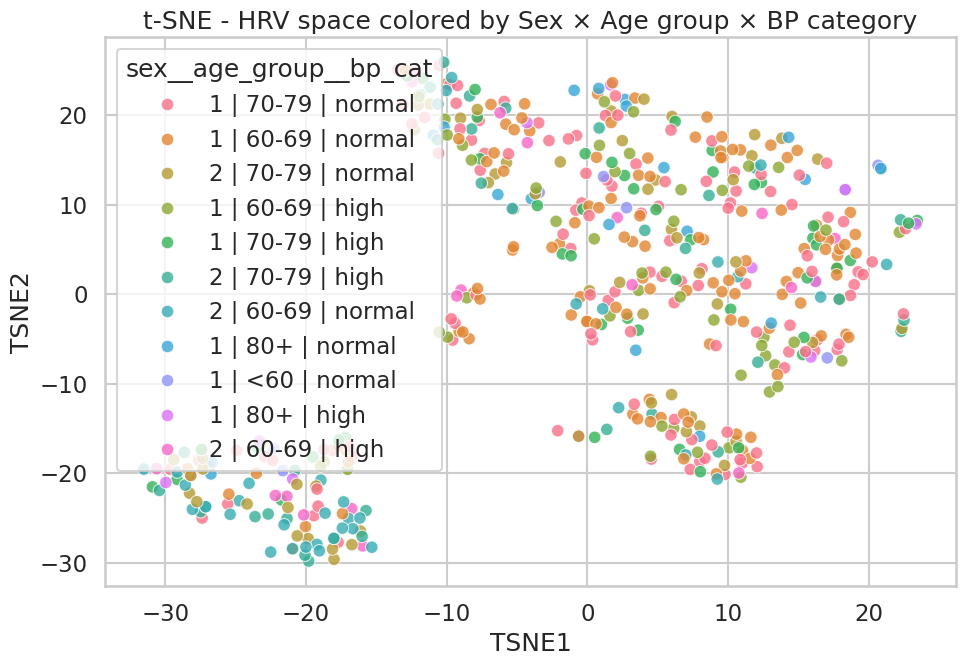

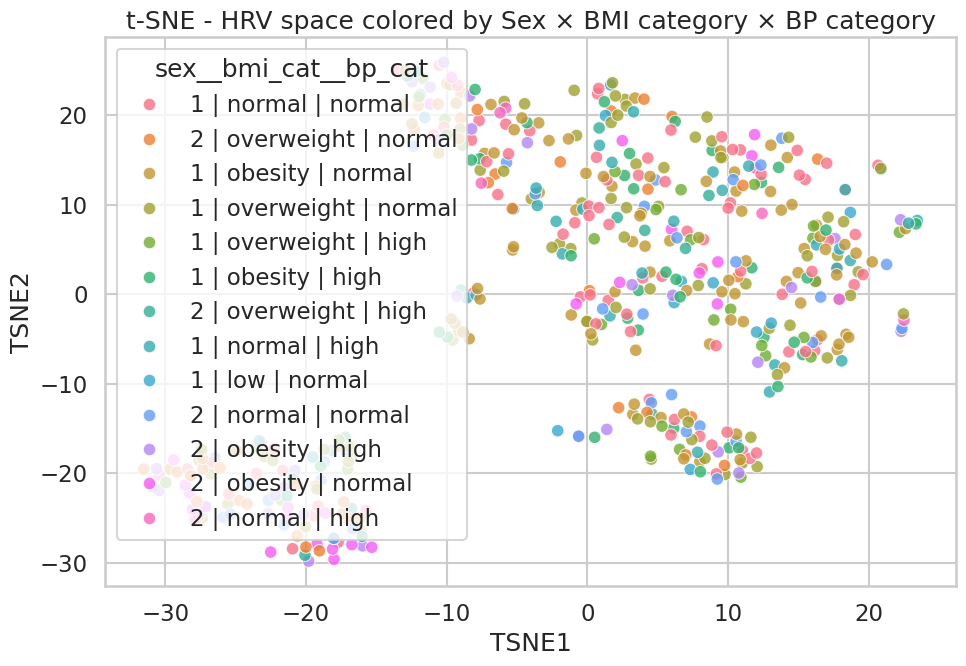

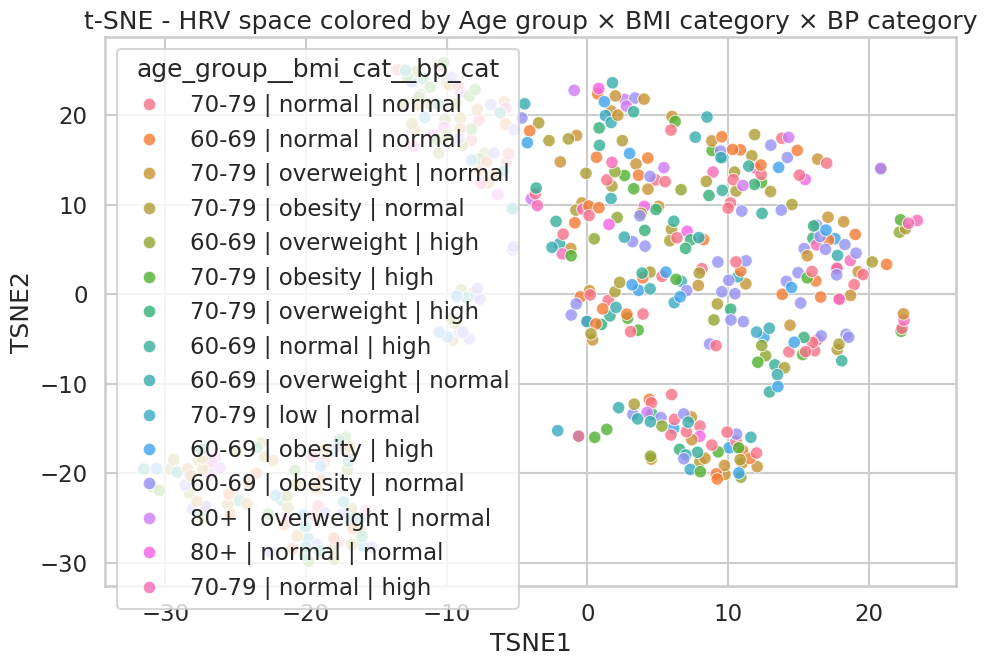

In [83]:
for group_col in combined_triple_cols:
    plot_embedding_by_combined_category(
        df_in=tsne_hrv_df,
        x_col="TSNE1",
        y_col="TSNE2",
        group_col=group_col,
        title_prefix="t-SNE - HRV space",
        filename_prefix="tsne_hrv",
        min_count=8
    )

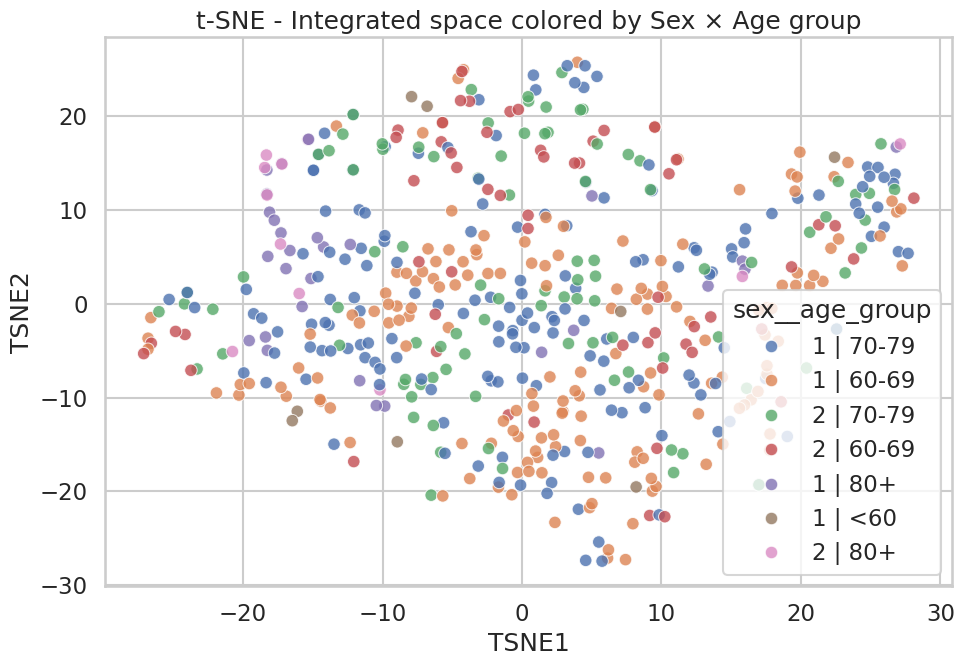

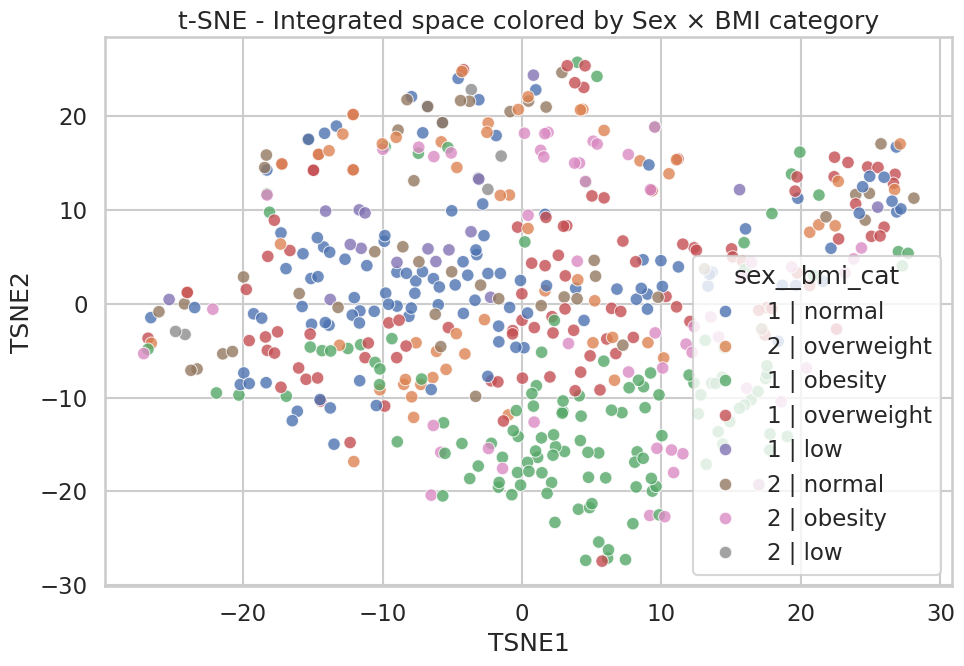

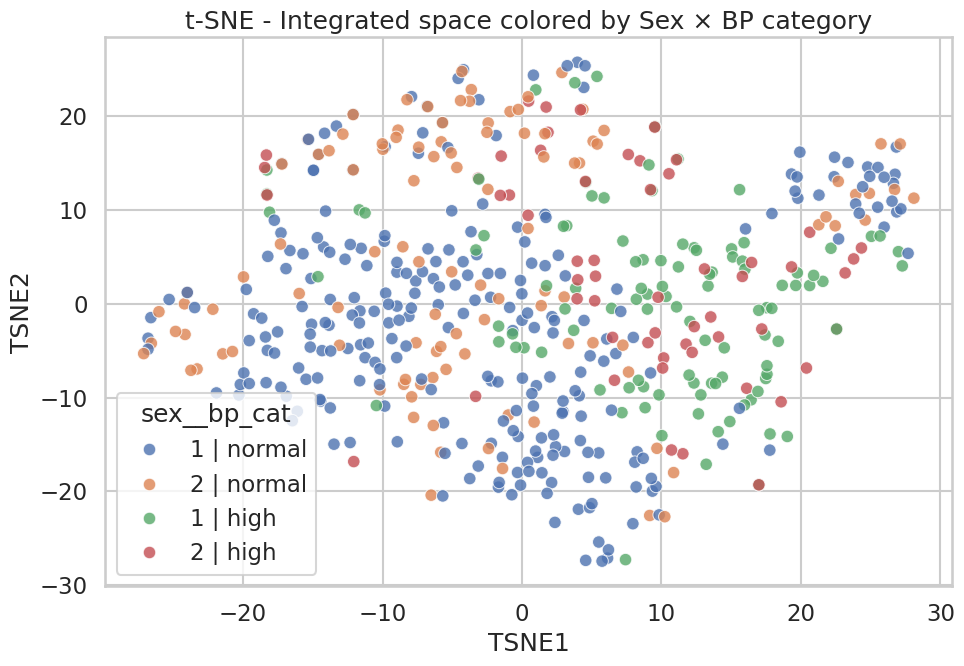

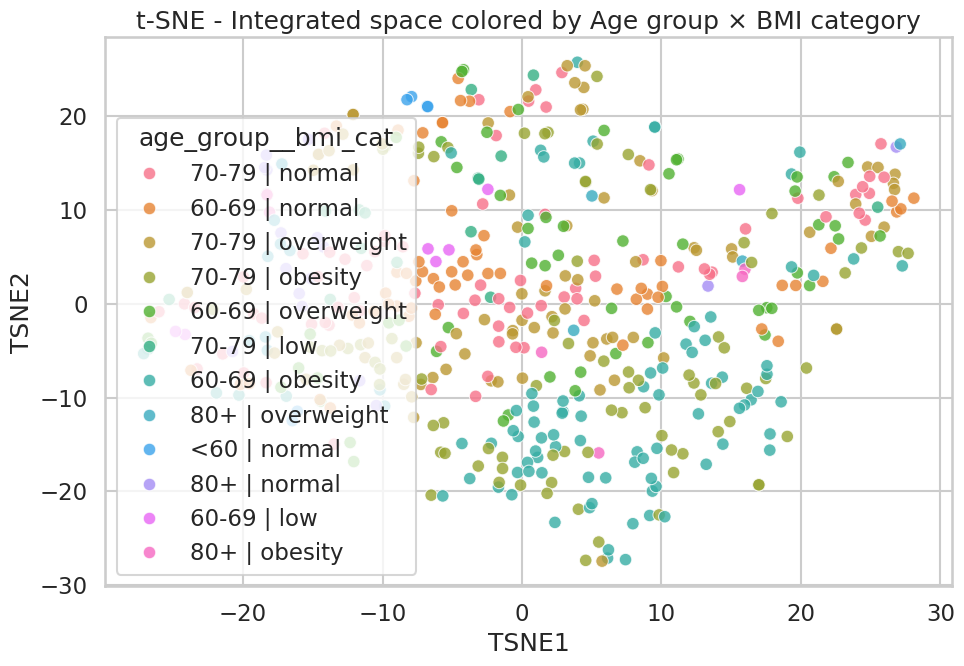

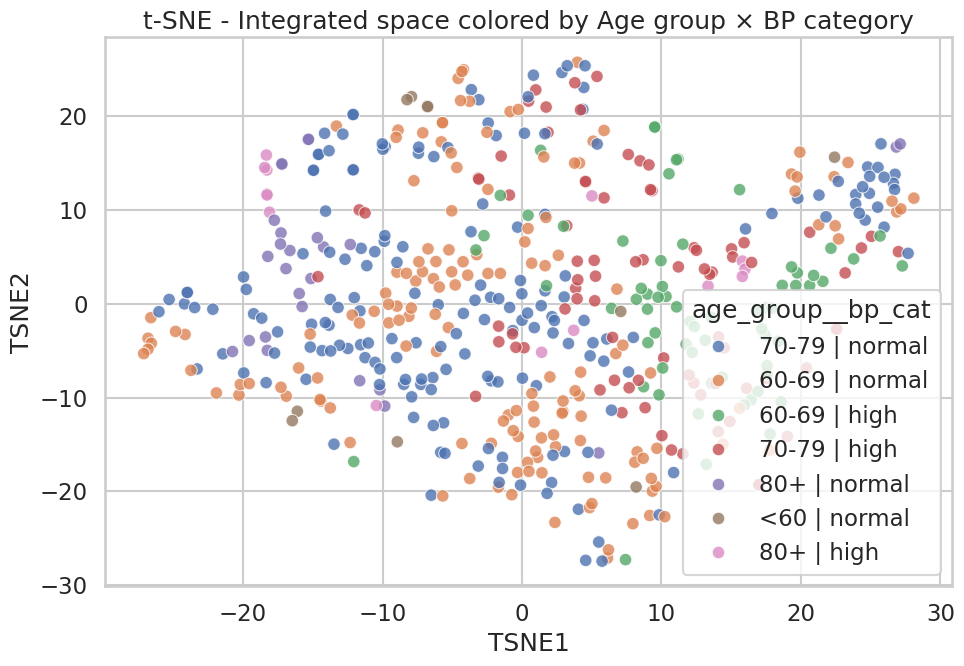

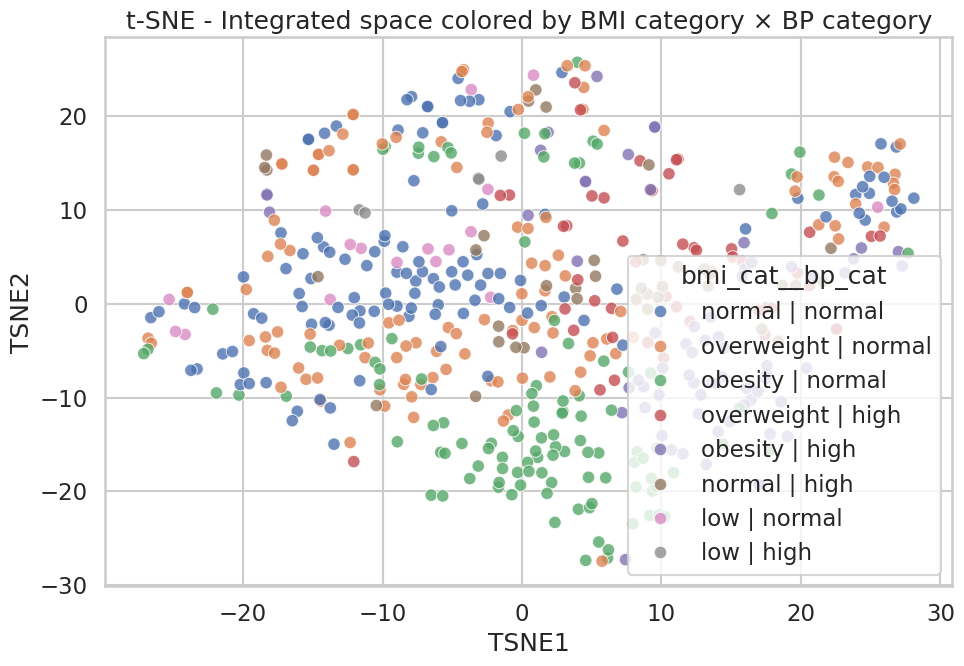

In [84]:
for group_col in combined_double_cols:
    plot_embedding_by_combined_category(
        df_in=tsne_int_df,
        x_col="TSNE1",
        y_col="TSNE2",
        group_col=group_col,
        title_prefix="t-SNE - Integrated space",
        filename_prefix="tsne_integrated",
        min_count=5
    )

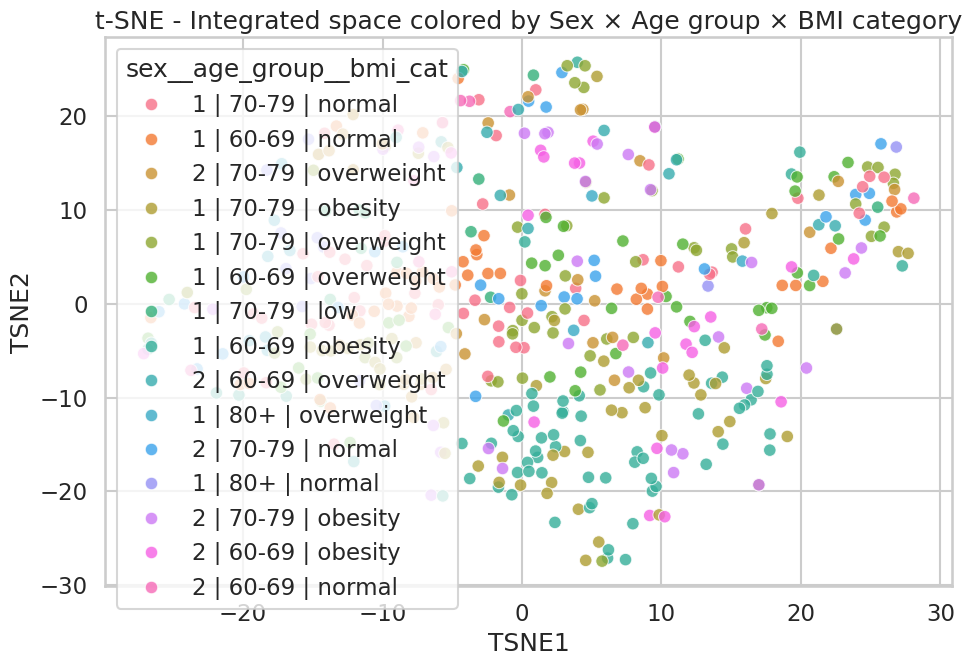

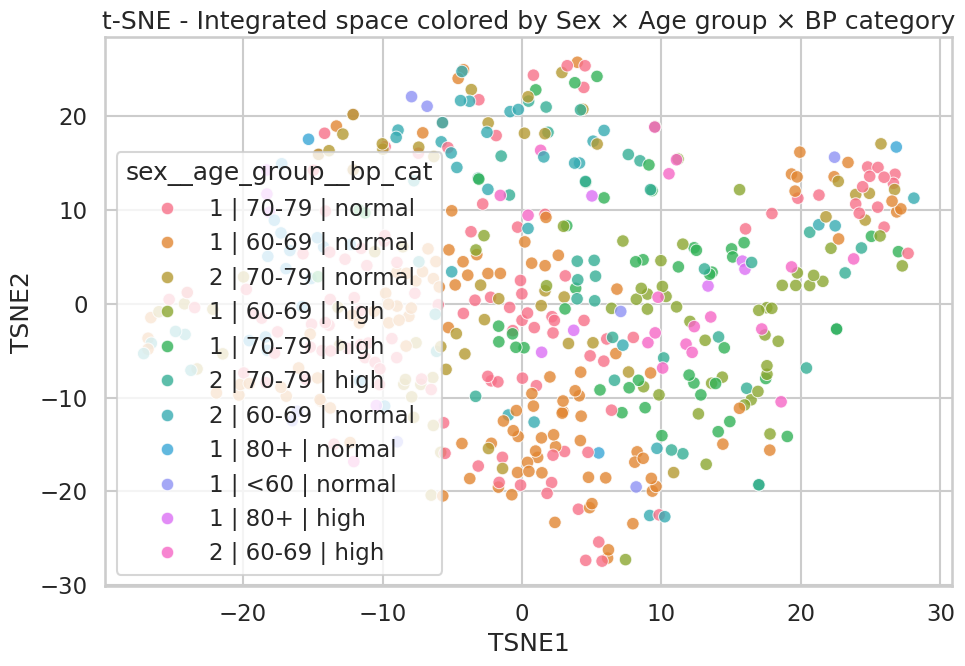

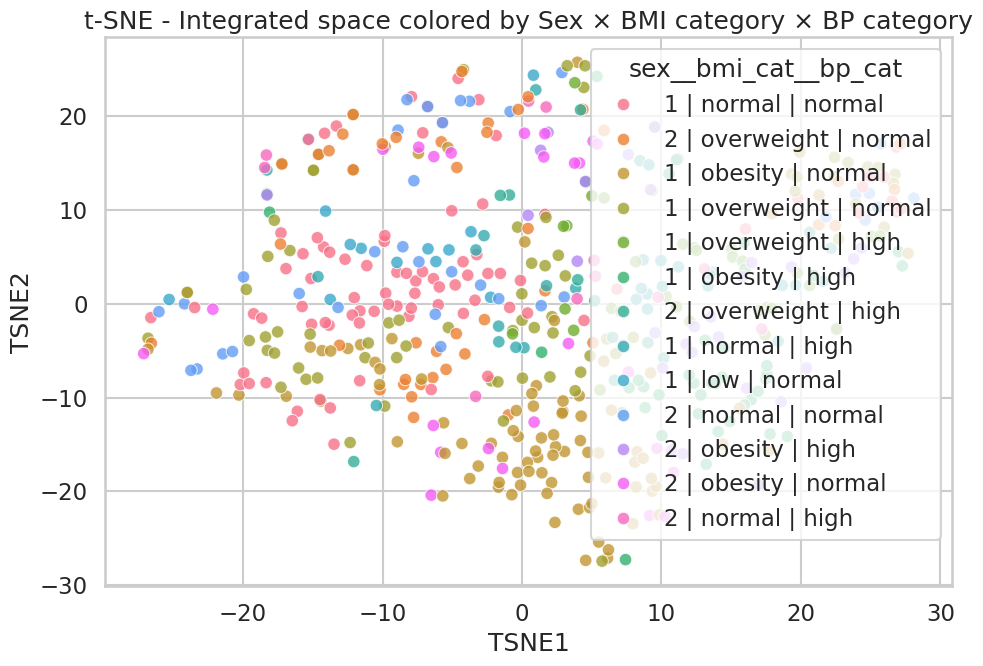

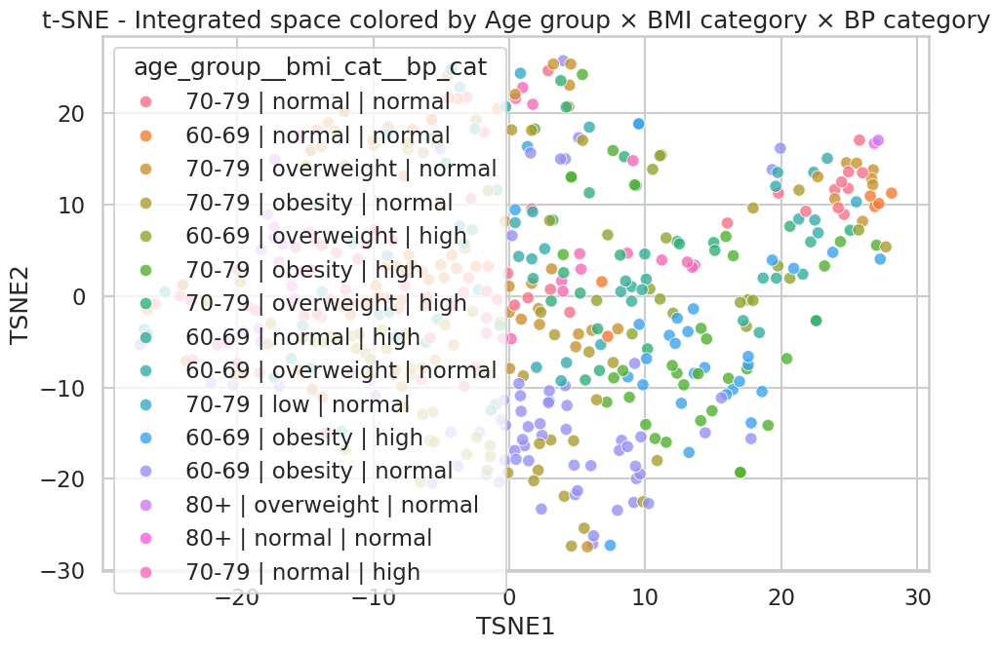

In [85]:
for group_col in combined_triple_cols:
    plot_embedding_by_combined_category(
        df_in=tsne_int_df,
        x_col="TSNE1",
        y_col="TSNE2",
        group_col=group_col,
        title_prefix="t-SNE - Integrated space",
        filename_prefix="tsne_integrated",
        min_count=8
    )

In [86]:
def compute_embedding_centroids(df_in, x_col, y_col, group_col, min_count=5):
    if group_col not in df_in.columns:
        return pd.DataFrame()

    tmp = df_in[[x_col, y_col, group_col]].dropna().copy()
    counts = tmp[group_col].value_counts()
    valid_levels = counts[counts >= min_count].index.tolist()
    tmp = tmp[tmp[group_col].isin(valid_levels)].copy()

    if tmp.empty:
        return pd.DataFrame()

    centroids = (
        tmp.groupby(group_col)[[x_col, y_col]]
        .mean()
        .reset_index()
    )
    centroids["n"] = centroids[group_col].map(counts)
    return centroids

In [87]:
centroid_tables = []

for group_col in combined_double_cols:
    cent = compute_embedding_centroids(scores_hrv, "PC1", "PC2", group_col, min_count=5)
    if not cent.empty:
        cent["embedding"] = "PCA_HRV"
        cent["grouping"] = group_col
        centroid_tables.append(cent)

centroids_pca_hrv_double = pd.concat(centroid_tables, ignore_index=True) if centroid_tables else pd.DataFrame()
centroids_pca_hrv_double.head()

,sex__age_group,PC1,PC2,n,embedding,grouping,sex__bmi_cat,sex__bp_cat,age_group__bmi_cat,age_group__bp_cat,bmi_cat__bp_cat
0,1 | 60-69,0.439569,0.048349,162,PCA_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN
1,1 | 70-79,0.139151,-0.050857,167,PCA_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN
2,1 | 80+,-0.521139,0.376872,29,PCA_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN
3,1 | <60,-0.278700,0.494230,8,PCA_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN
4,2 | 60-69,-0.507397,-0.199330,57,PCA_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN


In [88]:
centroid_tables = []

for group_col in combined_double_cols:
    cent = compute_embedding_centroids(scores_int, "PC1", "PC2", group_col, min_count=5)
    if not cent.empty:
        cent["embedding"] = "PCA_Integrated"
        cent["grouping"] = group_col
        centroid_tables.append(cent)

centroids_pca_int_double = pd.concat(centroid_tables, ignore_index=True) if centroid_tables else pd.DataFrame()
centroids_pca_int_double.head()

,sex__age_group,PC1,PC2,n,embedding,grouping,sex__bmi_cat,sex__bp_cat,age_group__bmi_cat,age_group__bp_cat,bmi_cat__bp_cat
0,1 | 60-69,-0.045143,0.480590,162,PCA_Integrated,sex__age_group,NaN,NaN,NaN,NaN,NaN
1,1 | 70-79,-0.228340,0.088998,167,PCA_Integrated,sex__age_group,NaN,NaN,NaN,NaN,NaN
2,1 | 80+,-0.088076,-0.525261,29,PCA_Integrated,sex__age_group,NaN,NaN,NaN,NaN,NaN
3,1 | <60,-0.878268,-0.601720,8,PCA_Integrated,sex__age_group,NaN,NaN,NaN,NaN,NaN
4,2 | 60-69,0.406835,-0.478566,57,PCA_Integrated,sex__age_group,NaN,NaN,NaN,NaN,NaN


In [89]:
if HAS_UMAP:
    centroid_tables = []

    for group_col in combined_double_cols + combined_triple_cols:
        cent = compute_embedding_centroids(umap_hrv_df, "UMAP1", "UMAP2", group_col, min_count=5 if group_col in combined_double_cols else 8)
        if not cent.empty:
            cent["embedding"] = "UMAP_HRV"
            cent["grouping"] = group_col
            centroid_tables.append(cent)

        cent = compute_embedding_centroids(umap_int_df, "UMAP1", "UMAP2", group_col, min_count=5 if group_col in combined_double_cols else 8)
        if not cent.empty:
            cent["embedding"] = "UMAP_Integrated"
            cent["grouping"] = group_col
            centroid_tables.append(cent)

    centroids_umap_all = pd.concat(centroid_tables, ignore_index=True) if centroid_tables else pd.DataFrame()
    centroids_umap_all.head()

In [90]:
centroid_tables = []

for group_col in combined_double_cols + combined_triple_cols:
    cent = compute_embedding_centroids(tsne_hrv_df, "TSNE1", "TSNE2", group_col, min_count=5 if group_col in combined_double_cols else 8)
    if not cent.empty:
        cent["embedding"] = "TSNE_HRV"
        cent["grouping"] = group_col
        centroid_tables.append(cent)

    cent = compute_embedding_centroids(tsne_int_df, "TSNE1", "TSNE2", group_col, min_count=5 if group_col in combined_double_cols else 8)
    if not cent.empty:
        cent["embedding"] = "TSNE_Integrated"
        cent["grouping"] = group_col
        centroid_tables.append(cent)

centroids_tsne_all = pd.concat(centroid_tables, ignore_index=True) if centroid_tables else pd.DataFrame()
centroids_tsne_all.head()

,sex__age_group,TSNE1,TSNE2,n,embedding,grouping,sex__bmi_cat,sex__bp_cat,age_group__bmi_cat,age_group__bp_cat,bmi_cat__bp_cat,sex__age_group__bmi_cat,sex__age_group__bp_cat,sex__bmi_cat__bp_cat,age_group__bmi_cat__bp_cat
0,1 | 60-69,3.980093,2.208755,162,TSNE_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1 | 70-79,0.958389,0.780914,167,TSNE_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1 | 80+,0.632412,5.419846,29,TSNE_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1 | <60,1.584481,2.020304,8,TSNE_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2 | 60-69,-10.382461,-10.780189,57,TSNE_HRV,sex__age_group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [91]:
if not centroids_pca_hrv_double.empty:
    centroids_pca_hrv_double.to_csv(TABLE_DIR / "centroids_pca_hrv_double.csv", index=False)

if not centroids_pca_int_double.empty:
    centroids_pca_int_double.to_csv(TABLE_DIR / "centroids_pca_integrated_double.csv", index=False)

if HAS_UMAP and not centroids_umap_all.empty:
    centroids_umap_all.to_csv(TABLE_DIR / "centroids_umap_all.csv", index=False)

if not centroids_tsne_all.empty:
    centroids_tsne_all.to_csv(TABLE_DIR / "centroids_tsne_all.csv", index=False)

In [92]:
summary_combined = {
    "n_double_groupings": len(combined_double_cols),
    "n_triple_groupings": len(combined_triple_cols),
    "double_groupings": combined_double_cols,
    "triple_groupings": combined_triple_cols,
}

pd.Series({
    "n_double_groupings": summary_combined["n_double_groupings"],
    "n_triple_groupings": summary_combined["n_triple_groupings"],
}, name="value")

n_double_groupings    6
n_triple_groupings    4
Name: value, dtype: int64

In [93]:
from itertools import combinations
from scipy.spatial.distance import euclidean

In [94]:
def compute_pairwise_centroid_distances(
    centroids_df,
    group_col,
    x_col,
    y_col
):
    """
    Compute pairwise Euclidean distances between group centroids.

    Parameters
    ----------
    centroids_df : pd.DataFrame
        DataFrame containing centroid coordinates.
    group_col : str
        Column with group labels.
    x_col : str
        First embedding coordinate.
    y_col : str
        Second embedding coordinate.

    Returns
    -------
    pd.DataFrame
        Pairwise distance table.
    """
    if centroids_df.empty or centroids_df[group_col].nunique() < 2:
        return pd.DataFrame()

    rows = []
    groups = centroids_df[group_col].tolist()

    for g1, g2 in combinations(groups, 2):
        p1 = centroids_df.loc[centroids_df[group_col] == g1, [x_col, y_col]].iloc[0].values
        p2 = centroids_df.loc[centroids_df[group_col] == g2, [x_col, y_col]].iloc[0].values

        dist = euclidean(p1, p2)

        rows.append({
            "group_a": g1,
            "group_b": g2,
            "distance": dist
        })

    return pd.DataFrame(rows)

In [95]:
def summarize_centroid_separation(
    centroids_df,
    grouping_name,
    embedding_name,
    x_col,
    y_col,
    label_col
):
    """
    Summarize centroid separation for a given grouping within an embedding.
    """
    pairwise_df = compute_pairwise_centroid_distances(
        centroids_df=centroids_df,
        group_col=label_col,
        x_col=x_col,
        y_col=y_col
    )

    if pairwise_df.empty:
        return None, pd.DataFrame()

    n_groups = centroids_df[label_col].nunique()
    n_pairs = len(pairwise_df)

    summary = {
        "embedding": embedding_name,
        "grouping": grouping_name,
        "n_groups": n_groups,
        "n_pairs": n_pairs,
        "mean_centroid_distance": pairwise_df["distance"].mean(),
        "median_centroid_distance": pairwise_df["distance"].median(),
        "min_centroid_distance": pairwise_df["distance"].min(),
        "max_centroid_distance": pairwise_df["distance"].max(),
        "std_centroid_distance": pairwise_df["distance"].std(),
        "normalized_mean_distance": pairwise_df["distance"].mean() / np.log1p(n_groups),
    }

    pairwise_df["embedding"] = embedding_name
    pairwise_df["grouping"] = grouping_name

    return summary, pairwise_df

In [96]:
ranking_rows = []
pairwise_rows = []

for group_col in combined_double_cols + combined_triple_cols:
    min_n = 5 if group_col in combined_double_cols else 8

    cent = compute_embedding_centroids(
        scores_hrv,
        "PC1",
        "PC2",
        group_col,
        min_count=min_n
    )

    if not cent.empty:
        summary, pairwise_df = summarize_centroid_separation(
            centroids_df=cent,
            grouping_name=group_col,
            embedding_name="PCA_HRV",
            x_col="PC1",
            y_col="PC2",
            label_col=group_col
        )

        if summary is not None:
            ranking_rows.append(summary)
            pairwise_rows.append(pairwise_df)

ranking_pca_hrv_df = pd.DataFrame(ranking_rows)
pairwise_pca_hrv_df = pd.concat(pairwise_rows, ignore_index=True) if pairwise_rows else pd.DataFrame()

ranking_pca_hrv_df.sort_values("mean_centroid_distance", ascending=False)

,embedding,grouping,n_groups,n_pairs,mean_centroid_distance,median_centroid_distance,min_centroid_distance,max_centroid_distance,std_centroid_distance,normalized_mean_distance
0,PCA_HRV,sex__age_group,7,21,0.782352,0.760756,0.269350,1.734704,0.376743,0.376232
3,PCA_HRV,age_group__bmi_cat,12,66,0.767291,0.756054,0.115560,1.571431,0.403887,0.299145
6,PCA_HRV,sex__age_group__bmi_cat,15,105,0.765061,0.719830,0.084021,1.671400,0.393828,0.275937
1,PCA_HRV,sex__bmi_cat,8,28,0.715400,0.751686,0.072895,1.665811,0.508090,0.325593
9,PCA_HRV,age_group__bmi_cat__bp_cat,15,105,0.621234,0.540332,0.116422,1.620875,0.350245,0.224063
8,PCA_HRV,sex__bmi_cat__bp_cat,13,78,0.618106,0.587086,0.044220,1.297967,0.372396,0.234215
7,PCA_HRV,sex__age_group__bp_cat,11,55,0.601352,0.586856,0.112809,1.211325,0.284368,0.242002
4,PCA_HRV,age_group__bp_cat,7,21,0.586663,0.523517,0.155304,1.166787,0.321193,0.282126
5,PCA_HRV,bmi_cat__bp_cat,8,28,0.515776,0.311215,0.031101,1.471816,0.478007,0.234740
2,PCA_HRV,sex__bp_cat,4,6,0.491873,0.691296,0.015830,0.705996,0.322548,0.305618


In [97]:
ranking_rows = []
pairwise_rows = []

for group_col in combined_double_cols + combined_triple_cols:
    min_n = 5 if group_col in combined_double_cols else 8

    cent = compute_embedding_centroids(
        scores_int,
        "PC1",
        "PC2",
        group_col,
        min_count=min_n
    )

    if not cent.empty:
        summary, pairwise_df = summarize_centroid_separation(
            centroids_df=cent,
            grouping_name=group_col,
            embedding_name="PCA_Integrated",
            x_col="PC1",
            y_col="PC2",
            label_col=group_col
        )

        if summary is not None:
            ranking_rows.append(summary)
            pairwise_rows.append(pairwise_df)

ranking_pca_int_df = pd.DataFrame(ranking_rows)
pairwise_pca_int_df = pd.concat(pairwise_rows, ignore_index=True) if pairwise_rows else pd.DataFrame()

ranking_pca_int_df.sort_values("mean_centroid_distance", ascending=False)

,embedding,grouping,n_groups,n_pairs,mean_centroid_distance,median_centroid_distance,min_centroid_distance,max_centroid_distance,std_centroid_distance,normalized_mean_distance
2,PCA_Integrated,sex__bp_cat,4,6,2.113939,2.704756,0.768780,2.859926,1.026809,1.313464
8,PCA_Integrated,sex__bmi_cat__bp_cat,13,78,1.883576,2.019003,0.070288,3.784621,1.095732,0.713731
5,PCA_Integrated,bmi_cat__bp_cat,8,28,1.881706,2.017330,0.179988,3.622654,1.088055,0.856401
4,PCA_Integrated,age_group__bp_cat,7,21,1.870980,2.515937,0.191236,3.401210,1.152299,0.899751
9,PCA_Integrated,age_group__bmi_cat__bp_cat,15,105,1.829394,1.882848,0.152975,3.714721,1.196656,0.659814
7,PCA_Integrated,sex__age_group__bp_cat,11,55,1.829148,2.342086,0.246672,3.595413,1.140092,0.736103
3,PCA_Integrated,age_group__bmi_cat,12,66,1.203347,1.150288,0.237175,3.001555,0.603420,0.469150
1,PCA_Integrated,sex__bmi_cat,8,28,1.144493,1.113267,0.146833,2.103038,0.539445,0.520881
6,PCA_Integrated,sex__age_group__bmi_cat,15,105,0.996145,0.994977,0.099022,2.008442,0.440128,0.359284
0,PCA_Integrated,sex__age_group,7,21,0.906856,0.851807,0.205066,1.668153,0.390082,0.436105


In [98]:
if HAS_UMAP:
    ranking_rows = []
    pairwise_rows = []

    for group_col in combined_double_cols + combined_triple_cols:
        min_n = 5 if group_col in combined_double_cols else 8

        cent = compute_embedding_centroids(
            umap_hrv_df,
            "UMAP1",
            "UMAP2",
            group_col,
            min_count=min_n
        )

        if not cent.empty:
            summary, pairwise_df = summarize_centroid_separation(
                centroids_df=cent,
                grouping_name=group_col,
                embedding_name="UMAP_HRV",
                x_col="UMAP1",
                y_col="UMAP2",
                label_col=group_col
            )

            if summary is not None:
                ranking_rows.append(summary)
                pairwise_rows.append(pairwise_df)

        cent = compute_embedding_centroids(
            umap_int_df,
            "UMAP1",
            "UMAP2",
            group_col,
            min_count=min_n
        )

        if not cent.empty:
            summary, pairwise_df = summarize_centroid_separation(
                centroids_df=cent,
                grouping_name=group_col,
                embedding_name="UMAP_Integrated",
                x_col="UMAP1",
                y_col="UMAP2",
                label_col=group_col
            )

            if summary is not None:
                ranking_rows.append(summary)
                pairwise_rows.append(pairwise_df)

    ranking_umap_df = pd.DataFrame(ranking_rows)
    pairwise_umap_df = pd.concat(pairwise_rows, ignore_index=True) if pairwise_rows else pd.DataFrame()

ranking_umap_df.sort_values(["embedding", "mean_centroid_distance"], ascending=[True, False])

,embedding,grouping,n_groups,n_pairs,mean_centroid_distance,median_centroid_distance,min_centroid_distance,max_centroid_distance,std_centroid_distance,normalized_mean_distance
2,UMAP_HRV,sex__bmi_cat,8,28,3.322170,3.247879,0.104044,8.456657,2.444037,1.511985
0,UMAP_HRV,sex__age_group,7,21,2.793212,2.734817,0.393980,5.656587,1.765492,1.343251
12,UMAP_HRV,sex__age_group__bmi_cat,15,105,2.679377,2.253498,0.161159,6.638768,1.802721,0.966381
4,UMAP_HRV,sex__bp_cat,4,6,2.519891,2.943226,0.304828,4.092853,1.523918,1.565696
14,UMAP_HRV,sex__age_group__bp_cat,11,55,2.457881,2.008139,0.167623,7.626025,1.816541,0.989124
16,UMAP_HRV,sex__bmi_cat__bp_cat,13,78,2.208147,1.841669,0.214034,5.481634,1.428406,0.836718
6,UMAP_HRV,age_group__bmi_cat,12,66,1.933138,1.494949,0.286627,5.788060,1.415775,0.753675
8,UMAP_HRV,age_group__bp_cat,7,21,1.580316,1.510850,0.079697,3.957293,1.006692,0.759971
10,UMAP_HRV,bmi_cat__bp_cat,8,28,1.490335,0.902729,0.271053,4.537585,1.273310,0.678280
18,UMAP_HRV,age_group__bmi_cat__bp_cat,15,105,1.461668,1.321324,0.168906,3.707922,0.772496,0.527185


In [99]:
ranking_rows = []
pairwise_rows = []

for group_col in combined_double_cols + combined_triple_cols:
    min_n = 5 if group_col in combined_double_cols else 8

    cent = compute_embedding_centroids(
        tsne_hrv_df,
        "TSNE1",
        "TSNE2",
        group_col,
        min_count=min_n
    )

    if not cent.empty:
        summary, pairwise_df = summarize_centroid_separation(
            centroids_df=cent,
            grouping_name=group_col,
            embedding_name="TSNE_HRV",
            x_col="TSNE1",
            y_col="TSNE2",
            label_col=group_col
        )

        if summary is not None:
            ranking_rows.append(summary)
            pairwise_rows.append(pairwise_df)

    cent = compute_embedding_centroids(
        tsne_int_df,
        "TSNE1",
        "TSNE2",
        group_col,
        min_count=min_n
    )

    if not cent.empty:
        summary, pairwise_df = summarize_centroid_separation(
            centroids_df=cent,
            grouping_name=group_col,
            embedding_name="TSNE_Integrated",
            x_col="TSNE1",
            y_col="TSNE2",
            label_col=group_col
        )

        if summary is not None:
            ranking_rows.append(summary)
            pairwise_rows.append(pairwise_df)

ranking_tsne_df = pd.DataFrame(ranking_rows)
pairwise_tsne_df = pd.concat(pairwise_rows, ignore_index=True) if pairwise_rows else pd.DataFrame()

ranking_tsne_df.sort_values(["embedding", "mean_centroid_distance"], ascending=[True, False])

,embedding,grouping,n_groups,n_pairs,mean_centroid_distance,median_centroid_distance,min_centroid_distance,max_centroid_distance,std_centroid_distance,normalized_mean_distance
2,TSNE_HRV,sex__bmi_cat,8,28,11.969951,10.906552,0.297023,30.232550,8.723513,5.447759
0,TSNE_HRV,sex__age_group,7,21,10.137603,9.648787,1.388553,19.590012,6.014907,4.875156
12,TSNE_HRV,sex__age_group__bmi_cat,15,105,10.013069,8.886869,0.973572,23.018238,5.775051,3.611451
4,TSNE_HRV,sex__bp_cat,4,6,8.643218,10.121783,0.958118,13.919179,5.213263,5.370333
14,TSNE_HRV,sex__age_group__bp_cat,11,55,8.460198,7.415566,0.373318,26.069866,6.499629,3.404634
16,TSNE_HRV,sex__bmi_cat__bp_cat,13,78,8.182396,7.554079,0.722471,20.419924,4.911262,3.100499
6,TSNE_HRV,age_group__bmi_cat,12,66,6.811695,6.249295,0.962176,17.305298,3.766251,2.655684
10,TSNE_HRV,bmi_cat__bp_cat,8,28,5.788368,3.567345,0.845266,17.293371,4.962873,2.634400
18,TSNE_HRV,age_group__bmi_cat__bp_cat,15,105,5.771280,5.181795,0.564601,13.210574,3.081592,2.081549
8,TSNE_HRV,age_group__bp_cat,7,21,4.855089,5.323893,0.555324,11.467512,2.959515,2.334804


In [100]:
ranking_frames = []

if not ranking_pca_hrv_df.empty:
    ranking_frames.append(ranking_pca_hrv_df)

if not ranking_pca_int_df.empty:
    ranking_frames.append(ranking_pca_int_df)

if HAS_UMAP and not ranking_umap_df.empty:
    ranking_frames.append(ranking_umap_df)

if not ranking_tsne_df.empty:
    ranking_frames.append(ranking_tsne_df)

ranking_all_df = pd.concat(ranking_frames, ignore_index=True) if ranking_frames else pd.DataFrame()

if not ranking_all_df.empty:
    ranking_all_df["grouping_pretty"] = ranking_all_df["grouping"].map(pretty_combined_label)

ranking_all_df.sort_values(
    ["embedding", "mean_centroid_distance"],
    ascending=[True, False]
)

,embedding,grouping,n_groups,n_pairs,mean_centroid_distance,median_centroid_distance,min_centroid_distance,max_centroid_distance,std_centroid_distance,normalized_mean_distance,grouping_pretty
0,PCA_HRV,sex__age_group,7,21,0.782352,0.760756,0.269350,1.734704,0.376743,0.376232,Sex × Age group
3,PCA_HRV,age_group__bmi_cat,12,66,0.767291,0.756054,0.115560,1.571431,0.403887,0.299145,Age group × BMI category
6,PCA_HRV,sex__age_group__bmi_cat,15,105,0.765061,0.719830,0.084021,1.671400,0.393828,0.275937,Sex × Age group × BMI category
1,PCA_HRV,sex__bmi_cat,8,28,0.715400,0.751686,0.072895,1.665811,0.508090,0.325593,Sex × BMI category
9,PCA_HRV,age_group__bmi_cat__bp_cat,15,105,0.621234,0.540332,0.116422,1.620875,0.350245,0.224063,Age group × BMI category × BP category
8,PCA_HRV,sex__bmi_cat__bp_cat,13,78,0.618106,0.587086,0.044220,1.297967,0.372396,0.234215,Sex × BMI category × BP category
7,PCA_HRV,sex__age_group__bp_cat,11,55,0.601352,0.586856,0.112809,1.211325,0.284368,0.242002,Sex × Age group × BP category
4,PCA_HRV,age_group__bp_cat,7,21,0.586663,0.523517,0.155304,1.166787,0.321193,0.282126,Age group × BP category
5,PCA_HRV,bmi_cat__bp_cat,8,28,0.515776,0.311215,0.031101,1.471816,0.478007,0.234740,BMI category × BP category
2,PCA_HRV,sex__bp_cat,4,6,0.491873,0.691296,0.015830,0.705996,0.322548,0.305618,Sex × BP category


In [101]:
if not ranking_pca_hrv_df.empty:
    ranking_pca_hrv_df.to_csv(TABLE_DIR / "ranking_centroid_separation_pca_hrv.csv", index=False)

if not ranking_pca_int_df.empty:
    ranking_pca_int_df.to_csv(TABLE_DIR / "ranking_centroid_separation_pca_integrated.csv", index=False)

if HAS_UMAP and not ranking_umap_df.empty:
    ranking_umap_df.to_csv(TABLE_DIR / "ranking_centroid_separation_umap.csv", index=False)

if not ranking_tsne_df.empty:
    ranking_tsne_df.to_csv(TABLE_DIR / "ranking_centroid_separation_tsne.csv", index=False)

if not ranking_all_df.empty:
    ranking_all_df.to_csv(TABLE_DIR / "ranking_centroid_separation_all_embeddings.csv", index=False)

In [102]:
if not pairwise_pca_hrv_df.empty:
    pairwise_pca_hrv_df.to_csv(TABLE_DIR / "pairwise_centroid_distances_pca_hrv.csv", index=False)

if not pairwise_pca_int_df.empty:
    pairwise_pca_int_df.to_csv(TABLE_DIR / "pairwise_centroid_distances_pca_integrated.csv", index=False)

if HAS_UMAP and not pairwise_umap_df.empty:
    pairwise_umap_df.to_csv(TABLE_DIR / "pairwise_centroid_distances_umap.csv", index=False)

if not pairwise_tsne_df.empty:
    pairwise_tsne_df.to_csv(TABLE_DIR / "pairwise_centroid_distances_tsne.csv", index=False)

In [104]:
if not ranking_all_df.empty:
    top_groupings_by_embedding = (
        ranking_all_df
        .sort_values(["embedding", "mean_centroid_distance"], ascending=[True, False])
        .groupby("embedding")
        .head(10)
        .copy()
    )

    top_groupings_by_embedding["grouping_pretty"] = top_groupings_by_embedding["grouping"].map(pretty_combined_label)
top_groupings_by_embedding

,embedding,grouping,n_groups,n_pairs,mean_centroid_distance,median_centroid_distance,min_centroid_distance,max_centroid_distance,std_centroid_distance,normalized_mean_distance,grouping_pretty
0,PCA_HRV,sex__age_group,7,21,0.782352,0.760756,0.269350,1.734704,0.376743,0.376232,Sex × Age group
3,PCA_HRV,age_group__bmi_cat,12,66,0.767291,0.756054,0.115560,1.571431,0.403887,0.299145,Age group × BMI category
6,PCA_HRV,sex__age_group__bmi_cat,15,105,0.765061,0.719830,0.084021,1.671400,0.393828,0.275937,Sex × Age group × BMI category
1,PCA_HRV,sex__bmi_cat,8,28,0.715400,0.751686,0.072895,1.665811,0.508090,0.325593,Sex × BMI category
9,PCA_HRV,age_group__bmi_cat__bp_cat,15,105,0.621234,0.540332,0.116422,1.620875,0.350245,0.224063,Age group × BMI category × BP category
8,PCA_HRV,sex__bmi_cat__bp_cat,13,78,0.618106,0.587086,0.044220,1.297967,0.372396,0.234215,Sex × BMI category × BP category
7,PCA_HRV,sex__age_group__bp_cat,11,55,0.601352,0.586856,0.112809,1.211325,0.284368,0.242002,Sex × Age group × BP category
4,PCA_HRV,age_group__bp_cat,7,21,0.586663,0.523517,0.155304,1.166787,0.321193,0.282126,Age group × BP category
5,PCA_HRV,bmi_cat__bp_cat,8,28,0.515776,0.311215,0.031101,1.471816,0.478007,0.234740,BMI category × BP category
2,PCA_HRV,sex__bp_cat,4,6,0.491873,0.691296,0.015830,0.705996,0.322548,0.305618,Sex × BP category


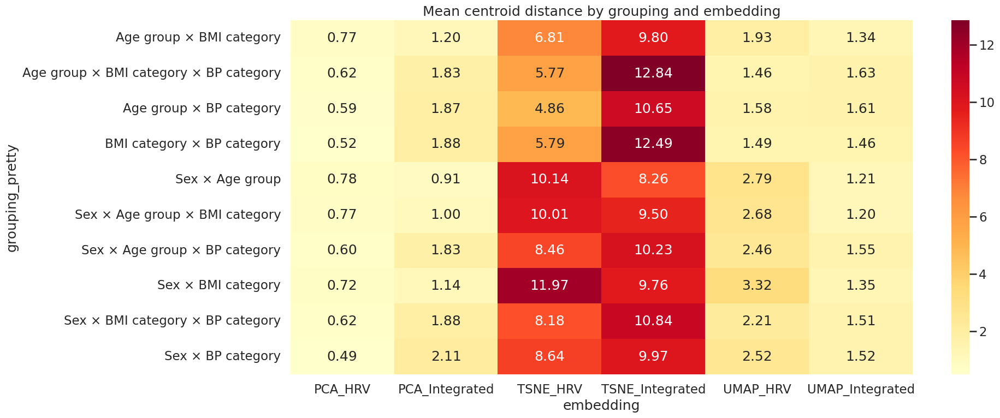

In [108]:
if not ranking_all_df.empty:
    heatmap_df = ranking_all_df.pivot_table(
        index="grouping_pretty",
        columns="embedding",
        values="mean_centroid_distance",
        aggfunc="mean"
    )

    plt.figure(figsize=(20, max(5, 0.8 * len(heatmap_df))))
    sns.heatmap(heatmap_df, annot=True, fmt=".2f", cmap="YlOrRd")
    plt.title("Mean centroid distance by grouping and embedding")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "heatmap_centroid_separation_rankings.png", dpi=300)
    plt.show()

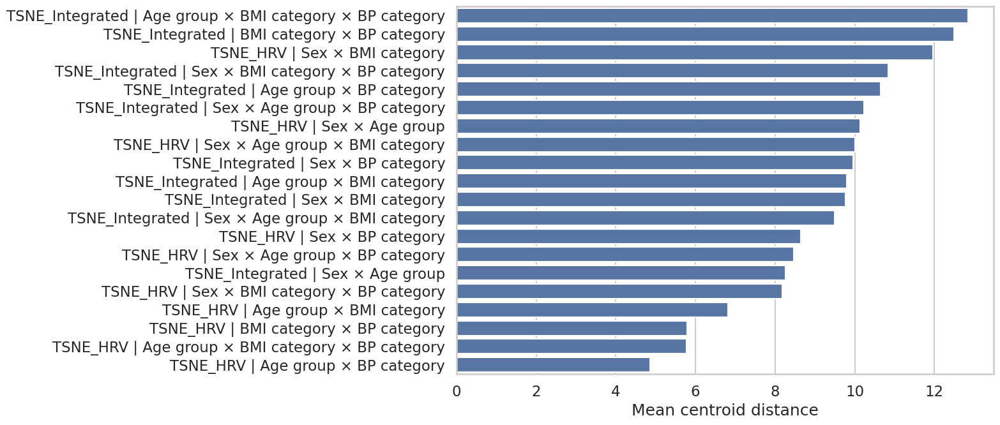

In [110]:
if not ranking_all_df.empty:
    top_global = ranking_all_df.sort_values("mean_centroid_distance", ascending=False).head(20).copy()
    top_global["label"] = top_global["embedding"] + " | " + top_global["grouping_pretty"]

    plt.figure(figsize=(16, max(6, 0.35 * len(top_global))))
    sns.barplot(data=top_global, y="label", x="mean_centroid_distance")
    plt.xlabel("Mean centroid distance")
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "top_global_centroid_separation.png", dpi=300)
    plt.show()

In [111]:
if not ranking_all_df.empty:
    ranking_all_df.sort_values(
        ["embedding", "normalized_mean_distance"],
        ascending=[True, False]
    )

In [112]:
if not ranking_all_df.empty:
    top_norm = (
        ranking_all_df
        .sort_values(["embedding", "normalized_mean_distance"], ascending=[True, False])
        .groupby("embedding")
        .head(10)
        .copy()
    )
    top_norm["grouping_pretty"] = top_norm["grouping"].map(pretty_combined_label)
top_norm

,embedding,grouping,n_groups,n_pairs,mean_centroid_distance,median_centroid_distance,min_centroid_distance,max_centroid_distance,std_centroid_distance,normalized_mean_distance,grouping_pretty
0,PCA_HRV,sex__age_group,7,21,0.782352,0.760756,0.269350,1.734704,0.376743,0.376232,Sex × Age group
1,PCA_HRV,sex__bmi_cat,8,28,0.715400,0.751686,0.072895,1.665811,0.508090,0.325593,Sex × BMI category
2,PCA_HRV,sex__bp_cat,4,6,0.491873,0.691296,0.015830,0.705996,0.322548,0.305618,Sex × BP category
3,PCA_HRV,age_group__bmi_cat,12,66,0.767291,0.756054,0.115560,1.571431,0.403887,0.299145,Age group × BMI category
4,PCA_HRV,age_group__bp_cat,7,21,0.586663,0.523517,0.155304,1.166787,0.321193,0.282126,Age group × BP category
6,PCA_HRV,sex__age_group__bmi_cat,15,105,0.765061,0.719830,0.084021,1.671400,0.393828,0.275937,Sex × Age group × BMI category
7,PCA_HRV,sex__age_group__bp_cat,11,55,0.601352,0.586856,0.112809,1.211325,0.284368,0.242002,Sex × Age group × BP category
5,PCA_HRV,bmi_cat__bp_cat,8,28,0.515776,0.311215,0.031101,1.471816,0.478007,0.234740,BMI category × BP category
8,PCA_HRV,sex__bmi_cat__bp_cat,13,78,0.618106,0.587086,0.044220,1.297967,0.372396,0.234215,Sex × BMI category × BP category
9,PCA_HRV,age_group__bmi_cat__bp_cat,15,105,0.621234,0.540332,0.116422,1.620875,0.350245,0.224063,Age group × BMI category × BP category


In [113]:
if not ranking_all_df.empty:
    executive_ranking = (
        ranking_all_df
        .sort_values("mean_centroid_distance", ascending=False)
        .iloc[0]
    )

    executive_summary = {
        "top_embedding": executive_ranking["embedding"],
        "top_grouping": executive_ranking["grouping"],
        "top_grouping_pretty": executive_ranking["grouping_pretty"],
        "top_mean_centroid_distance": executive_ranking["mean_centroid_distance"],
        "top_normalized_mean_distance": executive_ranking["normalized_mean_distance"],
        "top_n_groups": executive_ranking["n_groups"],
    }

pd.Series(executive_summary, name="value")

top_embedding                                          TSNE_Integrated
top_grouping                                age_group__bmi_cat__bp_cat
top_grouping_pretty             Age group × BMI category × BP category
top_mean_centroid_distance                                   12.842827
top_normalized_mean_distance                                  4.632071
top_n_groups                                                        15
Name: value, dtype: object